# 11 — Deep Learning Dataset Preparation and Leakage Audit

## Objectives

1. Inspect existing batting and bowling datasets.
2. Validate target variables and feature columns.
3. Analyze missing values and duplicate records.
4. Audit potential data leakage.
5. Preserve chronological train, validation and test splits.
6. Prepare datasets for TensorFlow/Keras models.

## Modeling Strategy

- Framework: TensorFlow / Keras
- Problem type: Supervised regression
- Validation: Chronological
- Evaluation: MAE, RMSE, R²
- Benchmark: Existing Machine Learning models

No existing datasets or ML model artifacts will be overwritten.

In [24]:
# ============================================================
# 1. PROJECT SETUP AND DATASET INSPECTION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import os

# Project directory
PROJECT_ROOT = Path(
    r"D:\Git\Personal\ipl-player-performance-v2"
)

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "features"
MODEL_DIR = PROJECT_ROOT / "models"

# Dataset paths
BATTING_DATA_PATH = DATA_DIR / "batting_model_dataset.csv"
BOWLING_DATA_PATH = DATA_DIR / "bowling_model_dataset.csv"

# Verify paths
print("=" * 70)
print("PROJECT CONFIGURATION")
print("=" * 70)

print("Project root:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())

print("\nBatting dataset exists:", BATTING_DATA_PATH.exists())
print("Bowling dataset exists:", BOWLING_DATA_PATH.exists())

assert PROJECT_ROOT.exists(), "Project directory not found."
assert BATTING_DATA_PATH.exists(), "Batting dataset not found."
assert BOWLING_DATA_PATH.exists(), "Bowling dataset not found."

# Load datasets
batting_df = pd.read_csv(BATTING_DATA_PATH)
bowling_df = pd.read_csv(BOWLING_DATA_PATH)

# Dataset inspection function
def inspect_dataset(df, name):

    print("\n" + "=" * 70)
    print(f"{name.upper()} DATASET")
    print("=" * 70)

    print("Shape:", df.shape)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum().sort_values(
        ascending=False
    ).head(15))

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nFirst 5 records:")
    display(df.head())

# Inspect both datasets
inspect_dataset(batting_df, "Batting")
inspect_dataset(bowling_df, "Bowling")

print("\n" + "=" * 70)
print("DATASET INSPECTION COMPLETED")
print("=" * 70)

PROJECT CONFIGURATION
Project root: D:\Git\Personal\ipl-player-performance-v2
Project exists: True

Batting dataset exists: True
Bowling dataset exists: True

BATTING DATASET
Shape: (18083, 56)
Rows: 18083
Columns: 56

Column names:
['match_id', 'player', 'is_super_over', 'batting_team', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'batting_average', 'innings_batted', 'not_out_innings', 'season', 'date', 'match_type', 'target_next_match_runs_scored', 'target_next_match_balls_faced', 'target_next_match_fours', 'target_next_match_sixes', 'target_next_match_strike_rate', 'target_next_match_dismissals', 'previous_match_date', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expanding_mean

,match_id,player,is_super_over,batting_team,runs_scored,balls_faced,fours,sixes,dismissals,retired_hurt_count,...,strike_rate_rolling_mean_3,strike_rate_rolling_mean_5,strike_rate_rolling_mean_10,strike_rate_expanding_mean,previous_dismissals,dismissals_rolling_mean_3,dismissals_rolling_mean_5,dismissals_rolling_mean_10,dismissals_expanding_mean,matches_played_before
0,548346,A Ashish Reddy,False,Deccan Chargers,10,10,0,1,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,548352,A Ashish Reddy,False,Deccan Chargers,3,3,0,0,1,0,...,100.0,100.0,100.0,100.0,1.0,1.000000,1.00,1.00,1.00,1
2,548359,A Ashish Reddy,False,Deccan Chargers,8,8,1,0,1,0,...,100.0,100.0,100.0,100.0,1.0,1.000000,1.00,1.00,1.00,2
3,548373,A Ashish Reddy,False,Deccan Chargers,10,4,2,0,0,0,...,100.0,100.0,100.0,100.0,1.0,1.000000,1.00,1.00,1.00,3
4,548376,A Ashish Reddy,False,Deccan Chargers,4,4,0,0,1,0,...,150.0,137.5,137.5,137.5,0.0,0.666667,0.75,0.75,0.75,4



BOWLING DATASET
Shape: (14123, 43)
Rows: 14123
Columns: 43

Column names:
['match_id', 'player', 'is_super_over', 'runs_conceded', 'legal_balls', 'wides_conceded', 'noballs_conceded', 'innings_bowled', 'wickets', 'overs_bowled', 'economy_rate', 'bowling_average', 'bowling_strike_rate', 'season', 'date', 'match_type', 'target_next_match_wickets', 'target_next_match_runs_conceded', 'target_next_match_legal_balls', 'target_next_match_economy_rate', 'previous_match_date', 'days_since_previous_match', 'previous_wickets', 'wickets_rolling_mean_3', 'wickets_rolling_mean_5', 'wickets_rolling_mean_10', 'wickets_expanding_mean', 'previous_runs_conceded', 'runs_conceded_rolling_mean_3', 'runs_conceded_rolling_mean_5', 'runs_conceded_rolling_mean_10', 'runs_conceded_expanding_mean', 'previous_legal_balls', 'legal_balls_rolling_mean_3', 'legal_balls_rolling_mean_5', 'legal_balls_rolling_mean_10', 'legal_balls_expanding_mean', 'previous_economy_rate', 'economy_rate_rolling_mean_3', 'economy_rate_ro

,match_id,player,is_super_over,runs_conceded,legal_balls,wides_conceded,noballs_conceded,innings_bowled,wickets,overs_bowled,...,legal_balls_rolling_mean_3,legal_balls_rolling_mean_5,legal_balls_rolling_mean_10,legal_balls_expanding_mean,previous_economy_rate,economy_rate_rolling_mean_3,economy_rate_rolling_mean_5,economy_rate_rolling_mean_10,economy_rate_expanding_mean,matches_played_before
0,548341,A Ashish Reddy,False,32,24,0,0,1,2,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,548346,A Ashish Reddy,False,11,13,1,0,1,1,2.166667,...,24.000000,24.000000,24.000000,24.000000,8.000000,8.000000,8.000000,8.000000,8.000000,1
2,548348,A Ashish Reddy,False,32,18,0,1,1,1,3.000000,...,18.500000,18.500000,18.500000,18.500000,5.076923,6.538462,6.538462,6.538462,6.538462,2
3,548352,A Ashish Reddy,False,16,12,0,1,1,1,2.000000,...,18.333333,18.333333,18.333333,18.333333,10.666667,7.914530,7.914530,7.914530,7.914530,3
4,548356,A Ashish Reddy,False,36,24,1,0,1,1,4.000000,...,14.333333,16.750000,16.750000,16.750000,8.000000,7.914530,7.935897,7.935897,7.935897,4



DATASET INSPECTION COMPLETED


In [25]:
# Compact dataset summary for DL preparation

for name, df in [
    ("BATTING", batting_df),
    ("BOWLING", bowling_df)
]:
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Shape:", df.shape)
    print("Date range:",
          pd.to_datetime(df["date"], errors="coerce").min(),
          "to",
          pd.to_datetime(df["date"], errors="coerce").max())

    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isna().sum().sum())

    targets = [
        col for col in df.columns
        if col.startswith("target_next_match_")
    ]

    print("\nTarget columns:")
    for target in targets:
        print(
            target,
            "| Missing:", df[target].isna().sum(),
            "| Mean:", round(df[target].mean(), 4)
        )

    print("\nColumn names:")
    print(df.columns.tolist())


BATTING
Shape: (18083, 56)
Date range: 2008-04-18 00:00:00 to 2026-05-29 00:00:00
Duplicate rows: 0
Missing values: 24424

Target columns:
target_next_match_runs_scored | Missing: 0 | Mean: 20.6273
target_next_match_balls_faced | Missing: 0 | Mean: 15.4139
target_next_match_fours | Missing: 0 | Mean: 1.8618
target_next_match_sixes | Missing: 0 | Mean: 0.8546
target_next_match_strike_rate | Missing: 55 | Mean: 115.8641
target_next_match_dismissals | Missing: 0 | Mean: 0.7812

Column names:
['match_id', 'player', 'is_super_over', 'batting_team', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'batting_average', 'innings_batted', 'not_out_innings', 'season', 'date', 'match_type', 'target_next_match_runs_scored', 'target_next_match_balls_faced', 'target_next_match_fours', 'target_next_match_sixes', 'target_next_match_strike_rate', 'target_next_match_dismissals', 'previous_match_date', 'days_since_previous_match', 'previous_runs_scored', '

In [26]:
# ============================================================
# 2. FEATURE-LEVEL MISSING VALUE AND SCHEMA AUDIT
# ============================================================

TARGET_PREFIX = "target_next_match_"

EXCLUDED_COLUMNS = {
    "match_id",
    "player",
    "date",
    "previous_match_date"
}

def audit_features(df, dataset_name):

    feature_columns = [
        col for col in df.columns
        if not col.startswith(TARGET_PREFIX)
        and col not in EXCLUDED_COLUMNS
    ]

    feature_df = df[feature_columns]

    print("\n" + "=" * 75)
    print(f"{dataset_name.upper()} FEATURE AUDIT")
    print("=" * 75)

    print("Total features:", len(feature_columns))
    print("Numerical features:",
          len(feature_df.select_dtypes(include=np.number).columns))
    print("Categorical features:",
          len(feature_df.select_dtypes(exclude=np.number).columns))

    # Missing-value report
    missing_report = pd.DataFrame({
        "Missing_Count": feature_df.isna().sum(),
        "Missing_Percentage": (
            feature_df.isna().mean() * 100
        ).round(2)
    })

    missing_report = missing_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )

    print("\nFEATURE MISSING VALUE REPORT")
    display(missing_report[missing_report["Missing_Count"] > 0])

    # Categorical variable inspection
    categorical_columns = feature_df.select_dtypes(
        exclude=np.number
    ).columns

    print("\nCATEGORICAL FEATURES")
    for col in categorical_columns:
        print(
            f"{col}: {feature_df[col].nunique(dropna=False)} "
            f"unique values"
        )
        print(feature_df[col].value_counts(dropna=False).head(10))

    # Binary / categorical numeric variables
    print("\nIMPORTANT NUMERIC CATEGORY CHECKS")

    for col in ["is_super_over", "season"]:
        if col in df.columns:
            print(f"\n{col}:")
            print(df[col].value_counts(dropna=False).sort_index())

    return feature_columns, missing_report


# Run audit
batting_feature_columns, batting_missing_report = audit_features(
    batting_df, "Batting"
)

bowling_feature_columns, bowling_missing_report = audit_features(
    bowling_df, "Bowling"
)

print("\nFEATURE AUDIT COMPLETED")


BATTING FEATURE AUDIT
Total features: 46
Numerical features: 42
Categorical features: 4

FEATURE MISSING VALUE REPORT


,Missing_Count,Missing_Percentage
batting_average,3962,21.91
previous_strike_rate,688,3.80
strike_rate_rolling_mean_5,636,3.52
strike_rate_rolling_mean_3,636,3.52
strike_rate_rolling_mean_10,636,3.52
strike_rate_expanding_mean,636,3.52
previous_runs_scored,634,3.51
runs_scored_rolling_mean_3,634,3.51
days_since_previous_match,634,3.51
runs_scored_rolling_mean_10,634,3.51



CATEGORICAL FEATURES
is_super_over: 1 unique values
is_super_over
False    18083
Name: count, dtype: int64
batting_team: 19 unique values
batting_team
Mumbai Indians                 2153
Kolkata Knight Riders          2025
Rajasthan Royals               1827
Chennai Super Kings            1820
Royal Challengers Bangalore    1726
Sunrisers Hyderabad            1532
Kings XI Punjab                1435
Delhi Daredevils               1185
Delhi Capitals                  894
Punjab Kings                    660
Name: count, dtype: int64
season: 19 unique values
season
2022       1133
2023       1131
2013       1115
2012       1077
2025       1077
2024       1068
2011       1022
2026        954
2009/10     891
2018        889
Name: count, dtype: int64
match_type: 1 unique values
match_type
T20    18083
Name: count, dtype: int64

IMPORTANT NUMERIC CATEGORY CHECKS

is_super_over:
is_super_over
False    18083
Name: count, dtype: int64

season:
season
2007/08     843
2009        855
2009/10     

,Missing_Count,Missing_Percentage
bowling_average,5884,41.66
bowling_strike_rate,5884,41.66
previous_economy_rate,504,3.57
legal_balls_rolling_mean_5,503,3.56
legal_balls_rolling_mean_10,503,3.56
legal_balls_expanding_mean,503,3.56
wickets_expanding_mean,503,3.56
wickets_rolling_mean_3,503,3.56
wickets_rolling_mean_5,503,3.56
days_since_previous_match,503,3.56



CATEGORICAL FEATURES
is_super_over: 1 unique values
is_super_over
False    14123
Name: count, dtype: int64
season: 19 unique values
season
2023       867
2013       853
2011       845
2012       842
2022       833
2025       823
2024       820
2026       729
2016       705
2009/10    704
Name: count, dtype: int64
match_type: 1 unique values
match_type
T20    14123
Name: count, dtype: int64

IMPORTANT NUMERIC CATEGORY CHECKS

is_super_over:
is_super_over
False    14123
Name: count, dtype: int64

season:
season
2007/08    655
2009       693
2009/10    704
2011       845
2012       842
2013       853
2014       674
2015       673
2016       705
2017       681
2018       700
2019       665
2020/21    680
2021       681
2022       833
2023       867
2024       820
2025       823
2026       729
Name: count, dtype: int64

FEATURE AUDIT COMPLETED


In [27]:
# ============================================================
# 3. CONSTANT FEATURE AND SEASON AUDIT
# ============================================================

def normalize_season(value):
    if pd.isna(value):
        return np.nan

    return int(str(value).split("/")[0])


for name, df in [
    ("Batting", batting_df),
    ("Bowling", bowling_df)
]:

    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)

    # Identify constant features
    constant_features = [
        col for col in df.columns
        if df[col].nunique(dropna=False) == 1
    ]

    print("Constant features:", constant_features)

    # Preview season normalization
    if "season" in df.columns:

        season_preview = pd.DataFrame({
            "Original_Season": df["season"].dropna().unique()
        })

        season_preview["Normalized_Season"] = (
            season_preview["Original_Season"]
            .apply(normalize_season)
        )

        season_preview = season_preview.sort_values(
            "Normalized_Season"
        )

        print("\nSeason normalization:")
        display(season_preview)

        print(
            "Normalized season missing values:",
            df["season"].apply(normalize_season).isna().sum()
        )

print("\nCONSTANT FEATURE AND SEASON AUDIT COMPLETED")


BATTING
Constant features: ['is_super_over', 'innings_batted', 'match_type']

Season normalization:


,Original_Season,Normalized_Season
9,2007/08,2007
11,2009,2009
12,2009/10,2009
13,2011,2011
0,2012,2012
1,2013,2013
14,2014,2014
2,2015,2015
3,2016,2016
10,2017,2017


Normalized season missing values: 0

BOWLING
Constant features: ['is_super_over', 'innings_bowled', 'match_type']

Season normalization:


,Original_Season,Normalized_Season
11,2007/08,2007
9,2009,2009
12,2009/10,2009
13,2011,2011
0,2012,2012
1,2013,2013
14,2014,2014
2,2015,2015
3,2016,2016
8,2017,2017


Normalized season missing values: 0

CONSTANT FEATURE AND SEASON AUDIT COMPLETED


In [28]:
# ============================================================
# 4. NUMERICAL MISSING VALUE AUDIT
# ============================================================

for name, df in [
    ("BATTING", batting_df),
    ("BOWLING", bowling_df)
]:

    print("\n" + "=" * 65)
    print(name, "— NUMERICAL FEATURE MISSING VALUES")
    print("=" * 65)

    numeric_df = df.select_dtypes(include=np.number)

    report = pd.DataFrame({
        "Missing_Count": numeric_df.isna().sum(),
        "Missing_Percentage": (
            numeric_df.isna().mean() * 100
        ).round(2)
    })

    report = report.sort_values(
        "Missing_Percentage",
        ascending=False
    )

    display(report[report["Missing_Count"] > 0])

    print("Total numerical missing values:",
          numeric_df.isna().sum().sum())

print("\nNUMERICAL MISSING VALUE AUDIT COMPLETED")


BATTING — NUMERICAL FEATURE MISSING VALUES


,Missing_Count,Missing_Percentage
batting_average,3962,21.91
previous_strike_rate,688,3.80
strike_rate_rolling_mean_5,636,3.52
strike_rate_rolling_mean_10,636,3.52
strike_rate_rolling_mean_3,636,3.52
strike_rate_expanding_mean,636,3.52
balls_faced_rolling_mean_3,634,3.51
runs_scored_expanding_mean,634,3.51
previous_balls_faced,634,3.51
previous_runs_scored,634,3.51


Total numerical missing values: 23790

BOWLING — NUMERICAL FEATURE MISSING VALUES


,Missing_Count,Missing_Percentage
bowling_strike_rate,5884,41.66
bowling_average,5884,41.66
previous_economy_rate,504,3.57
wickets_expanding_mean,503,3.56
wickets_rolling_mean_3,503,3.56
legal_balls_rolling_mean_5,503,3.56
legal_balls_rolling_mean_10,503,3.56
legal_balls_expanding_mean,503,3.56
economy_rate_rolling_mean_3,503,3.56
economy_rate_rolling_mean_5,503,3.56


Total numerical missing values: 22334

NUMERICAL MISSING VALUE AUDIT COMPLETED


In [29]:
# ============================================================
# 5. INVESTIGATE HIGH-MISSINGNESS CRICKET STATISTICS
# ============================================================

investigations = {
    "Batting": {
        "df": batting_df,
        "columns": [
            "batting_average",
            "strike_rate"
        ],
        "related": [
            "dismissals",
            "runs_scored",
            "balls_faced"
        ]
    },
    "Bowling": {
        "df": bowling_df,
        "columns": [
            "bowling_average",
            "bowling_strike_rate"
        ],
        "related": [
            "wickets",
            "runs_conceded",
            "legal_balls"
        ]
    }
}

for name, config in investigations.items():

    df = config["df"]

    print("\n" + "=" * 70)
    print(name.upper(), "— MISSING VALUE INVESTIGATION")
    print("=" * 70)

    for feature in config["columns"]:

        missing_mask = df[feature].isna()

        print(f"\nFeature: {feature}")
        print("Missing rows:", missing_mask.sum())
        print("Available rows:", (~missing_mask).sum())

        print("\nRelated statistics for missing rows:")
        display(
            df.loc[missing_mask, config["related"]]
            .describe()
            .T
        )

        print("\nRelated statistics for available rows:")
        display(
            df.loc[~missing_mask, config["related"]]
            .describe()
            .T
        )

print("\nMISSINGNESS INVESTIGATION COMPLETED")


BATTING — MISSING VALUE INVESTIGATION

Feature: batting_average
Missing rows: 3962
Available rows: 14121

Related statistics for missing rows:


,count,mean,std,min,25%,50%,75%,max
dismissals,3962.0,0.000000,0.000000,0.0,0.0,0.0,0.00,0.0
runs_scored,3962.0,24.519939,26.457613,0.0,4.0,15.0,37.00,175.0
balls_faced,3962.0,15.875315,16.119038,0.0,3.0,10.0,23.75,73.0



Related statistics for available rows:


,count,mean,std,min,25%,50%,75%,max
dismissals,14121.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
runs_scored,14121.0,19.610155,20.202833,0.0,4.0,13.0,29.0,141.0
balls_faced,14121.0,15.311876,12.679936,0.0,5.0,12.0,22.0,69.0



Feature: strike_rate
Missing rows: 57
Available rows: 18026

Related statistics for missing rows:


,count,mean,std,min,25%,50%,75%,max
dismissals,57.0,0.929825,0.257713,0.0,1.0,1.0,1.0,1.0
runs_scored,57.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
balls_faced,57.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


... (7 outputs left out)

,count,mean,std,min,25%,50%,75%,max
wickets,5884.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
runs_conceded,5884.0,25.551326,11.980787,0.0,16.0,25.0,34.0,76.0
legal_balls,5884.0,16.628314,6.802202,0.0,12.0,18.0,24.0,24.0



Related statistics for available rows:


,count,mean,std,min,25%,50%,75%,max
wickets,8239.0,1.598252,0.811143,1.0,1.0,1.0,2.0,6.0
runs_conceded,8239.0,27.689647,10.341155,0.0,20.0,27.0,34.0,69.0
legal_balls,8239.0,21.564632,4.377813,1.0,18.0,24.0,24.0,25.0



MISSINGNESS INVESTIGATION COMPLETED


In [30]:
# ============================================================
# 5. DL FEATURE SELECTION
# ============================================================

# Identifier and leakage columns
IDENTIFIER_COLUMNS = [
    "match_id",
    "player",
    "date",
    "previous_match_date"
]

CONSTANT_COLUMNS = [
    "is_super_over",
    "match_type",
    "innings_batted",
    "innings_bowled"
]

# Structurally undefined derived statistics
BATTING_DROP_COLUMNS = [
    "batting_average"
]

BOWLING_DROP_COLUMNS = [
    "bowling_average",
    "bowling_strike_rate"
]

# Target columns must never enter the input features
BATTING_TARGETS = [
    col for col in batting_df.columns
    if col.startswith("target_next_match_")
]

BOWLING_TARGETS = [
    col for col in bowling_df.columns
    if col.startswith("target_next_match_")
]


def build_candidate_features(df, drop_columns, target_columns):

    excluded = set(
        IDENTIFIER_COLUMNS
        + CONSTANT_COLUMNS
        + drop_columns
        + target_columns
    )

    return [
        col for col in df.columns
        if col not in excluded
    ]


batting_candidate_features = build_candidate_features(
    batting_df,
    BATTING_DROP_COLUMNS,
    BATTING_TARGETS
)

bowling_candidate_features = build_candidate_features(
    bowling_df,
    BOWLING_DROP_COLUMNS,
    BOWLING_TARGETS
)


print("BATTING CANDIDATE FEATURES:",
      len(batting_candidate_features))

print("BOWLING CANDIDATE FEATURES:",
      len(bowling_candidate_features))

print("\nBATTING FEATURES:")
print(batting_candidate_features)

print("\nBOWLING FEATURES:")
print(bowling_candidate_features)

print("\nTARGETS EXCLUDED FROM INPUT FEATURES:")
print("Batting:", set(batting_candidate_features) & set(BATTING_TARGETS))
print("Bowling:", set(bowling_candidate_features) & set(BOWLING_TARGETS))

BATTING CANDIDATE FEATURES: 42
BOWLING CANDIDATE FEATURES: 30

BATTING FEATURES:
['batting_team', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'not_out_innings', 'season', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expanding_mean', 'previous_fours', 'fours_rolling_mean_3', 'fours_rolling_mean_5', 'fours_rolling_mean_10', 'fours_expanding_mean', 'previous_sixes', 'sixes_rolling_mean_3', 'sixes_rolling_mean_5', 'sixes_rolling_mean_10', 'sixes_expanding_mean', 'previous_strike_rate', 'strike_rate_rolling_mean_3', 'strike_rate_rolling_mean_5', 'strike_rate_rolling_mean_10', 'strike_rate_expanding_mean', 'previous_dismissals', 'dismissals_rolling_mean_3', 'dismissals_rolling_mean_5',

In [31]:
# ============================================================
# 6. DL FEATURE TYPE AND MISSINGNESS AUDIT
# ============================================================

for name, df, features in [
    ("BATTING", batting_df, batting_candidate_features),
    ("BOWLING", bowling_df, bowling_candidate_features)
]:

    print("\n" + "=" * 70)
    print(name, "— FEATURE TYPE AUDIT")
    print("=" * 70)

    audit = pd.DataFrame({
        "Feature": features,
        "Data_Type": [str(df[col].dtype) for col in features],
        "Unique_Values": [df[col].nunique(dropna=True) for col in features],
        "Missing_Count": [df[col].isna().sum() for col in features],
        "Missing_Percentage": [
            round(df[col].isna().mean() * 100, 2)
            for col in features
        ]
    })

    display(audit)

    categorical = [
        col for col in features
        if (
            pd.api.types.is_object_dtype(df[col])
            or isinstance(df[col].dtype, pd.CategoricalDtype)
        )
    ]

    numerical = [
        col for col in features
        if col not in categorical
    ]

    print("\nCategorical features:", categorical)
    print("Numerical features:", len(numerical))

print("\nFEATURE TYPE AND MISSINGNESS AUDIT COMPLETED")


BATTING — FEATURE TYPE AUDIT


,Feature,Data_Type,Unique_Values,Missing_Count,Missing_Percentage
0,batting_team,str,19,0,0.00
1,runs_scored,int64,136,0,0.00
2,balls_faced,int64,73,0,0.00
3,fours,int64,18,0,0.00
4,sixes,int64,15,0,0.00
5,dismissals,int64,2,0,0.00
6,retired_hurt_count,int64,2,0,0.00
7,strike_rate,float64,1417,57,0.32
8,not_out_innings,int64,2,0,0.00
9,season,str,19,0,0.00



Categorical features: []
Numerical features: 42

BOWLING — FEATURE TYPE AUDIT


,Feature,Data_Type,Unique_Values,Missing_Count,Missing_Percentage
0,runs_conceded,int64,73,0,0.00
1,legal_balls,int64,26,0,0.00
2,wides_conceded,int64,14,0,0.00
3,noballs_conceded,int64,7,0,0.00
4,wickets,int64,7,0,0.00
5,overs_bowled,float64,26,0,0.00
6,economy_rate,float64,386,1,0.01
7,season,str,19,0,0.00
8,days_since_previous_match,float64,394,503,3.56
9,previous_wickets,float64,7,503,3.56



Categorical features: []
Numerical features: 30

FEATURE TYPE AND MISSINGNESS AUDIT COMPLETED


In [32]:
# ============================================================
# 7. CORRECTED FEATURE TYPE CLASSIFICATION
# ============================================================

from pandas.api.types import is_string_dtype

BATTING_CATEGORICAL = ["batting_team"]
BOWLING_CATEGORICAL = []

def prepare_feature_types(df, features, categorical_features):

    numerical_features = [
        col for col in features
        if col not in categorical_features
    ]

    # Season normalization
    if "season" in numerical_features:
        df = df.copy()
        df["season"] = (
            df["season"]
            .apply(normalize_season)
            .astype("int64")
        )

    # Verify remaining numerical features
    invalid = [
        col for col in numerical_features
        if not pd.api.types.is_numeric_dtype(df[col])
    ]

    return df, numerical_features, invalid


batting_df, batting_numerical, batting_invalid = (
    prepare_feature_types(
        batting_df,
        batting_candidate_features,
        BATTING_CATEGORICAL
    )
)

bowling_df, bowling_numerical, bowling_invalid = (
    prepare_feature_types(
        bowling_df,
        bowling_candidate_features,
        BOWLING_CATEGORICAL
    )
)

print("BATTING")
print("Categorical:", BATTING_CATEGORICAL)
print("Numerical:", len(batting_numerical))
print("Invalid numerical columns:", batting_invalid)

print("\nBOWLING")
print("Categorical:", BOWLING_CATEGORICAL)
print("Numerical:", len(bowling_numerical))
print("Invalid numerical columns:", bowling_invalid)

print("\nSEASON DATA TYPES")
print("Batting:", batting_df["season"].dtype)
print("Bowling:", bowling_df["season"].dtype)

assert not batting_invalid
assert not bowling_invalid
assert pd.api.types.is_numeric_dtype(batting_df["season"])
assert pd.api.types.is_numeric_dtype(bowling_df["season"])

print("\nCORRECTED FEATURE CLASSIFICATION PASSED")

BATTING
Categorical: ['batting_team']
Numerical: 41
Invalid numerical columns: []

BOWLING
Categorical: []
Numerical: 30
Invalid numerical columns: []

SEASON DATA TYPES
Batting: int64
Bowling: int64

CORRECTED FEATURE CLASSIFICATION PASSED


In [33]:
# ============================================================
# 8. DL FEATURE MISSING-VALUE AUDIT
# ============================================================

def missing_feature_audit(df, features, dataset_name):

    missing = df[features].isna().sum()

    audit = pd.DataFrame({
        "Feature": missing.index,
        "Missing_Count": missing.values,
        "Missing_Percentage": (
            missing.values / len(df) * 100
        ).round(2)
    })

    audit = (
        audit[audit["Missing_Count"] > 0]
        .sort_values("Missing_Count", ascending=False)
        .reset_index(drop=True)
    )

    print("=" * 65)
    print(f"{dataset_name} — DL INPUT MISSINGNESS")
    print("=" * 65)
    print(f"Total rows: {len(df)}")
    print(f"Total candidate features: {len(features)}")
    print(f"Features with missing values: {len(audit)}")
    print(f"Total missing feature values: {missing.sum()}")

    display(audit)

    return audit


batting_missing_audit = missing_feature_audit(
    batting_df,
    batting_candidate_features,
    "BATTING"
)

bowling_missing_audit = missing_feature_audit(
    bowling_df,
    bowling_candidate_features,
    "BOWLING"
)

print("\nDL MISSINGNESS AUDIT COMPLETED")

BATTING — DL INPUT MISSINGNESS
Total rows: 18083
Total candidate features: 42
Features with missing values: 32
Total missing feature values: 19773


,Feature,Missing_Count,Missing_Percentage
0,previous_strike_rate,688,3.80
1,strike_rate_rolling_mean_5,636,3.52
2,strike_rate_rolling_mean_3,636,3.52
3,strike_rate_rolling_mean_10,636,3.52
4,strike_rate_expanding_mean,636,3.52
5,days_since_previous_match,634,3.51
6,runs_scored_rolling_mean_3,634,3.51
7,previous_runs_scored,634,3.51
8,previous_fours,634,3.51
9,balls_faced_rolling_mean_5,634,3.51


BOWLING — DL INPUT MISSINGNESS
Total rows: 14123
Total candidate features: 30
Features with missing values: 22
Total missing feature values: 10565


,Feature,Missing_Count,Missing_Percentage
0,previous_economy_rate,504,3.57
1,days_since_previous_match,503,3.56
2,wickets_rolling_mean_5,503,3.56
3,wickets_rolling_mean_3,503,3.56
4,wickets_rolling_mean_10,503,3.56
5,previous_wickets,503,3.56
6,legal_balls_rolling_mean_3,503,3.56
7,wickets_expanding_mean,503,3.56
8,runs_conceded_rolling_mean_3,503,3.56
9,previous_runs_conceded,503,3.56



DL MISSINGNESS AUDIT COMPLETED


In [34]:
# ============================================================
# 9. MISSINGNESS VS PLAYER HISTORY
# ============================================================

def history_missingness_check(df, features, dataset_name):

    print("=" * 65)
    print(f"{dataset_name} — MISSINGNESS VS PLAYER HISTORY")
    print("=" * 65)

    history_col = "matches_played_before"

    # Player history distribution
    print("\nPLAYER HISTORY DISTRIBUTION")

    display(
        df[history_col]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis(history_col)
        .to_frame("Row_Count")
    )

    zero_history = df[history_col].eq(0)
    experienced = df[history_col].gt(0)

    print("\nZERO PREVIOUS MATCHES")
    print("Rows:", int(zero_history.sum()))

    missing_zero = (
        df.loc[zero_history, features]
        .isna()
        .sum()
    )

    display(
        missing_zero[missing_zero > 0]
        .sort_values(ascending=False)
        .to_frame("Missing_Count")
    )

    print("\nONE OR MORE PREVIOUS MATCHES")
    print("Rows:", int(experienced.sum()))

    missing_experienced = (
        df.loc[experienced, features]
        .isna()
        .sum()
    )

    display(
        missing_experienced[missing_experienced > 0]
        .sort_values(ascending=False)
        .to_frame("Missing_Count")
    )


# Batting
history_missingness_check(
    batting_df,
    batting_candidate_features,
    "BATTING"
)

# Bowling
history_missingness_check(
    bowling_df,
    bowling_candidate_features,
    "BOWLING"
)

print("\nHISTORY-BASED MISSINGNESS CHECK COMPLETED")

BATTING — MISSINGNESS VS PLAYER HISTORY

PLAYER HISTORY DISTRIBUTION


,Row_Count
matches_played_before,
0,634
1,571
2,524
3,482
4,443
...,...
270,2
271,2
272,2



ZERO PREVIOUS MATCHES
Rows: 634


,Missing_Count
days_since_previous_match,634
previous_runs_scored,634
runs_scored_rolling_mean_3,634
runs_scored_rolling_mean_5,634
runs_scored_expanding_mean,634
runs_scored_rolling_mean_10,634
previous_balls_faced,634
balls_faced_rolling_mean_3,634
previous_fours,634
balls_faced_rolling_mean_5,634



ONE OR MORE PREVIOUS MATCHES
Rows: 17449


,Missing_Count
strike_rate,54
previous_strike_rate,54
strike_rate_rolling_mean_3,2
strike_rate_rolling_mean_5,2
strike_rate_rolling_mean_10,2
strike_rate_expanding_mean,2


... (3 outputs left out)

,Missing_Count
days_since_previous_match,503
previous_wickets,503
wickets_rolling_mean_3,503
wickets_rolling_mean_5,503
wickets_rolling_mean_10,503
wickets_expanding_mean,503
previous_runs_conceded,503
runs_conceded_rolling_mean_3,503
runs_conceded_rolling_mean_5,503
runs_conceded_rolling_mean_10,503



ONE OR MORE PREVIOUS MATCHES
Rows: 13620


,Missing_Count
economy_rate,1
previous_economy_rate,1



HISTORY-BASED MISSINGNESS CHECK COMPLETED


## 10. Missing-Value Treatment Strategy

The missingness investigation indicates that most missing historical
features are associated with players having zero previous appearances.

Preprocessing strategy:

1. Use zero imputation for unavailable historical statistics.
2. Add missingness indicators to preserve information about unavailable history.
3. Use training-set median imputation for exceptional missing numerical values.
4. Fit all preprocessing transformations on training data only.
5. Apply the fitted transformations to validation and test data.

No rows will be removed solely because of missing input features.

## 11. Chronological Train, Validation and Test Split

A chronological split simulates real-world IPL prediction.

- Training: Historical matches used to learn model parameters.
- Validation: Later matches used for model selection and tuning.
- Testing: Most recent matches reserved for final evaluation.

Both batting and bowling datasets use the same calendar boundaries.

No random shuffling is permitted.
Rows from the same date must remain in the same split.

In [35]:
# ============================================================
# 11. CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import pandas as pd

# Shared chronological boundaries
TRAIN_END = pd.Timestamp("2022-04-11")
VALIDATION_END = pd.Timestamp("2024-05-01")
TEST_START = pd.Timestamp("2024-05-02")


def chronological_split(df, dataset_name):

    data = df.copy()

    # Ensure datetime format
    data["date"] = pd.to_datetime(data["date"], errors="coerce")

    # Validate dates
    if data["date"].isna().any():
        raise ValueError(f"{dataset_name}: Missing or invalid dates found.")

    # Sort chronologically
    data = data.sort_values("date").reset_index(drop=True)

    # Split without shuffling
    train = data[data["date"] <= TRAIN_END].copy()

    validation = data[
        (data["date"] > TRAIN_END) &
        (data["date"] <= VALIDATION_END)
    ].copy()

    test = data[data["date"] >= TEST_START].copy()

    # Verify no rows were lost
    assert len(train) + len(validation) + len(test) == len(data)

    # Verify chronological separation
    assert train["date"].max() < validation["date"].min()
    assert validation["date"].max() < test["date"].min()

    print("=" * 70)
    print(f"{dataset_name} — CHRONOLOGICAL SPLIT")
    print("=" * 70)

    split_summary = pd.DataFrame({
        "Split": ["Train", "Validation", "Test"],
        "Rows": [len(train), len(validation), len(test)],
        "Start_Date": [
            train["date"].min(),
            validation["date"].min(),
            test["date"].min()
        ],
        "End_Date": [
            train["date"].max(),
            validation["date"].max(),
            test["date"].max()
        ]
    })

    display(split_summary)

    print("Original rows:", len(data))
    print("Split rows:", len(train) + len(validation) + len(test))
    print("Rows lost:", len(data) - len(train) - len(validation) - len(test))

    return train, validation, test


# Batting split
(
    batting_train_df,
    batting_val_df,
    batting_test_df
) = chronological_split(
    batting_df,
    "BATTING"
)


# Bowling split
(
    bowling_train_df,
    bowling_val_df,
    bowling_test_df
) = chronological_split(
    bowling_df,
    "BOWLING"
)


print("\nCHRONOLOGICAL SPLIT COMPLETED")

BATTING — CHRONOLOGICAL SPLIT


,Split,Rows,Start_Date,End_Date
0,Train,13045,2008-04-18,2022-04-11
1,Validation,2663,2022-04-12,2024-05-01
2,Test,2375,2024-05-02,2026-05-29


Original rows: 18083
Split rows: 18083
Rows lost: 0
BOWLING — CHRONOLOGICAL SPLIT


,Split,Rows,Start_Date,End_Date
0,Train,10293,2008-04-18,2022-04-11
1,Validation,2025,2022-04-12,2024-05-01
2,Test,1805,2024-05-02,2026-05-29


Original rows: 14123
Split rows: 14123
Rows lost: 0

CHRONOLOGICAL SPLIT COMPLETED


## 12. Target Separation and Input Leakage Audit

Before preparing neural-network inputs:

1. Identify all target columns.
2. Separate prediction targets from candidate input features.
3. Check whether target columns accidentally appear in the input data.
4. Check for identifiers and other non-predictive metadata.

Target variables must never be included in the model input matrix.

The chronological test set remains untouched during preprocessing and model development.

In [36]:
# ============================================================
# TARGET SEPARATION AND INPUT LEAKAGE AUDIT
# ============================================================

def audit_target_columns(df, dataset_name):

    target_columns = [
        col for col in df.columns
        if col.startswith("target_")
    ]

    print("=" * 65)
    print(f"{dataset_name} — TARGET COLUMN AUDIT")
    print("=" * 65)

    print("Total columns:", len(df.columns))
    print("Target columns:", len(target_columns))
    print("Targets:", target_columns)

    if not target_columns:
        print("WARNING: No target columns detected.")

    # Check whether targets are accidentally included
    # in the previously defined candidate feature lists.
    candidate_features = (
        batting_candidate_features
        if dataset_name == "BATTING"
        else bowling_candidate_features
    )

    overlap = set(candidate_features).intersection(target_columns)

    print("\nTarget/input overlap:", sorted(overlap))
    print("Leakage check:", "PASS" if not overlap else "FAIL")

    assert not overlap, (
        f"{dataset_name}: Target leakage detected in candidate features."
    )

    return target_columns


batting_target_columns = audit_target_columns(
    batting_df, "BATTING"
)

bowling_target_columns = audit_target_columns(
    bowling_df, "BOWLING"
)

print("\nTARGET SEPARATION AUDIT COMPLETED")

BATTING — TARGET COLUMN AUDIT
Total columns: 56
Target columns: 6
Targets: ['target_next_match_runs_scored', 'target_next_match_balls_faced', 'target_next_match_fours', 'target_next_match_sixes', 'target_next_match_strike_rate', 'target_next_match_dismissals']

Target/input overlap: []
Leakage check: PASS
BOWLING — TARGET COLUMN AUDIT
Total columns: 43
Target columns: 4
Targets: ['target_next_match_wickets', 'target_next_match_runs_conceded', 'target_next_match_legal_balls', 'target_next_match_economy_rate']

Target/input overlap: []
Leakage check: PASS

TARGET SEPARATION AUDIT COMPLETED


## 13. Target Missingness Across Chronological Splits

Before constructing neural-network datasets, investigate missing target values separately in training, validation and test periods.

Important:
- Do not remove rows globally because one target is missing.
- Each prediction target may have a different usable sample size.
- Do not impute missing target values.
- Retain valid observations for other targets wherever possible.

In [37]:
# ============================================================
# TARGET MISSINGNESS BY CHRONOLOGICAL SPLIT
# ============================================================

SPLITS = {
    "Train": ("2008-04-18", "2022-04-11"),
    "Validation": ("2022-04-12", "2024-05-01"),
    "Test": ("2024-05-02", "2026-05-29")
}


def target_missingness_by_split(df, targets, dataset_name):

    data = df.copy()
    data["date"] = pd.to_datetime(data["date"])

    records = []

    for split_name, (start, end) in SPLITS.items():

        split_df = data.loc[
            data["date"].between(start, end)
        ]

        for target in targets:

            missing = int(split_df[target].isna().sum())
            total = len(split_df)

            records.append({
                "Dataset": dataset_name,
                "Split": split_name,
                "Target": target,
                "Total_Rows": total,
                "Missing_Targets": missing,
                "Valid_Targets": total - missing,
                "Missing_Percentage": round(
                    missing / total * 100, 3
                ) if total else 0
            })

    result = pd.DataFrame(records)

    display(
        result.pivot_table(
            index=["Dataset", "Target"],
            columns="Split",
            values="Missing_Targets",
            aggfunc="first"
        )
    )

    display(result)

    return result


batting_target_missingness = target_missingness_by_split(
    batting_df,
    batting_target_columns,
    "BATTING"
)

bowling_target_missingness = target_missingness_by_split(
    bowling_df,
    bowling_target_columns,
    "BOWLING"
)

print("TARGET MISSINGNESS BY SPLIT AUDIT COMPLETED")

Split                                  Test  Train  Validation
Dataset Target                                                
BATTING target_next_match_balls_faced     0      0           0
        target_next_match_dismissals      0      0           0
        target_next_match_fours           0      0           0
        target_next_match_runs_scored     0      0           0
        target_next_match_sixes           0      0           0
        target_next_match_strike_rate     2     44           9

,Dataset,Split,Target,Total_Rows,Missing_Targets,Valid_Targets,Missing_Percentage
0,BATTING,Train,target_next_match_runs_scored,13045,0,13045,0.000
1,BATTING,Train,target_next_match_balls_faced,13045,0,13045,0.000
2,BATTING,Train,target_next_match_fours,13045,0,13045,0.000
3,BATTING,Train,target_next_match_sixes,13045,0,13045,0.000
4,BATTING,Train,target_next_match_strike_rate,13045,44,13001,0.337
5,BATTING,Train,target_next_match_dismissals,13045,0,13045,0.000
6,BATTING,Validation,target_next_match_runs_scored,2663,0,2663,0.000
7,BATTING,Validation,target_next_match_balls_faced,2663,0,2663,0.000
8,BATTING,Validation,target_next_match_fours,2663,0,2663,0.000
9,BATTING,Validation,target_next_match_sixes,2663,0,2663,0.000


Split                                    Test  Train  Validation
Dataset Target                                                  
BOWLING target_next_match_economy_rate      0      1           0
        target_next_match_legal_balls       0      0           0
        target_next_match_runs_conceded     0      0           0
        target_next_match_wickets           0      0           0

,Dataset,Split,Target,Total_Rows,Missing_Targets,Valid_Targets,Missing_Percentage
0,BOWLING,Train,target_next_match_wickets,10293,0,10293,0.00
1,BOWLING,Train,target_next_match_runs_conceded,10293,0,10293,0.00
2,BOWLING,Train,target_next_match_legal_balls,10293,0,10293,0.00
3,BOWLING,Train,target_next_match_economy_rate,10293,1,10292,0.01
4,BOWLING,Validation,target_next_match_wickets,2025,0,2025,0.00
5,BOWLING,Validation,target_next_match_runs_conceded,2025,0,2025,0.00
6,BOWLING,Validation,target_next_match_legal_balls,2025,0,2025,0.00
7,BOWLING,Validation,target_next_match_economy_rate,2025,0,2025,0.00
8,BOWLING,Test,target_next_match_wickets,1805,0,1805,0.00
9,BOWLING,Test,target_next_match_runs_conceded,1805,0,1805,0.00


TARGET MISSINGNESS BY SPLIT AUDIT COMPLETED


## 14. Target-Specific Dataset Construction

Create separate supervised-learning datasets for every prediction target.

For each target:

1. Separate input features (X) and target values (y).
2. Preserve the chronological train, validation and test boundaries.
3. Remove rows only when that particular target is missing.
4. Preserve missing input features for the preprocessing stage.
5. Verify that no target or identifier columns enter the input matrix.

Each target will have its own valid sample count.

In [38]:
# ============================================================
# TARGET-SPECIFIC DATASET CONSTRUCTION
# ============================================================

ID_COLUMNS = [
    "match_id",
    "player",
    "date",
    "is_super_over",
    "match_type"
]

def build_target_datasets(df, candidate_features, targets, dataset_name):

    data = df.copy()
    data["date"] = pd.to_datetime(data["date"])

    split_masks = {
        name: data["date"].between(start, end)
        for name, (start, end) in SPLITS.items()
    }

    target_datasets = {}

    for target in targets:

        feature_columns = [
            col for col in candidate_features
            if col not in ID_COLUMNS and col != target
        ]

        target_datasets[target] = {}

        print(f"\n{'=' * 60}")
        print(f"{dataset_name}: {target}")
        print("=" * 60)

        for split_name, mask in split_masks.items():

            split_df = data.loc[mask]

            # Exclude only rows with a missing target.
            valid_df = split_df.loc[
                split_df[target].notna()
            ].copy()

            X = valid_df[feature_columns].copy()
            y = valid_df[target].copy()

            assert len(X) == len(y)
            assert y.notna().all()
            assert target not in X.columns
            assert not set(targets).intersection(X.columns)

            target_datasets[target][split_name] = {
                "X": X,
                "y": y
            }

            print(
                f"{split_name:12} | "
                f"Rows: {len(X):5} | "
                f"Features: {X.shape[1]:2}"
            )

    return target_datasets


batting_dl_datasets = build_target_datasets(
    batting_df,
    batting_candidate_features,
    batting_target_columns,
    "BATTING"
)

bowling_dl_datasets = build_target_datasets(
    bowling_df,
    bowling_candidate_features,
    bowling_target_columns,
    "BOWLING"
)

print("\nTARGET-SPECIFIC DATASET CONSTRUCTION COMPLETED")


BATTING: target_next_match_runs_scored
Train        | Rows: 13045 | Features: 42
Validation   | Rows:  2663 | Features: 42
Test         | Rows:  2375 | Features: 42

BATTING: target_next_match_balls_faced
Train        | Rows: 13045 | Features: 42
Validation   | Rows:  2663 | Features: 42
Test         | Rows:  2375 | Features: 42

BATTING: target_next_match_fours
Train        | Rows: 13045 | Features: 42
Validation   | Rows:  2663 | Features: 42
Test         | Rows:  2375 | Features: 42

BATTING: target_next_match_sixes
Train        | Rows: 13045 | Features: 42
Validation   | Rows:  2663 | Features: 42
Test         | Rows:  2375 | Features: 42

BATTING: target_next_match_strike_rate
Train        | Rows: 13001 | Features: 42
Validation   | Rows:  2654 | Features: 42
Test         | Rows:  2373 | Features: 42

BATTING: target_next_match_dismissals
Train        | Rows: 13045 | Features: 42
Validation   | Rows:  2663 | Features: 42
Test         | Rows:  2375 | Features: 42

BOWLING: target_

## 15. Deep Learning Preprocessing Pipeline

Prepare neural-network inputs using sklearn preprocessing components.

Numerical features:
- Median imputation
- Standard scaling

Categorical features:
- Most-frequent imputation
- One-hot encoding with unknown-category handling

Leakage prevention:
- Fit preprocessing only on training data.
- Transform validation and test data without refitting.
- Keep test data untouched for final evaluation.

Convert processed features and targets into float32 arrays.

In [39]:
# ============================================================
# DEEP LEARNING PREPROCESSING
# ============================================================

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def preprocess_target_datasets(target_datasets, dataset_name):

    processed = {}

    for target, splits in target_datasets.items():

        X_train = splits["Train"]["X"]
        X_val = splits["Validation"]["X"]
        X_test = splits["Test"]["X"]

        y_train = splits["Train"]["y"]
        y_val = splits["Validation"]["y"]
        y_test = splits["Test"]["y"]

        categorical_cols = X_train.select_dtypes(
            include=["object", "category", "string"]
        ).columns.tolist()

        numerical_cols = [
            col for col in X_train.columns
            if col not in categorical_cols
        ]

        transformers = []

        if numerical_cols:
            numerical_pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ])

            transformers.append(
                ("numerical", numerical_pipeline, numerical_cols)
            )

        if categorical_cols:
            categorical_pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ])

            transformers.append(
                ("categorical", categorical_pipeline, categorical_cols)
            )

        preprocessor = ColumnTransformer(
            transformers=transformers,
            remainder="drop"
        )

        # Fit ONLY on training data.
        X_train_processed = preprocessor.fit_transform(X_train)

        # Transform validation and test without fitting.
        X_val_processed = preprocessor.transform(X_val)
        X_test_processed = preprocessor.transform(X_test)

        # Convert to neural-network compatible arrays.
        X_train_processed = np.asarray(
            X_train_processed, dtype=np.float32
        )
        X_val_processed = np.asarray(
            X_val_processed, dtype=np.float32
        )
        X_test_processed = np.asarray(
            X_test_processed, dtype=np.float32
        )

        y_train_array = y_train.to_numpy(dtype=np.float32)
        y_val_array = y_val.to_numpy(dtype=np.float32)
        y_test_array = y_test.to_numpy(dtype=np.float32)

        assert np.isfinite(X_train_processed).all()
        assert np.isfinite(X_val_processed).all()
        assert np.isfinite(X_test_processed).all()

        assert X_train_processed.shape[1] == X_val_processed.shape[1]
        assert X_train_processed.shape[1] == X_test_processed.shape[1]

        processed[target] = {
            "preprocessor": preprocessor,
            "feature_names": preprocessor.get_feature_names_out(),
            "X_train": X_train_processed,
            "X_val": X_val_processed,
            "X_test": X_test_processed,
            "y_train": y_train_array,
            "y_val": y_val_array,
            "y_test": y_test_array
        }

        print(
            f"{target}\n"
            f"  Train: {X_train_processed.shape}\n"
            f"  Validation: {X_val_processed.shape}\n"
            f"  Test: {X_test_processed.shape}\n"
            f"  Encoded features: {X_train_processed.shape[1]}\n"
            f"  Input NaN check: PASS"
        )

    return processed


batting_dl_processed = preprocess_target_datasets(
    batting_dl_datasets,
    "BATTING"
)

bowling_dl_processed = preprocess_target_datasets(
    bowling_dl_datasets,
    "BOWLING"
)

print("\nDEEP LEARNING PREPROCESSING COMPLETED")

target_next_match_runs_scored
  Train: (13045, 59)
  Validation: (2663, 59)
  Test: (2375, 59)
  Encoded features: 59
  Input NaN check: PASS
target_next_match_balls_faced
  Train: (13045, 59)
  Validation: (2663, 59)
  Test: (2375, 59)
  Encoded features: 59
  Input NaN check: PASS
target_next_match_fours
  Train: (13045, 59)
  Validation: (2663, 59)
  Test: (2375, 59)
  Encoded features: 59
  Input NaN check: PASS
target_next_match_sixes
  Train: (13045, 59)
  Validation: (2663, 59)
  Test: (2375, 59)
  Encoded features: 59
  Input NaN check: PASS
target_next_match_strike_rate
  Train: (13001, 59)
  Validation: (2654, 59)
  Test: (2373, 59)
  Encoded features: 59
  Input NaN check: PASS
target_next_match_dismissals
  Train: (13045, 59)
  Validation: (2663, 59)
  Test: (2375, 59)
  Encoded features: 59
  Input NaN check: PASS
target_next_match_wickets
  Train: (10293, 30)
  Validation: (2025, 30)
  Test: (1805, 30)
  Encoded features: 30
  Input NaN check: PASS
target_next_match_runs_

## 16. Target Distribution and Numerical Validity Audit

Before training neural networks, inspect the distribution of every prediction target.

For each target and chronological split, examine:

- Number of observations
- Mean and standard deviation
- Minimum and maximum
- Median and quartiles
- Negative values
- Non-finite values

This audit helps identify skewness, outliers, unusual values and differences between training, validation and test distributions.

Do not modify or remove observations based on this audit alone.

In [41]:
# ============================================================
# TARGET DISTRIBUTION AND NUMERICAL VALIDITY AUDIT
# ============================================================

def audit_target_distributions(processed_datasets, dataset_name):

    split_keys = {
        "Train": "y_train",
        "Validation": "y_val",
        "Test": "y_test"
    }

    records = []

    for target, splits in processed_datasets.items():

        for split_name, target_key in split_keys.items():

            y = splits[target_key]

            records.append({
                "Dataset": dataset_name,
                "Target": target,
                "Split": split_name,
                "Count": len(y),
                "Mean": np.mean(y),
                "Std": np.std(y),
                "Min": np.min(y),
                "Q25": np.percentile(y, 25),
                "Median": np.median(y),
                "Q75": np.percentile(y, 75),
                "Max": np.max(y),
                "Negative_Count": int((y < 0).sum()),
                "Non_Finite_Count": int(
                    (~np.isfinite(y)).sum()
                )
            })

    result = pd.DataFrame(records)

    display(result.round(3))

    assert result["Negative_Count"].sum() == 0
    assert result["Non_Finite_Count"].sum() == 0

    print(f"\n{dataset_name}: TARGET NUMERICAL AUDIT PASSED")

    return result


batting_target_audit = audit_target_distributions(
    batting_dl_processed,
    "BATTING"
)

bowling_target_audit = audit_target_distributions(
    bowling_dl_processed,
    "BOWLING"
)

print("\nALL TARGET DISTRIBUTION AUDITS COMPLETED")

,Dataset,Target,Split,Count,Mean,Std,Min,Q25,Median,Q75,Max,Negative_Count,Non_Finite_Count
0,BATTING,target_next_match_runs_scored,Train,13045,19.993000,21.177000,0.0,4.000000,13.000000,29.000000,175.0,0,0
1,BATTING,target_next_match_runs_scored,Validation,2663,21.271000,22.799000,0.0,4.000000,13.000000,32.000000,140.0,0,0
2,BATTING,target_next_match_runs_scored,Test,2375,23.389000,23.829000,0.0,5.000000,16.000000,36.000000,152.0,0,0
3,BATTING,target_next_match_balls_faced,Train,13045,15.566000,13.638000,0.0,5.000000,11.000000,22.000000,73.0,0,0
4,BATTING,target_next_match_balls_faced,Validation,2663,14.923000,13.364000,0.0,5.000000,11.000000,21.000000,72.0,0,0
5,BATTING,target_next_match_balls_faced,Test,2375,15.129000,12.867000,0.0,5.000000,11.000000,22.000000,68.0,0,0
6,BATTING,target_next_match_fours,Train,13045,1.816000,2.303000,0.0,0.000000,1.000000,3.000000,19.0,0,0
7,BATTING,target_next_match_fours,Validation,2663,1.886000,2.420000,0.0,0.000000,1.000000,3.000000,16.0,0,0
8,BATTING,target_next_match_fours,Test,2375,2.085000,2.434000,0.0,0.000000,1.000000,3.000000,16.0,0,0
9,BATTING,target_next_match_sixes,Train,13045,0.753000,1.322000,0.0,0.000000,0.000000,1.000000,17.0,0,0



BATTING: TARGET NUMERICAL AUDIT PASSED


,Dataset,Target,Split,Count,Mean,Std,Min,Q25,Median,Q75,Max,Negative_Count,Non_Finite_Count
0,BOWLING,target_next_match_wickets,Train,10293,0.900000,0.988,0.0,0.0,1.00,1.0,6.0,0,0
1,BOWLING,target_next_match_wickets,Validation,2025,0.977000,1.043,0.0,0.0,1.00,2.0,5.0,0,0
2,BOWLING,target_next_match_wickets,Test,1805,0.979000,1.006,0.0,0.0,1.00,2.0,5.0,0,0
3,BOWLING,target_next_match_runs_conceded,Train,10293,25.788000,10.628,0.0,18.0,25.00,33.0,70.0,0,0
4,BOWLING,target_next_match_runs_conceded,Validation,2025,28.892000,11.803,0.0,21.0,28.00,37.0,76.0,0,0
5,BOWLING,target_next_match_runs_conceded,Test,1805,30.823000,12.228,1.0,22.0,31.00,39.0,75.0,0,0
6,BOWLING,target_next_match_legal_balls,Train,10293,19.438999,6.096,0.0,18.0,24.00,24.0,25.0,0,0
7,BOWLING,target_next_match_legal_balls,Validation,2025,19.459999,6.044,1.0,18.0,24.00,24.0,24.0,0,0
8,BOWLING,target_next_match_legal_balls,Test,1805,19.319000,5.981,1.0,18.0,24.00,24.0,24.0,0,0
9,BOWLING,target_next_match_economy_rate,Train,10292,8.265000,3.104,0.0,6.0,8.00,10.0,36.0,0,0



BOWLING: TARGET NUMERICAL AUDIT PASSED

ALL TARGET DISTRIBUTION AUDITS COMPLETED


## 8. Target Distribution Drift Analysis

Compare target means and standard deviations across chronological
training, validation and test splits.

The purpose is to identify temporal distribution changes before
deep learning model development.

Distribution drift is not automatically data leakage.

In [42]:
# ============================================================
# TARGET DISTRIBUTION DRIFT ANALYSIS
# ============================================================

def calculate_target_drift(audit_df, dataset_name):

    results = []

    for target in audit_df["Target"].unique():

        target_data = audit_df[
            (audit_df["Dataset"] == dataset_name) &
            (audit_df["Target"] == target)
        ].set_index("Split")

        train_mean = target_data.loc["Train", "Mean"]
        test_mean = target_data.loc["Test", "Mean"]

        train_std = target_data.loc["Train", "Std"]

        mean_change_pct = (
            (test_mean - train_mean) /
            abs(train_mean) * 100
            if train_mean != 0 else np.nan
        )

        standardized_change = (
            (test_mean - train_mean) / train_std
            if train_std != 0 else np.nan
        )

        results.append({
            "Dataset": dataset_name,
            "Target": target,
            "Train_Mean": train_mean,
            "Test_Mean": test_mean,
            "Mean_Change_Percent": mean_change_pct,
            "Standardized_Mean_Change": standardized_change
        })

    return pd.DataFrame(results)


batting_drift = calculate_target_drift(
    batting_target_audit, "BATTING"
)

bowling_drift = calculate_target_drift(
    bowling_target_audit, "BOWLING"
)

target_drift_report = pd.concat(
    [batting_drift, bowling_drift],
    ignore_index=True
)

display(target_drift_report.round(3))

print("\nTARGET DISTRIBUTION DRIFT ANALYSIS COMPLETED")

,Dataset,Target,Train_Mean,Test_Mean,Mean_Change_Percent,Standardized_Mean_Change
0,BATTING,target_next_match_runs_scored,19.993000,23.389000,16.983000,0.160
1,BATTING,target_next_match_balls_faced,15.566000,15.129000,-2.808000,-0.032
2,BATTING,target_next_match_fours,1.816000,2.085000,14.772000,0.117
3,BATTING,target_next_match_sixes,0.753000,1.240000,64.711998,0.369
4,BATTING,target_next_match_strike_rate,111.766998,133.044006,19.037001,0.320
5,BATTING,target_next_match_dismissals,0.779000,0.786000,0.962000,0.018
6,BOWLING,target_next_match_wickets,0.900000,0.979000,8.804000,0.080
7,BOWLING,target_next_match_runs_conceded,25.788000,30.823000,19.524000,0.474
8,BOWLING,target_next_match_legal_balls,19.438999,19.319000,-0.621000,-0.020
9,BOWLING,target_next_match_economy_rate,8.265000,9.976000,20.695999,0.551



TARGET DISTRIBUTION DRIFT ANALYSIS COMPLETED


## 9. Input Feature Distribution Drift Audit

Compare input feature distributions across chronological training
and test splits.

Objectives:
- Identify features whose distributions change over time.
- Detect potential covariate shift.
- Check whether preprocessing remains appropriate.
- Avoid using test data to fit preprocessing transformations.

This audit is diagnostic. It does not use test data for model training.

In [44]:
# ============================================================
# INPUT FEATURE DISTRIBUTION DRIFT AUDIT
# Supports NumPy arrays and Pandas DataFrames
# ============================================================

def audit_input_feature_drift(
    processed_datasets,
    dataset_name
):
    records = []

    for target, splits in processed_datasets.items():

        X_train = splits["X_train"]
        X_test = splits["X_test"]

        # Convert DataFrames to NumPy arrays if necessary
        X_train_array = (
            X_train.to_numpy()
            if isinstance(X_train, pd.DataFrame)
            else np.asarray(X_train)
        )

        X_test_array = (
            X_test.to_numpy()
            if isinstance(X_test, pd.DataFrame)
            else np.asarray(X_test)
        )

        # Validate dimensions
        if X_train_array.ndim != 2 or X_test_array.ndim != 2:
            raise ValueError(
                f"Expected 2D arrays for {target}"
            )

        if X_train_array.shape[1] != X_test_array.shape[1]:
            raise ValueError(
                f"Feature count mismatch for {target}"
            )

        # Use existing feature names if available
        feature_names = splits.get("feature_names")

        if feature_names is None:
            feature_names = [
                f"feature_{i}"
                for i in range(X_train_array.shape[1])
            ]

        if len(feature_names) != X_train_array.shape[1]:
            raise ValueError(
                f"Feature-name count mismatch for {target}"
            )

        for i, feature in enumerate(feature_names):

            train_values = X_train_array[:, i].astype(float)
            test_values = X_test_array[:, i].astype(float)

            train_mean = np.nanmean(train_values)
            test_mean = np.nanmean(test_values)
            train_std = np.nanstd(train_values, ddof=1)

            standardized_change = (
                (test_mean - train_mean) / train_std
                if np.isfinite(train_std) and train_std > 0
                else np.nan
            )

            records.append({
                "Dataset": dataset_name,
                "Target": target,
                "Feature": feature,
                "Train_Mean": train_mean,
                "Test_Mean": test_mean,
                "Standardized_Mean_Change": standardized_change
            })

    return pd.DataFrame(records)


batting_feature_drift = audit_input_feature_drift(
    batting_dl_processed,
    "BATTING"
)

bowling_feature_drift = audit_input_feature_drift(
    bowling_dl_processed,
    "BOWLING"
)

input_feature_drift = pd.concat(
    [batting_feature_drift, bowling_feature_drift],
    ignore_index=True
)

input_feature_drift["Absolute_Change"] = (
    input_feature_drift["Standardized_Mean_Change"].abs()
)

display(
    input_feature_drift
    .sort_values("Absolute_Change", ascending=False)
    .head(25)
    .round(4)
)

print("\nINPUT FEATURE DISTRIBUTION DRIFT AUDIT COMPLETED")

,Dataset,Target,Feature,Train_Mean,Test_Mean,Standardized_Mean_Change,Absolute_Change
361,BOWLING,target_next_match_wickets,numerical__season,-0.0000,2.5374,2.5372,2.5372
421,BOWLING,target_next_match_legal_balls,numerical__season,-0.0000,2.5374,2.5372,2.5372
391,BOWLING,target_next_match_runs_conceded,numerical__season,-0.0000,2.5374,2.5372,2.5372
451,BOWLING,target_next_match_economy_rate,numerical__season,0.0000,2.5372,2.5371,2.5371
303,BATTING,target_next_match_dismissals,numerical__season,0.0000,2.5209,2.5208,2.5208
67,BATTING,target_next_match_balls_faced,numerical__season,0.0000,2.5209,2.5208,2.5208
185,BATTING,target_next_match_sixes,numerical__season,0.0000,2.5209,2.5208,2.5208
8,BATTING,target_next_match_runs_scored,numerical__season,0.0000,2.5209,2.5208,2.5208
126,BATTING,target_next_match_fours,numerical__season,0.0000,2.5209,2.5208,2.5208
244,BATTING,target_next_match_strike_rate,numerical__season,-0.0000,2.5205,2.5204,2.5204



INPUT FEATURE DISTRIBUTION DRIFT AUDIT COMPLETED


In [45]:
# ============================================================
# INSPECT DL PROCESSED DATA STRUCTURE
# ============================================================

for dataset_name, processed_datasets in [
    ("BATTING", batting_dl_processed),
    ("BOWLING", bowling_dl_processed)
]:

    print("\n" + "=" * 65)
    print(dataset_name, "DL DATA STRUCTURE")
    print("=" * 65)

    first_target = next(iter(processed_datasets))
    splits = processed_datasets[first_target]

    print("Sample target:", first_target)
    print("\nAvailable keys:")

    for key, value in splits.items():

        print(
            f"{key:20s}",
            "Type:", type(value).__name__,
            "Shape:", getattr(value, "shape", None)
        )


BATTING DL DATA STRUCTURE
Sample target: target_next_match_runs_scored

Available keys:
preprocessor         Type: ColumnTransformer Shape: None
feature_names        Type: ndarray Shape: (59,)
X_train              Type: ndarray Shape: (13045, 59)
X_val                Type: ndarray Shape: (2663, 59)
X_test               Type: ndarray Shape: (2375, 59)
y_train              Type: ndarray Shape: (13045,)
y_val                Type: ndarray Shape: (2663,)
y_test               Type: ndarray Shape: (2375,)

BOWLING DL DATA STRUCTURE
Sample target: target_next_match_wickets

Available keys:
preprocessor         Type: ColumnTransformer Shape: None
feature_names        Type: ndarray Shape: (30,)
X_train              Type: ndarray Shape: (10293, 30)
X_val                Type: ndarray Shape: (2025, 30)
X_test               Type: ndarray Shape: (1805, 30)
y_train              Type: ndarray Shape: (10293,)
y_val                Type: ndarray Shape: (2025,)
y_test               Type: ndarray Shape: (1

## 10. Deep Learning Preprocessing Pipeline Audit

Inspect the fitted ColumnTransformer for batting and bowling datasets.

Verify:
- Numerical transformation strategy.
- Categorical encoding strategy.
- Learned scaler parameters.
- Feature-name consistency.

The preprocessing pipeline must be fitted using training data only.

In [46]:
# ============================================================
# DL PREPROCESSOR INSPECTION
# ============================================================

def inspect_dl_preprocessor(processed_datasets, dataset_name):

    print("\n" + "=" * 70)
    print(f"{dataset_name} — PREPROCESSOR AUDIT")
    print("=" * 70)

    splits = next(iter(processed_datasets.values()))
    preprocessor = splits["preprocessor"]
    feature_names = splits["feature_names"]

    print("\nPreprocessor:", type(preprocessor).__name__)
    print("Output feature count:", len(feature_names))

    print("\nTRANSFORMER CONFIGURATION")

    for name, transformer, columns in preprocessor.transformers_:

        print(f"\nTransformer: {name}")
        print("Columns:", list(columns) if not isinstance(columns, str) else columns)
        print("Type:", type(transformer).__name__)

        if hasattr(transformer, "named_steps"):

            for step_name, step in transformer.named_steps.items():

                print(
                    f"  Step: {step_name} | "
                    f"Type: {type(step).__name__}"
                )

                if hasattr(step, "mean_"):
                    print("  Learned mean:", step.mean_[:5])

                if hasattr(step, "scale_"):
                    print("  Learned scale:", step.scale_[:5])

        else:

            if hasattr(transformer, "mean_"):
                print("Learned mean:", transformer.mean_[:5])

            if hasattr(transformer, "scale_"):
                print("Learned scale:", transformer.scale_[:5])

    print("\nFIRST 15 OUTPUT FEATURE NAMES:")
    print(feature_names[:15])


inspect_dl_preprocessor(
    batting_dl_processed,
    "BATTING"
)

inspect_dl_preprocessor(
    bowling_dl_processed,
    "BOWLING"
)

print("\nPREPROCESSOR INSPECTION COMPLETED")


BATTING — PREPROCESSOR AUDIT

Preprocessor: ColumnTransformer
Output feature count: 59

TRANSFORMER CONFIGURATION

Transformer: numerical
Columns: ['runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'not_out_innings', 'season', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expanding_mean', 'previous_fours', 'fours_rolling_mean_3', 'fours_rolling_mean_5', 'fours_rolling_mean_10', 'fours_expanding_mean', 'previous_sixes', 'sixes_rolling_mean_3', 'sixes_rolling_mean_5', 'sixes_rolling_mean_10', 'sixes_expanding_mean', 'previous_strike_rate', 'strike_rate_rolling_mean_3', 'strike_rate_rolling_mean_5', 'strike_rate_rolling_mean_10', 'strike_rate_expanding_mean', 'previous_dismissals', 'dismi

## 11. Detailed Preprocessing Configuration Audit

Inspect the fitted preprocessing parameters for batting and bowling.

Verify:
- Imputation strategies.
- StandardScaler configuration.
- OneHotEncoder configuration.
- Learned categorical classes.
- Output feature-name consistency.

In [48]:
# ============================================================
# DETAILED DL PREPROCESSING CONFIGURATION AUDIT
# ============================================================

def detailed_preprocessor_audit(processed_datasets, dataset_name):

    print("\n" + "=" * 70)
    print(f"{dataset_name} — DETAILED PREPROCESSING AUDIT")
    print("=" * 70)

    splits = next(iter(processed_datasets.values()))
    preprocessor = splits["preprocessor"]

    print("\nCOLUMN TRANSFORMER PARAMETERS")
    print("Remainder:", preprocessor.remainder)
    print("Sparse threshold:", preprocessor.sparse_threshold)

    for name, transformer, columns in preprocessor.transformers_:

        print(f"\n{'-' * 60}")
        print("TRANSFORMER:", name)
        print("COLUMNS:", columns)

        if hasattr(transformer, "named_steps"):

            for step_name, step in transformer.named_steps.items():

                print(f"\nSTEP: {step_name}")
                print("TYPE:", type(step).__name__)

                if hasattr(step, "get_params"):

                    params = step.get_params(deep=False)

                    for key in [
                        "strategy",
                        "with_mean",
                        "with_std",
                        "handle_unknown",
                        "drop"
                    ]:
                        if key in params:
                            print(f"{key}: {params[key]}")

                if hasattr(step, "statistics_"):
                    print(
                        "Imputation statistics:",
                        step.statistics_[:5]
                    )

                if hasattr(step, "categories_"):
                    print("Encoder categories:")

                    for category in step.categories_:
                        print(category)

    output_features = preprocessor.get_feature_names_out()

    print("\nOUTPUT FEATURE COUNT:", len(output_features))
    print("\nOUTPUT FEATURE NAMES:")
    print(output_features)


detailed_preprocessor_audit(
    batting_dl_processed,
    "BATTING"
)

detailed_preprocessor_audit(
    bowling_dl_processed,
    "BOWLING"
)

print("\nDETAILED PREPROCESSING AUDIT COMPLETED")


BATTING — DETAILED PREPROCESSING AUDIT

COLUMN TRANSFORMER PARAMETERS
Remainder: drop
Sparse threshold: 0.3

------------------------------------------------------------
TRANSFORMER: numerical
COLUMNS: ['runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'not_out_innings', 'season', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expanding_mean', 'previous_fours', 'fours_rolling_mean_3', 'fours_rolling_mean_5', 'fours_rolling_mean_10', 'fours_expanding_mean', 'previous_sixes', 'sixes_rolling_mean_3', 'sixes_rolling_mean_5', 'sixes_rolling_mean_10', 'sixes_expanding_mean', 'previous_strike_rate', 'strike_rate_rolling_mean_3', 'strike_rate_rolling_mean_5', 'strike_rate_rolling_mean_10', 'str

In [49]:
# ============================================================
# PREPROCESSOR FIT-SCOPE AUDIT
# ============================================================

def audit_preprocessor_fit_scope(processed_datasets, dataset_name):

    print("\n" + "=" * 65)
    print(f"{dataset_name} — PREPROCESSOR FIT-SCOPE AUDIT")
    print("=" * 65)

    records = []

    for target, splits in processed_datasets.items():

        preprocessor = splits["preprocessor"]
        train_rows = len(splits["y_train"])

        for transformer_name, transformer, columns in preprocessor.transformers_:

            if transformer_name == "remainder":
                continue

            if hasattr(transformer, "named_steps"):

                for step_name, step in transformer.named_steps.items():

                    if hasattr(step, "n_samples_seen_"):

                        fitted_samples = step.n_samples_seen_

                        records.append({
                            "Target": target,
                            "Transformer": transformer_name,
                            "Step": step_name,
                            "Train_Rows": train_rows,
                            "Fitted_Samples": fitted_samples,
                            "Matches_Train_Rows": (
                                fitted_samples == train_rows
                            )
                        })

        print(f"\nTarget: {target}")
        print("Training rows:", train_rows)

    result = pd.DataFrame(records)

    display(result)

    if not result.empty:
        print(
            "\nAll sample-count checks passed:",
            result["Matches_Train_Rows"].all()
        )

    return result


batting_fit_audit = audit_preprocessor_fit_scope(
    batting_dl_processed,
    "BATTING"
)

bowling_fit_audit = audit_preprocessor_fit_scope(
    bowling_dl_processed,
    "BOWLING"
)


BATTING — PREPROCESSOR FIT-SCOPE AUDIT

Target: target_next_match_runs_scored
Training rows: 13045

Target: target_next_match_balls_faced
Training rows: 13045

Target: target_next_match_fours
Training rows: 13045

Target: target_next_match_sixes
Training rows: 13045

Target: target_next_match_strike_rate
Training rows: 13001

Target: target_next_match_dismissals
Training rows: 13045


,Target,Transformer,Step,Train_Rows,Fitted_Samples,Matches_Train_Rows
0,target_next_match_runs_scored,numerical,scaler,13045,13045.0,True
1,target_next_match_balls_faced,numerical,scaler,13045,13045.0,True
2,target_next_match_fours,numerical,scaler,13045,13045.0,True
3,target_next_match_sixes,numerical,scaler,13045,13045.0,True
4,target_next_match_strike_rate,numerical,scaler,13001,13001.0,True
5,target_next_match_dismissals,numerical,scaler,13045,13045.0,True



All sample-count checks passed: True

BOWLING — PREPROCESSOR FIT-SCOPE AUDIT

Target: target_next_match_wickets
Training rows: 10293

Target: target_next_match_runs_conceded
Training rows: 10293

Target: target_next_match_legal_balls
Training rows: 10293

Target: target_next_match_economy_rate
Training rows: 10292


,Target,Transformer,Step,Train_Rows,Fitted_Samples,Matches_Train_Rows
0,target_next_match_wickets,numerical,scaler,10293,10293.0,True
1,target_next_match_runs_conceded,numerical,scaler,10293,10293.0,True
2,target_next_match_legal_balls,numerical,scaler,10293,10293.0,True
3,target_next_match_economy_rate,numerical,scaler,10292,10292.0,True



All sample-count checks passed: True


## 12. Final Deep Learning Dataset Readiness Audit

Validate the prepared batting and bowling arrays before neural network development.

Checks:
- Input and target dimensions.
- Finite input and target values.
- Feature dimensions.
- Train, validation and test row counts.
- Target-specific dataset consistency.

In [50]:
# ============================================================
# FINAL DL DATASET READINESS AUDIT
# ============================================================

def final_dl_readiness_audit(processed_datasets, dataset_name):

    print("\n" + "=" * 70)
    print(f"{dataset_name} — FINAL DL READINESS AUDIT")
    print("=" * 70)

    records = []

    for target, splits in processed_datasets.items():

        for split_name in ["train", "val", "test"]:

            X = splits[f"X_{split_name}"]
            y = splits[f"y_{split_name}"]

            records.append({
                "Target": target,
                "Split": split_name.upper(),
                "X_Rows": X.shape[0],
                "X_Features": X.shape[1],
                "Y_Rows": len(y),
                "Input_Finite": np.isfinite(X).all(),
                "Target_Finite": np.isfinite(y).all(),
                "Dimensions_Match": X.shape[0] == len(y)
            })

    result = pd.DataFrame(records)

    display(result)

    checks = [
        result["Input_Finite"].all(),
        result["Target_Finite"].all(),
        result["Dimensions_Match"].all()
    ]

    print("\nOVERALL CHECKS")
    print("All inputs finite:", checks[0])
    print("All targets finite:", checks[1])
    print("All dimensions match:", checks[2])

    print(
        "\nREADINESS STATUS:",
        "PASS" if all(checks) else "FAIL"
    )

    return result


batting_readiness = final_dl_readiness_audit(
    batting_dl_processed,
    "BATTING"
)

bowling_readiness = final_dl_readiness_audit(
    bowling_dl_processed,
    "BOWLING"
)


BATTING — FINAL DL READINESS AUDIT


,Target,Split,X_Rows,X_Features,Y_Rows,Input_Finite,Target_Finite,Dimensions_Match
0,target_next_match_runs_scored,TRAIN,13045,59,13045,True,True,True
1,target_next_match_runs_scored,VAL,2663,59,2663,True,True,True
2,target_next_match_runs_scored,TEST,2375,59,2375,True,True,True
3,target_next_match_balls_faced,TRAIN,13045,59,13045,True,True,True
4,target_next_match_balls_faced,VAL,2663,59,2663,True,True,True
5,target_next_match_balls_faced,TEST,2375,59,2375,True,True,True
6,target_next_match_fours,TRAIN,13045,59,13045,True,True,True
7,target_next_match_fours,VAL,2663,59,2663,True,True,True
8,target_next_match_fours,TEST,2375,59,2375,True,True,True
9,target_next_match_sixes,TRAIN,13045,59,13045,True,True,True



OVERALL CHECKS
All inputs finite: True
All targets finite: True
All dimensions match: True

READINESS STATUS: PASS

BOWLING — FINAL DL READINESS AUDIT


,Target,Split,X_Rows,X_Features,Y_Rows,Input_Finite,Target_Finite,Dimensions_Match
0,target_next_match_wickets,TRAIN,10293,30,10293,True,True,True
1,target_next_match_wickets,VAL,2025,30,2025,True,True,True
2,target_next_match_wickets,TEST,1805,30,1805,True,True,True
3,target_next_match_runs_conceded,TRAIN,10293,30,10293,True,True,True
4,target_next_match_runs_conceded,VAL,2025,30,2025,True,True,True
5,target_next_match_runs_conceded,TEST,1805,30,1805,True,True,True
6,target_next_match_legal_balls,TRAIN,10293,30,10293,True,True,True
7,target_next_match_legal_balls,VAL,2025,30,2025,True,True,True
8,target_next_match_legal_balls,TEST,1805,30,1805,True,True,True
9,target_next_match_economy_rate,TRAIN,10292,30,10292,True,True,True



OVERALL CHECKS
All inputs finite: True
All targets finite: True
All dimensions match: True

READINESS STATUS: PASS



## 13. Deep Learning Baseline Architecture Design

### Objective
Establish a reproducible Multi-Layer Perceptron (MLP) baseline for next-match IPL player performance prediction.

### Architecture
- Input layer: target-specific preprocessed features
- Hidden layer 1: 128 neurons, ReLU
- Dropout: 0.20
- Hidden layer 2: 64 neurons, ReLU
- Hidden layer 3: 32 neurons, ReLU
- Output layer: 1 neuron, linear activation

### Model strategy
- Train an independent model for each prediction target.
- Use chronological train, validation and test datasets.
- Never fit preprocessing transformations on validation or test data.
- Use validation data for model selection and early stopping.
- Reserve test data for final evaluation.

### Initial training configuration
- Optimizer: Adam
- Learning rate: 0.001
- Loss: Huber
- Batch size: 64
- Maximum epochs: 100
- Early stopping patience: 12
- Restore best weights: True

### Evaluation metrics
- MAE
- RMSE
- R²

### Important
This is an initial baseline configuration. Architecture and hyperparameters will be evaluated empirically rather than assumed to be optimal.


In [51]:

# ============================================================
# 13.1 — DL BASELINE CONFIGURATION
# ============================================================

DL_CONFIG = {
    "hidden_layers": [128, 64, 32],
    "dropout_rate": 0.20,
    "learning_rate": 0.001,
    "loss": "huber",
    "batch_size": 64,
    "epochs": 100,
    "early_stopping_patience": 12,
    "restore_best_weights": True,
    "output_activation": "linear",
    "random_seed": 42
}

BATTING_TARGETS = [
    "target_next_match_runs_scored",
    "target_next_match_balls_faced",
    "target_next_match_fours",
    "target_next_match_sixes",
    "target_next_match_strike_rate",
    "target_next_match_dismissals"
]

BOWLING_TARGETS = [
    "target_next_match_wickets",
    "target_next_match_runs_conceded",
    "target_next_match_legal_balls",
    "target_next_match_economy_rate"
]

print("DL BASELINE CONFIGURATION")
print("=" * 60)

for key, value in DL_CONFIG.items():
    print(f"{key}: {value}")

print("\nBatting targets:", len(BATTING_TARGETS))
print("Bowling targets:", len(BOWLING_TARGETS))
print("Total target-specific models:", 
      len(BATTING_TARGETS) + len(BOWLING_TARGETS))

assert len(BATTING_TARGETS) == 6
assert len(BOWLING_TARGETS) == 4

print("\nCONFIGURATION AUDIT: PASS")


DL BASELINE CONFIGURATION
hidden_layers: [128, 64, 32]
dropout_rate: 0.2
learning_rate: 0.001
loss: huber
batch_size: 64
epochs: 100
early_stopping_patience: 12
restore_best_weights: True
output_activation: linear
random_seed: 42

Batting targets: 6
Bowling targets: 4
Total target-specific models: 10

CONFIGURATION AUDIT: PASS



## 14. Deep Learning Model Architecture

Implement a reusable Multi-Layer Perceptron (MLP) for regression.

Architecture:
1. Input layer — target-specific feature count
2. Dense(128, ReLU)
3. Dropout(0.20)
4. Dense(64, ReLU)
5. Dense(32, ReLU)
6. Dense(1, Linear)

Compile using:
- Adam optimizer
- Huber loss
- MAE and RMSE metrics

Build representative batting and bowling models and verify their input/output dimensions before training.


In [54]:

# ============================================================
# 14.1 — REUSABLE MLP MODEL BUILDER
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np

# Reproducibility
keras.utils.set_random_seed(DL_CONFIG["random_seed"])

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)


def build_mlp(input_features, config=DL_CONFIG):

    model = keras.Sequential([
        keras.Input(shape=(input_features,)),

        layers.Dense(
            config["hidden_layers"][0],
            activation="relu"
        ),

        layers.Dropout(config["dropout_rate"]),

        layers.Dense(
            config["hidden_layers"][1],
            activation="relu"
        ),

        layers.Dense(
            config["hidden_layers"][2],
            activation="relu"
        ),

        layers.Dense(
            1,
            activation=config["output_activation"]
        )
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=config["learning_rate"]
        ),
        loss=keras.losses.Huber(),
        metrics=[
            keras.metrics.MeanAbsoluteError(name="mae"),
            keras.metrics.RootMeanSquaredError(name="rmse")
        ]
    )

    return model


# Build representative models without training
batting_sample_model = build_mlp(
    input_features=59
)

bowling_sample_model = build_mlp(
    input_features=30
)


print("\nBATTING MODEL SUMMARY")
batting_sample_model.summary()

print("\nBOWLING MODEL SUMMARY")
bowling_sample_model.summary()


# Architecture verification
assert batting_sample_model.input_shape == (None, 59)
assert batting_sample_model.output_shape == (None, 1)

assert bowling_sample_model.input_shape == (None, 30)
assert bowling_sample_model.output_shape == (None, 1)

print("\nBATTING INPUT:", batting_sample_model.input_shape)
print("BOWLING INPUT:", bowling_sample_model.input_shape)

print("\nMODEL ARCHITECTURE AUDIT: PASS")


TensorFlow version: 2.21.0
Keras version: 3.15.1

BATTING MODEL SUMMARY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,049 (70.50 KB)

 Trainable params: 18,049 (70.50 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 14,337 (56.00 KB)

 Trainable params: 14,337 (56.00 KB)

 Non-trainable params: 0 (0.00 B)


BATTING INPUT: (None, 59)
BOWLING INPUT: (None, 30)

MODEL ARCHITECTURE AUDIT: PASS


In [55]:

# ============================================================
# 14.2 — TARGET SCALING AUDIT
# ============================================================

import pandas as pd
import numpy as np

def target_scaling_audit(processed_datasets, dataset_name):

    records = []

    for target, splits in processed_datasets.items():

        y_train = np.asarray(splits["y_train"]).reshape(-1)
        y_val = np.asarray(splits["y_val"]).reshape(-1)
        y_test = np.asarray(splits["y_test"]).reshape(-1)

        records.append({
            "Dataset": dataset_name,
            "Target": target,
            "Train_Mean": np.mean(y_train),
            "Train_Std": np.std(y_train),
            "Train_Min": np.min(y_train),
            "Train_Max": np.max(y_train),
            "Train_Skew": pd.Series(y_train).skew(),
            "Train_Zero_Percentage": np.mean(y_train == 0) * 100,
            "Validation_Mean": np.mean(y_val),
            "Test_Mean": np.mean(y_test),
            "Train_Samples": len(y_train)
        })

    return pd.DataFrame(records)


batting_target_scaling = target_scaling_audit(
    batting_dl_processed, "BATTING"
)

bowling_target_scaling = target_scaling_audit(
    bowling_dl_processed, "BOWLING"
)

display(batting_target_scaling.round(3))
display(bowling_target_scaling.round(3))

print("\nTARGET SCALING AUDIT COMPLETED")


,Dataset,Target,Train_Mean,Train_Std,Train_Min,Train_Max,Train_Skew,Train_Zero_Percentage,Validation_Mean,Test_Mean,Train_Samples
0,BATTING,target_next_match_runs_scored,19.993000,21.177,0.0,175.0,1.543,8.509,21.271000,23.389000,13045
1,BATTING,target_next_match_balls_faced,15.566000,13.638,0.0,73.0,1.188,0.337,14.923000,15.129000,13045
2,BATTING,target_next_match_fours,1.816000,2.303,0.0,19.0,1.813,38.406,1.886000,2.085000,13045
3,BATTING,target_next_match_sixes,0.753000,1.322,0.0,17.0,2.776,61.824,1.008000,1.240000,13045
4,BATTING,target_next_match_strike_rate,111.766998,66.527,0.0,600.0,0.827,8.199,120.571999,133.044006,13001
5,BATTING,target_next_match_dismissals,0.779000,0.415,0.0,1.0,-1.342,22.139,0.789000,0.786000,13045


,Dataset,Target,Train_Mean,Train_Std,Train_Min,Train_Max,Train_Skew,Train_Zero_Percentage,Validation_Mean,Test_Mean,Train_Samples
0,BOWLING,target_next_match_wickets,0.900000,0.988,0.0,6.0,1.040,43.224,0.977000,0.979,10293
1,BOWLING,target_next_match_runs_conceded,25.788000,10.628,0.0,70.0,0.266,0.087,28.892000,30.823,10293
2,BOWLING,target_next_match_legal_balls,19.438999,6.096,0.0,25.0,-1.069,0.010,19.459999,19.319,10293
3,BOWLING,target_next_match_economy_rate,8.265000,3.104,0.0,36.0,1.125,0.087,9.233000,9.976,10292



TARGET SCALING AUDIT COMPLETED


In [56]:

# ============================================================
# 14.3 — TARGET SCALING (TRAIN-ONLY FIT)
# ============================================================

from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

def scale_targets(processed_datasets, dataset_name):

    scaled_datasets = {}
    target_scalers = {}
    audit_records = []

    for target, splits in processed_datasets.items():

        # Create an independent scaler for each target
        scaler = StandardScaler()

        y_train = np.asarray(
            splits["y_train"]
        ).reshape(-1, 1)

        y_val = np.asarray(
            splits["y_val"]
        ).reshape(-1, 1)

        y_test = np.asarray(
            splits["y_test"]
        ).reshape(-1, 1)

        # Fit ONLY on training targets
        y_train_scaled = scaler.fit_transform(y_train)
        y_val_scaled = scaler.transform(y_val)
        y_test_scaled = scaler.transform(y_test)

        # Preserve original split dictionaries
        scaled_datasets[target] = {
            **splits,
            "y_train_scaled": y_train_scaled.ravel(),
            "y_val_scaled": y_val_scaled.ravel(),
            "y_test_scaled": y_test_scaled.ravel()
        }

        target_scalers[target] = scaler

        audit_records.append({
            "Dataset": dataset_name,
            "Target": target,
            "Scaler_Mean": scaler.mean_[0],
            "Scaler_Scale": scaler.scale_[0],
            "Scaled_Train_Mean": y_train_scaled.mean(),
            "Scaled_Train_Std": y_train_scaled.std(),
            "Scaled_Val_Mean": y_val_scaled.mean(),
            "Scaled_Test_Mean": y_test_scaled.mean(),
            "Train_Rows": len(y_train),
            "Validation_Rows": len(y_val),
            "Test_Rows": len(y_test)
        })

    return scaled_datasets, target_scalers, pd.DataFrame(audit_records)


# Scale batting targets
(
    batting_dl_scaled,
    batting_target_scalers,
    batting_scaling_audit
) = scale_targets(
    batting_dl_processed,
    "BATTING"
)

# Scale bowling targets
(
    bowling_dl_scaled,
    bowling_target_scalers,
    bowling_scaling_audit
) = scale_targets(
    bowling_dl_processed,
    "BOWLING"
)

display(batting_scaling_audit.round(5))
display(bowling_scaling_audit.round(5))


# Verify train-only scaling and dimensions
for dataset in [batting_dl_scaled, bowling_dl_scaled]:

    for target, splits in dataset.items():

        assert np.isfinite(splits["y_train_scaled"]).all()
        assert np.isfinite(splits["y_val_scaled"]).all()
        assert np.isfinite(splits["y_test_scaled"]).all()

        assert len(splits["y_train_scaled"]) == len(splits["X_train"])
        assert len(splits["y_val_scaled"]) == len(splits["X_val"])
        assert len(splits["y_test_scaled"]) == len(splits["X_test"])

        assert abs(splits["y_train_scaled"].mean()) < 1e-6
        assert abs(splits["y_train_scaled"].std() - 1) < 1e-6

print("\nALL 10 TARGET SCALERS VERIFIED")
print("TRAIN-ONLY FIT: PASS")
print("DIMENSION CHECK: PASS")
print("FINITE VALUE CHECK: PASS")


,Dataset,Target,Scaler_Mean,Scaler_Scale,Scaled_Train_Mean,Scaled_Train_Std,Scaled_Val_Mean,Scaled_Test_Mean,Train_Rows,Validation_Rows,Test_Rows
0,BATTING,target_next_match_runs_scored,19.99325,21.17710,0.0,1.0,0.06032,0.16033,13045,2663,2375
1,BATTING,target_next_match_balls_faced,15.56596,13.63843,0.0,1.0,-0.04714,-0.03205,13045,2663,2375
2,BATTING,target_next_match_fours,1.81633,2.30303,0.0,1.0,0.03018,0.11650,13045,2663,2375
3,BATTING,target_next_match_sixes,0.75309,1.32169,-0.0,1.0,0.19278,0.36872,13045,2663,2375
4,BATTING,target_next_match_strike_rate,111.76735,66.52718,0.0,1.0,0.13234,0.31982,13001,2654,2373
5,BATTING,target_next_match_dismissals,0.77861,0.41518,0.0,1.0,0.02583,0.01805,13045,2663,2375


,Dataset,Target,Scaler_Mean,Scaler_Scale,Scaled_Train_Mean,Scaled_Train_Std,Scaled_Val_Mean,Scaled_Test_Mean,Train_Rows,Validation_Rows,Test_Rows
0,BOWLING,target_next_match_wickets,0.89974,0.98815,0.0,1.0,0.07848,0.08016,10293,2025,1805
1,BOWLING,target_next_match_runs_conceded,25.78782,10.62783,-0.0,1.0,0.29207,0.47375,10293,2025,1805
2,BOWLING,target_next_match_legal_balls,19.43933,6.09618,0.0,1.0,0.00335,-0.01981,10293,2025,1805
3,BOWLING,target_next_match_economy_rate,8.26515,3.10428,-0.0,1.0,0.31183,0.55104,10292,2025,1805



ALL 10 TARGET SCALERS VERIFIED
TRAIN-ONLY FIT: PASS
DIMENSION CHECK: PASS
FINITE VALUE CHECK: PASS


In [57]:

# ============================================================
# 15.1 — PILOT DL TRAINING: BATTING RUNS SCORED
# ============================================================

import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd

TARGET = "target_next_match_runs_scored"

pilot_data = batting_dl_scaled[TARGET]

X_train = pilot_data["X_train"]
X_val = pilot_data["X_val"]

y_train = pilot_data["y_train_scaled"]
y_val = pilot_data["y_val_scaled"]

# Reproducibility
keras.utils.set_random_seed(DL_CONFIG["random_seed"])

# Build a fresh model
pilot_model = build_mlp(
    input_features=X_train.shape[1]
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=DL_CONFIG["early_stopping_patience"],
    restore_best_weights=DL_CONFIG["restore_best_weights"],
    mode="min",
    verbose=1
)

print("TARGET:", TARGET)
print("TRAIN INPUT:", X_train.shape)
print("VALIDATION INPUT:", X_val.shape)
print("TRAIN TARGET:", y_train.shape)
print("VALIDATION TARGET:", y_val.shape)

# Train
pilot_history = pilot_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

# Training summary
history_df = pd.DataFrame(pilot_history.history)

best_epoch = int(
    history_df["val_loss"].idxmin() + 1
)

print("\nPILOT TRAINING SUMMARY")
print("Total epochs executed:", len(history_df))
print("Best epoch:", best_epoch)
print("Best validation loss:", history_df["val_loss"].min())
print("Best validation MAE:", history_df["val_mae"].min())
print("Best validation RMSE:", history_df["val_rmse"].min())

print("\nPILOT TRAINING COMPLETED")


TARGET: target_next_match_runs_scored
TRAIN INPUT: (13045, 59)
VALIDATION INPUT: (2663, 59)
TRAIN TARGET: (13045,)
VALIDATION TARGET: (2663,)
Epoch 1/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3557 - mae: 0.6996 - rmse: 0.9674 - val_loss: 0.3955 - val_mae: 0.7600 - val_rmse: 1.0147
Epoch 2/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3456 - mae: 0.6864 - rmse: 0.9508 - val_loss: 0.3951 - val_mae: 0.7571 - val_rmse: 1.0158
Epoch 3/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3442 - mae: 0.6838 - rmse: 0.9501 - val_loss: 0.3933 - val_mae: 0.7539 - val_rmse: 1.0138
Epoch 4/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3416 - mae: 0.6799 - rmse: 0.9457 - val_loss: 0.3941 - val_mae: 0.7554 - val_rmse: 1.0163
Epoch 5/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3398 - mae: 0.6778 - rmse: 0.9431 - val_loss: 0.3956 - val_mae: 0.7562 - val_rmse: 1.0202
Epoch 6/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3397 - mae: 0.6776 - rmse: 0.9

In [58]:
# Inspect the pilot target's stored preprocessing objects

print("TARGET:", TARGET)
print("AVAILABLE KEYS:")

for key, value in batting_dl_scaled[TARGET].items():
    print(f"{key}: {type(value).__name__}")

TARGET: target_next_match_runs_scored
AVAILABLE KEYS:
preprocessor: ColumnTransformer
feature_names: ndarray
X_train: ndarray
X_val: ndarray
X_test: ndarray
y_train: ndarray
y_val: ndarray
y_test: ndarray
y_train_scaled: ndarray
y_val_scaled: ndarray
y_test_scaled: ndarray


In [59]:
# Identify target-scaling objects without modifying anything

print("SCALER OBJECTS IN NOTEBOOK")

for name, obj in globals().copy().items():
    if "scaler" in name.lower():
        print(f"{name}: {type(obj).__name__}")

SCALER OBJECTS IN NOTEBOOK
StandardScaler: type
batting_target_scalers: dict
bowling_target_scalers: dict


In [60]:
# Inspect the scaler used for the pilot batting target

target_scaler = batting_target_scalers[TARGET]

print("TARGET:", TARGET)
print("SCALER TYPE:", type(target_scaler).__name__)
print("SCALER MEAN:", target_scaler.mean_)
print("SCALER SCALE:", target_scaler.scale_)
print("SCALED TRAIN MEAN:", target_scaler.transform(
    batting_dl_scaled[TARGET]["y_train"].reshape(-1, 1)
).mean())

print("\nSCALER INSPECTION COMPLETED")

TARGET: target_next_match_runs_scored
SCALER TYPE: StandardScaler
SCALER MEAN: [19.99325412]
SCALER SCALE: [21.17709989]
SCALED TRAIN MEAN: 7.0182242e-09

SCALER INSPECTION COMPLETED


In [61]:
# Find existing trained model objects; no training or modification

print("AVAILABLE TRAINED MODEL OBJECTS")

for name, obj in globals().copy().items():
    if callable(getattr(obj, "predict", None)):
        print(f"{name}: {type(obj).__name__}")

AVAILABLE TRAINED MODEL OBJECTS
Pipeline: ABCMeta
batting_sample_model: Sequential
bowling_sample_model: Sequential
pilot_model: Sequential


In [62]:

# ============================================================
# 15.2 — PILOT MODEL VALIDATION EVALUATION
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Original validation targets
y_val_actual = batting_dl_scaled[TARGET]["y_val"]

# Predict standardized target values
y_val_pred_scaled = pilot_model.predict(
    batting_dl_scaled[TARGET]["X_val"],
    verbose=0
).reshape(-1, 1)

# Convert predictions back to actual runs
y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
baseline_prediction = np.full(
    shape=len(y_val_actual),
    fill_value=target_scaler.mean_[0]
)

def calculate_metrics(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

dl_metrics = calculate_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Mean Baseline"]
)

display(comparison.round(4))

print("\nVALIDATION COMPARISON")
print("DL MAE:", round(dl_metrics["MAE"], 4))
print("Baseline MAE:", round(baseline_metrics["MAE"], 4))

improvement = (
    (baseline_metrics["MAE"] - dl_metrics["MAE"])
    / baseline_metrics["MAE"]
) * 100

print("MAE improvement (%):", round(improvement, 2))

print("\nPREDICTION RANGE")
print("Minimum:", round(y_val_pred.min(), 3))
print("Maximum:", round(y_val_pred.max(), 3))
print("Negative predictions:", int((y_val_pred < 0).sum()))

print("\nPILOT VALIDATION EVALUATION COMPLETED")


,MAE,RMSE,R2
DL MLP,15.9647,21.4693,0.1133
Mean Baseline,17.3611,22.8352,-0.0031



VALIDATION COMPARISON
DL MAE: 15.9647
Baseline MAE: 17.3611
MAE improvement (%): 8.04

PREDICTION RANGE
Minimum: 2.362
Maximum: 42.082
Negative predictions: 0

PILOT VALIDATION EVALUATION COMPLETED


RESIDUAL SUMMARY
Mean residual: 1.4501
Median residual: -4.4618
Residual std: 21.4203
Underpredictions: 1087
Overpredictions: 1576
Exact predictions: 0


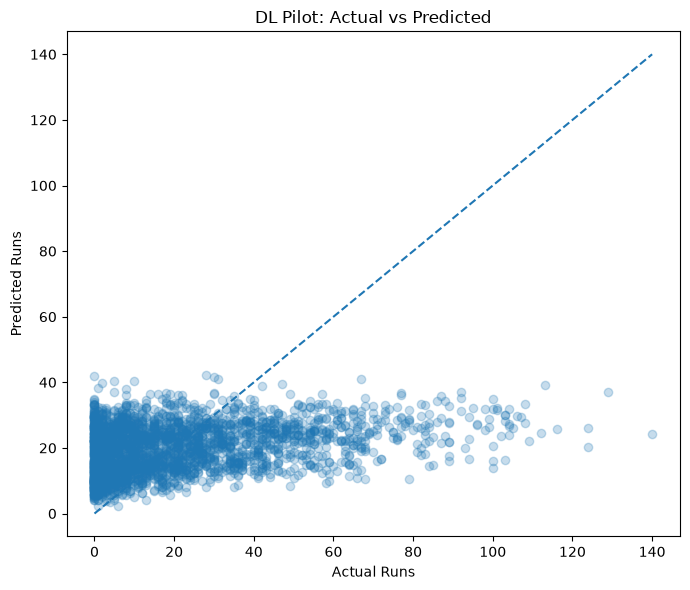

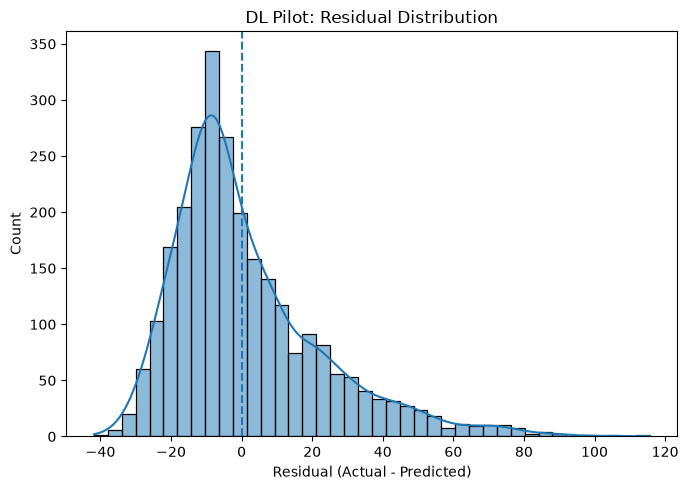


RESIDUAL ANALYSIS COMPLETED


In [63]:

# ============================================================
# 15.3 — PILOT VALIDATION RESIDUAL ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Calculate residuals in original runs
residuals = y_val_actual - y_val_pred

print("RESIDUAL SUMMARY")
print(f"Mean residual: {residuals.mean():.4f}")
print(f"Median residual: {np.median(residuals):.4f}")
print(f"Residual std: {residuals.std():.4f}")
print(f"Underpredictions: {(residuals > 0).sum()}")
print(f"Overpredictions: {(residuals < 0).sum()}")
print(f"Exact predictions: {(residuals == 0).sum()}")

# Actual versus predicted
plt.figure(figsize=(7, 6))
plt.scatter(y_val_actual, y_val_pred, alpha=0.25)
limits = [
    min(y_val_actual.min(), y_val_pred.min()),
    max(y_val_actual.max(), y_val_pred.max())
]
plt.plot(limits, limits, linestyle="--")
plt.xlabel("Actual Runs")
plt.ylabel("Predicted Runs")
plt.title("DL Pilot: Actual vs Predicted")
plt.tight_layout()
plt.show()

# Residual distribution
plt.figure(figsize=(7, 5))
sns.histplot(residuals, bins=40, kde=True)
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (Actual - Predicted)")
plt.title("DL Pilot: Residual Distribution")
plt.tight_layout()
plt.show()

print("\nRESIDUAL ANALYSIS COMPLETED")


In [64]:

# ============================================================
# 15.4 — VALIDATION ERROR BY ACTUAL RUNS RANGE
# ============================================================

error_analysis = pd.DataFrame({
    "Actual_Runs": np.asarray(y_val_actual).ravel(),
    "Predicted_Runs": np.asarray(y_val_pred).ravel()
})

error_analysis["Residual"] = (
    error_analysis["Actual_Runs"]
    - error_analysis["Predicted_Runs"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Residual"].abs()
)

error_analysis["Score_Range"] = pd.cut(
    error_analysis["Actual_Runs"],
    bins=[-np.inf, 10, 30, 50, 100, np.inf],
    labels=["0-10", "11-30", "31-50", "51-100", "100+"],
    include_lowest=True
)

range_results = (
    error_analysis
    .groupby("Score_Range", observed=False)
    .agg(
        Samples=("Actual_Runs", "count"),
        Actual_Mean=("Actual_Runs", "mean"),
        Predicted_Mean=("Predicted_Runs", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .round(3)
)

display(range_results)

print("\nERROR ANALYSIS BY SCORE RANGE COMPLETED")


,Samples,Actual_Mean,Predicted_Mean,MAE,Mean_Residual
Score_Range,,,,,
0-10,1179,3.634000,17.548000,13.954000,-13.913000
11-30,790,19.454000,20.179001,6.577000,-0.725000
31-50,383,39.550999,22.230000,17.393999,17.320000
51-100,287,66.930000,24.288000,42.643002,42.643002
100+,24,109.708000,27.791000,81.917000,81.917000



ERROR ANALYSIS BY SCORE RANGE COMPLETED


In [65]:

# ============================================================
# 15.5 — TRAINING TARGET DISTRIBUTION AUDIT
# ============================================================

y_train_actual = batting_dl_scaled[TARGET]["y_train"]

score_distribution = pd.DataFrame({
    "Actual_Runs": np.asarray(y_train_actual).ravel()
})

score_distribution["Score_Range"] = pd.cut(
    score_distribution["Actual_Runs"],
    bins=[-np.inf, 10, 30, 50, 100, np.inf],
    labels=["0-10", "11-30", "31-50", "51-100", "100+"],
    include_lowest=True
)

distribution_summary = (
    score_distribution
    .groupby("Score_Range", observed=False)
    .agg(
        Samples=("Actual_Runs", "count"),
        Mean_Runs=("Actual_Runs", "mean")
    )
)

distribution_summary["Percentage"] = (
    distribution_summary["Samples"]
    / len(score_distribution) * 100
)

display(distribution_summary.round(2))

print("\nTRAINING TARGET DISTRIBUTION")
print("Total observations:", len(score_distribution))
print("Target mean:", round(score_distribution["Actual_Runs"].mean(), 3))
print("Target standard deviation:",
      round(score_distribution["Actual_Runs"].std(), 3))
print("Target skewness:",
      round(score_distribution["Actual_Runs"].skew(), 3))

print("\nTARGET DISTRIBUTION AUDIT COMPLETED")


,Samples,Mean_Runs,Percentage
Score_Range,,,
0-10,5803,3.780000,44.48
11-30,4123,18.950001,31.61
31-50,1805,39.250000,13.84
51-100,1258,66.440002,9.64
100+,56,112.290001,0.43



TRAINING TARGET DISTRIBUTION
Total observations: 13045
Target mean: 19.993
Target standard deviation: 21.178
Target skewness: 1.543

TARGET DISTRIBUTION AUDIT COMPLETED


In [66]:

# ============================================================
# 15.6 — LOG1P TARGET TRANSFORMATION EXPERIMENT
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np
import pandas as pd

# 1. Retrieve original target values
log1p_y_train = np.asarray(
    batting_dl_scaled[TARGET]["y_train"]
).reshape(-1, 1)

log1p_y_val = np.asarray(
    batting_dl_scaled[TARGET]["y_val"]
).reshape(-1, 1)

# 2. Apply log1p transformation
assert np.all(log1p_y_train >= 0)
assert np.all(log1p_y_val >= 0)

log1p_y_train_transformed = np.log1p(log1p_y_train)
log1p_y_val_transformed = np.log1p(log1p_y_val)

# 3. Scale transformed target using TRAINING DATA ONLY
log1p_target_scaler = StandardScaler()

log1p_y_train_scaled = log1p_target_scaler.fit_transform(
    log1p_y_train_transformed
).ravel()

log1p_y_val_scaled = log1p_target_scaler.transform(
    log1p_y_val_transformed
).ravel()

# 4. Retrieve the same input features
log1p_X_train = batting_dl_scaled[TARGET]["X_train"]
log1p_X_val = batting_dl_scaled[TARGET]["X_val"]

# 5. Build a separate MLP
keras.utils.set_random_seed(42)

log1p_pilot_model = build_mlp(
    input_features=log1p_X_train.shape[1]
)

log1p_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# 6. Train
log1p_history = log1p_pilot_model.fit(
    log1p_X_train,
    log1p_y_train_scaled,
    validation_data=(
        log1p_X_val,
        log1p_y_val_scaled
    ),
    epochs=100,
    batch_size=64,
    callbacks=[log1p_early_stopping],
    shuffle=True,
    verbose=1
)

print("\nLOG1P PILOT TRAINING COMPLETED")
print("Best validation loss:",
      round(min(log1p_history.history["val_loss"]), 5))
print("Best epoch:",
      np.argmin(log1p_history.history["val_loss"]) + 1)


Epoch 1/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3948 - mae: 0.7672 - rmse: 0.9538 - val_loss: 0.4249 - val_mae: 0.7971 - val_rmse: 1.0118
Epoch 2/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3853 - mae: 0.7557 - rmse: 0.9414 - val_loss: 0.4182 - val_mae: 0.7905 - val_rmse: 1.0009
Epoch 3/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3828 - mae: 0.7522 - rmse: 0.9386 - val_loss: 0.4164 - val_mae: 0.7904 - val_rmse: 0.9964
Epoch 4/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3803 - mae: 0.7488 - rmse: 0.9354 - val_loss: 0.4147 - val_mae: 0.7906 - val_rmse: 0.9909
Epoch 5/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3782 - mae: 0.7467 - rmse: 0.9323 - val_loss: 0.4156 - val_mae: 0.7897 - val_rmse: 0.9945
Epoch 6/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3766 - mae: 0.7451 - rmse: 0.9304 - val_loss: 0.4152 - val_mae: 0.7893 - val_rmse: 0.9934
Epoch 7/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3750 - mae: 0.7419 

In [67]:

# ============================================================
# 15.7 — COMPARE ORIGINAL MLP VS LOG1P MLP
# Evaluation in ORIGINAL RUNS
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Actual validation runs
y_val_original = np.asarray(
    batting_dl_scaled[TARGET]["y_val"]
).ravel()

# ------------------------------------------------------------
# A. Original MLP predictions
# ------------------------------------------------------------

original_pred = np.asarray(y_val_pred).ravel()

# ------------------------------------------------------------
# B. Log1p MLP predictions
# ------------------------------------------------------------

log1p_pred_scaled = log1p_pilot_model.predict(
    log1p_X_val,
    verbose=0
).reshape(-1, 1)

# Reverse StandardScaler
log1p_pred_transformed = (
    log1p_target_scaler.inverse_transform(
        log1p_pred_scaled
    )
)

# Reverse log1p transformation
log1p_pred_original = np.expm1(
    log1p_pred_transformed
).ravel()

# ------------------------------------------------------------
# C. Mean baseline
# ------------------------------------------------------------

mean_pred = np.full(
    len(y_val_original),
    fill_value=y_val_original.mean()
)

# ------------------------------------------------------------
# D. Metric calculation
# ------------------------------------------------------------

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame(
    {
        "Original MLP": evaluate_model(
            y_val_original, original_pred
        ),
        "Log1p MLP": evaluate_model(
            y_val_original, log1p_pred_original
        ),
        "Mean Baseline": evaluate_model(
            y_val_original, mean_pred
        )
    }
).T

display(results.round(4))

# ------------------------------------------------------------
# E. Prediction diagnostics
# ------------------------------------------------------------

print("\nPREDICTION DIAGNOSTICS")

for model_name, predictions in {
    "Original MLP": original_pred,
    "Log1p MLP": log1p_pred_original
}.items():
    print(f"\n{model_name}")
    print("Minimum:", round(predictions.min(), 3))
    print("Maximum:", round(predictions.max(), 3))
    print("Negative predictions:", int((predictions < 0).sum()))

print("\nLOG1P VS ORIGINAL MLP EVALUATION COMPLETED")


,MAE,RMSE,R2
Original MLP,15.9647,21.4693,0.1133
Log1p MLP,15.6275,22.3379,0.0401
Mean Baseline,17.6558,22.7995,0.0000



PREDICTION DIAGNOSTICS

Original MLP
Minimum: 2.362
Maximum: 42.082
Negative predictions: 0

Log1p MLP
Minimum: 0.912
Maximum: 46.812
Negative predictions: 0

LOG1P VS ORIGINAL MLP EVALUATION COMPLETED


In [68]:
mean_pred = np.full(
    len(y_val_original),
    fill_value=y_val_original.mean()
)

In [69]:
mean_pred = np.full(
    len(y_val_original),
    fill_value=np.asarray(
        batting_dl_scaled[TARGET]["y_train"]
    ).mean()
)

In [70]:

# ============================================================
# 15.8 — FINAL PILOT COMPARISON WITH VALID TRAINING BASELINE
# ============================================================

y_train_original = np.asarray(
    batting_dl_scaled[TARGET]["y_train"]
).ravel()

# Valid baseline: training mean only
train_mean = y_train_original.mean()

mean_pred = np.full(
    len(y_val_original),
    train_mean
)

# Overall comparison
corrected_results = pd.DataFrame({
    "Original MLP": evaluate_model(
        y_val_original, original_pred
    ),
    "Log1p MLP": evaluate_model(
        y_val_original, log1p_pred_original
    ),
    "Training Mean Baseline": evaluate_model(
        y_val_original, mean_pred
    )
}).T

display(corrected_results.round(4))

# Segment-wise comparison
segment_data = pd.DataFrame({
    "Actual": y_val_original,
    "Original_Pred": original_pred,
    "Log1p_Pred": log1p_pred_original
})

segment_data["Score_Range"] = pd.cut(
    segment_data["Actual"],
    bins=[-np.inf, 10, 30, 50, 100, np.inf],
    labels=["0-10", "11-30", "31-50", "51-100", "100+"],
    include_lowest=True
)

segment_results = []

for score_range, group in segment_data.groupby(
    "Score_Range", observed=False
):
    if len(group) == 0:
        continue

    segment_results.append({
        "Score_Range": score_range,
        "Samples": len(group),
        "Original_MLP_MAE": mean_absolute_error(
            group["Actual"], group["Original_Pred"]
        ),
        "Log1p_MLP_MAE": mean_absolute_error(
            group["Actual"], group["Log1p_Pred"]
        )
    })

segment_comparison = pd.DataFrame(segment_results)
display(segment_comparison.round(3))

print("\nTRAINING MEAN:", round(train_mean, 4))
print("CORRECTED PILOT COMPARISON COMPLETED")


,MAE,RMSE,R2
Original MLP,15.9647,21.4693,0.1133
Log1p MLP,15.6275,22.3379,0.0401
Training Mean Baseline,17.3611,22.8352,-0.0031


,Score_Range,Samples,Original_MLP_MAE,Log1p_MLP_MAE
0,0-10,1179,13.954,9.809
1,11-30,790,6.577,7.901
2,31-50,383,17.394,21.778
3,51-100,287,42.643,46.685
4,100+,24,81.917,86.261



TRAINING MEAN: 19.9933
CORRECTED PILOT COMPARISON COMPLETED


In [72]:

# ============================================================
# 15.9 — SAMPLE-WEIGHTED MLP EXPERIMENT
# ============================================================

# Define score groups using training data
train_score_bins = pd.cut(
    y_train_original,
    bins=[-np.inf, 10, 30, 50, 100, np.inf],
    labels=["0-10", "11-30", "31-50", "51-100", "100+"]
)

# Calculate training frequency for each group
bin_counts = train_score_bins.value_counts().sort_index()

# Inverse square-root frequency weights
bin_weights = 1 / np.sqrt(
    bin_counts / len(y_train_original)
)

# Normalize weights to have mean approximately 1
bin_weights = bin_weights / np.average(
    bin_weights,
    weights=bin_counts
)

# Assign sample weights

sample_weights = np.asarray(
    train_score_bins.map(bin_weights),
    dtype=np.float32
)

# Validation checks
assert len(sample_weights) == len(y_train_original)
assert np.isfinite(sample_weights).all()
assert (sample_weights > 0).all()

print("Sample weights created successfully")
print("Shape:", sample_weights.shape)
print("Minimum:", round(sample_weights.min(), 4))
print("Maximum:", round(sample_weights.max(), 4))
print("Mean:", round(sample_weights.mean(), 4))

# Train a separate weighted model
keras.utils.set_random_seed(42)

weighted_pilot_model = build_mlp(
    input_features=X_train.shape[1]
)

weighted_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

weighted_history = weighted_pilot_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[weighted_early_stopping],
    shuffle=True,
    verbose=1
)

print("\nWEIGHTED MLP TRAINING COMPLETED")
print(
    "Best epoch:",
    np.argmin(weighted_history.history["val_loss"]) + 1
)


Sample weights created successfully
Shape: (13045,)
Minimum: 0.7583
Maximum: 7.7193
Mean: 1.0
Epoch 1/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5335 - mae: 0.7554 - rmse: 0.9732 - val_loss: 0.4744 - val_mae: 0.8605 - val_rmse: 1.0786
Epoch 2/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5203 - mae: 0.7463 - rmse: 0.9603 - val_loss: 0.4933 - val_mae: 0.8776 - val_rmse: 1.1081
Epoch 3/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5180 - mae: 0.7423 - rmse: 0.9581 - val_loss: 0.4886 - val_mae: 0.8752 - val_rmse: 1.0992
Epoch 4/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5135 - mae: 0.7408 - rmse: 0.9564 - val_loss: 0.4821 - val_mae: 0.8667 - val_rmse: 1.0959
Epoch 5/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5090 - mae: 0.7384 - rmse: 0.9545 - val_loss: 0.4852 - val_mae: 0.8672 - val_rmse: 1.1026
Epoch 6/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5087 - mae: 0.7388 - rmse: 0.9546 - val_loss: 0.4816 - val_mae: 0.8645 - val_r

In [73]:

# ============================================================
# 15.10 — WEIGHTED MLP ORIGINAL-SCALE EVALUATION
# ============================================================

# Predict scaled target
weighted_pred_scaled = weighted_pilot_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Reverse original target scaling
original_target_scaler = batting_target_scalers[TARGET]

weighted_pred = original_target_scaler.inverse_transform(
    weighted_pred_scaled
).ravel()

# Compare all three models and baseline
weighted_comparison = pd.DataFrame({
    "Original MLP": evaluate_model(
        y_val_original, original_pred
    ),
    "Log1p MLP": evaluate_model(
        y_val_original, log1p_pred_original
    ),
    "Weighted MLP": evaluate_model(
        y_val_original, weighted_pred
    ),
    "Training Mean": evaluate_model(
        y_val_original, mean_pred
    )
}).T

display(weighted_comparison.round(4))

# Segment-wise MAE
weighted_segment_data = pd.DataFrame({
    "Actual": y_val_original,
    "Original_Pred": original_pred,
    "Log1p_Pred": log1p_pred_original,
    "Weighted_Pred": weighted_pred
})

weighted_segment_data["Score_Range"] = pd.cut(
    weighted_segment_data["Actual"],
    bins=[-np.inf, 10, 30, 50, 100, np.inf],
    labels=["0-10", "11-30", "31-50", "51-100", "100+"],
    include_lowest=True
)

segment_rows = []

for score_range, group in weighted_segment_data.groupby(
    "Score_Range", observed=False
):
    if len(group) == 0:
        continue

    segment_rows.append({
        "Score_Range": score_range,
        "Samples": len(group),
        "Original_MAE": mean_absolute_error(
            group["Actual"], group["Original_Pred"]
        ),
        "Log1p_MAE": mean_absolute_error(
            group["Actual"], group["Log1p_Pred"]
        ),
        "Weighted_MAE": mean_absolute_error(
            group["Actual"], group["Weighted_Pred"]
        )
    })

display(pd.DataFrame(segment_rows).round(3))

print("\nWEIGHTED MLP EVALUATION COMPLETED")
print("Weighted prediction minimum:", round(weighted_pred.min(), 3))
print("Weighted prediction maximum:", round(weighted_pred.max(), 3))
print("Negative predictions:", int((weighted_pred < 0).sum()))


,MAE,RMSE,R2
Original MLP,15.9647,21.4693,0.1133
Log1p MLP,15.6275,22.3379,0.0401
Weighted MLP,18.2239,22.8422,-0.0038
Training Mean,17.3611,22.8352,-0.0031


,Score_Range,Samples,Original_MAE,Log1p_MAE,Weighted_MAE
0,0-10,1179,13.954,9.809,20.423
1,11-30,790,6.577,7.901,11.478
2,31-50,383,17.394,21.778,11.887
3,51-100,287,42.643,46.685,32.018
4,100+,24,81.917,86.261,68.382



WEIGHTED MLP EVALUATION COMPLETED
Weighted prediction minimum: -3.339
Weighted prediction maximum: 71.866
Negative predictions: 3


In [75]:

# ============================================================
# 15.11 — ORIGINAL MLP PERMUTATION FEATURE IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

# Keras model compatibility wrapper
class KerasRegressorWrapper:
    def __init__(self, model):
        self.model = model

    def fit(self, X, y=None):
        return self

    def predict(self, X, **kwargs):
        return self.model.predict(
            X, verbose=0
        ).ravel()

    def score(self, X, y):
        return -mean_absolute_error(
            y, self.predict(X)
        )

# Create wrapper
original_wrapper = KerasRegressorWrapper(pilot_model)

# Custom negative MAE scorer
def negative_mae_scorer(estimator, X, y):
    predictions = estimator.predict(X)
    return -mean_absolute_error(y, predictions)

# Calculate permutation importance
importance_result = permutation_importance(
    original_wrapper,
    X_val,
    y_val,
    scoring=negative_mae_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": batting_dl_processed[TARGET]["feature_names"],
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
)

display(importance_df.head(20).round(5))

print("\nPERMUTATION IMPORTANCE COMPLETED")


,Feature,Importance_Mean,Importance_Std
14,numerical__runs_scored_expanding_mean,0.00614,0.00191
13,numerical__runs_scored_rolling_mean_10,0.00398,0.00117
1,numerical__balls_faced,0.00312,0.00082
17,numerical__balls_faced_rolling_mean_5,0.00296,0.00042
40,numerical__matches_played_before,0.00258,0.00078
28,numerical__sixes_rolling_mean_10,0.00251,0.00034
19,numerical__balls_faced_expanding_mean,0.00246,0.00112
29,numerical__sixes_expanding_mean,0.00246,0.00025
39,numerical__dismissals_expanding_mean,0.00199,0.00072
18,numerical__balls_faced_rolling_mean_10,0.00183,0.00073



PERMUTATION IMPORTANCE COMPLETED


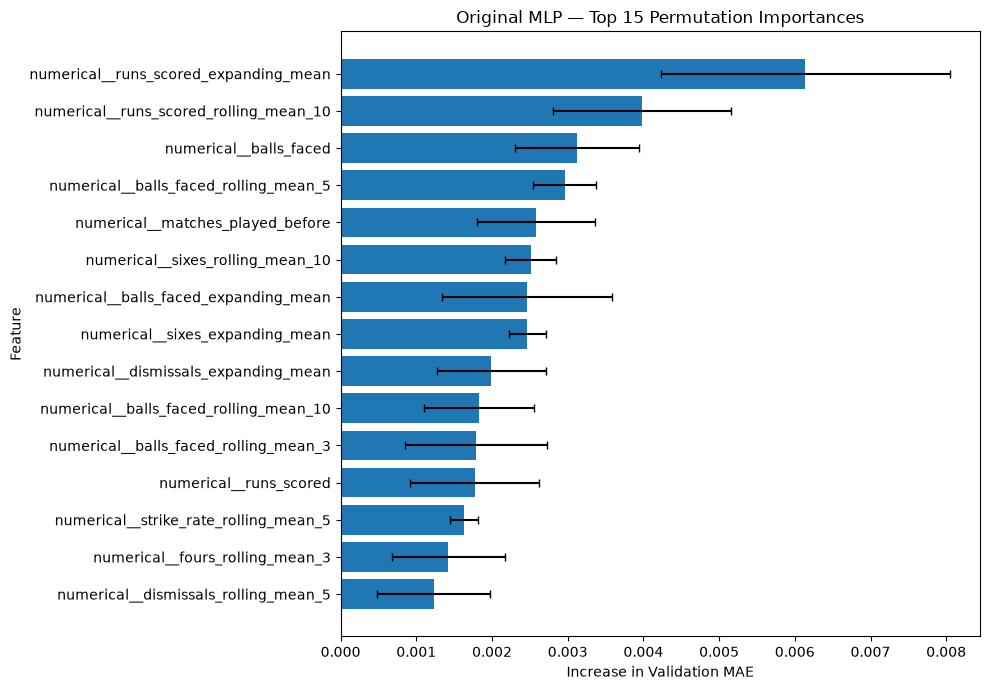

TOP 15 FEATURE IMPORTANCE VISUALIZATION COMPLETED


In [76]:

# ============================================================
# 15.12 — TOP 15 FEATURE IMPORTANCE VISUALIZATION
# ============================================================

top_features = importance_df.head(15).sort_values(
    "Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"],
    capsize=3
)

plt.xlabel("Increase in Validation MAE")
plt.ylabel("Feature")
plt.title("Original MLP — Top 15 Permutation Importances")
plt.tight_layout()
plt.show()

print("TOP 15 FEATURE IMPORTANCE VISUALIZATION COMPLETED")


In [77]:

# ============================================================
# 15.13 — TOP FEATURE CORRELATION AUDIT
# ============================================================

# Get top 15 features
top_15_features = importance_df.head(15)["Feature"].tolist()

# Build validation DataFrame
X_val_df = pd.DataFrame(
    X_val,
    columns=batting_dl_processed[TARGET]["feature_names"]
)

# Select top features
top_15_data = X_val_df[top_15_features].copy()

# Spearman correlation
correlation_matrix = top_15_data.corr(
    method="spearman"
)

# Extract unique feature pairs
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Spearman_Correlation"
]

correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Spearman_Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "Absolute_Correlation",
    ascending=False
)

print("TOP CORRELATED FEATURE PAIRS")
display(correlation_pairs.head(20).round(4))

# Identify strongly correlated pairs
strong_pairs = correlation_pairs[
    correlation_pairs["Absolute_Correlation"] >= 0.85
]

print("\nSTRONGLY CORRELATED PAIRS (|rho| >= 0.85)")
display(strong_pairs.round(4))

print("\nFEATURE CORRELATION AUDIT COMPLETED")


TOP CORRELATED FEATURE PAIRS


,Feature_1,Feature_2,Spearman_Correlation,Absolute_Correlation
6,numerical__runs_scored_expanding_mean,numerical__balls_faced_expanding_mean,0.9596,0.9596
24,numerical__runs_scored_rolling_mean_10,numerical__balls_faced_rolling_mean_10,0.9489,0.9489
41,numerical__balls_faced,numerical__runs_scored,0.9357,0.9357
54,numerical__balls_faced_rolling_mean_5,numerical__balls_faced_rolling_mean_10,0.8929,0.8929
55,numerical__balls_faced_rolling_mean_5,numerical__balls_faced_rolling_mean_3,0.8888,0.8888
99,numerical__balls_faced_expanding_mean,numerical__balls_faced_rolling_mean_10,0.8690,0.8690
1,numerical__runs_scored_expanding_mean,numerical__runs_scored_rolling_mean_10,0.8615,0.8615
18,numerical__runs_scored_rolling_mean_10,numerical__balls_faced_rolling_mean_5,0.8577,0.8577
9,numerical__runs_scored_expanding_mean,numerical__balls_faced_rolling_mean_10,0.8522,0.8522
163,numerical__balls_faced_rolling_mean_3,numerical__fours_rolling_mean_3,0.8392,0.8392



STRONGLY CORRELATED PAIRS (|rho| >= 0.85)


,Feature_1,Feature_2,Spearman_Correlation,Absolute_Correlation
6,numerical__runs_scored_expanding_mean,numerical__balls_faced_expanding_mean,0.9596,0.9596
24,numerical__runs_scored_rolling_mean_10,numerical__balls_faced_rolling_mean_10,0.9489,0.9489
41,numerical__balls_faced,numerical__runs_scored,0.9357,0.9357
54,numerical__balls_faced_rolling_mean_5,numerical__balls_faced_rolling_mean_10,0.8929,0.8929
55,numerical__balls_faced_rolling_mean_5,numerical__balls_faced_rolling_mean_3,0.8888,0.8888
99,numerical__balls_faced_expanding_mean,numerical__balls_faced_rolling_mean_10,0.8690,0.8690
1,numerical__runs_scored_expanding_mean,numerical__runs_scored_rolling_mean_10,0.8615,0.8615
18,numerical__runs_scored_rolling_mean_10,numerical__balls_faced_rolling_mean_5,0.8577,0.8577
9,numerical__runs_scored_expanding_mean,numerical__balls_faced_rolling_mean_10,0.8522,0.8522



FEATURE CORRELATION AUDIT COMPLETED


In [78]:

# ============================================================
# 15.14 — GROUPED PERMUTATION IMPORTANCE
# ============================================================

from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Original validation predictions in runs
baseline_mae = mean_absolute_error(
    y_val_original,
    original_pred
)

# Use validation feature DataFrame
X_grouped = X_val_df.copy()

group_importance_rows = []

rng = np.random.default_rng(42)

# Evaluate each strongly correlated pair
for _, pair in strong_pairs.iterrows():

    feature_1 = pair["Feature_1"]
    feature_2 = pair["Feature_2"]

    mae_increases = []

    for repeat in range(5):

        X_permuted = X_grouped.copy()

        # Same permutation for both features
        permutation_indices = rng.permutation(
            len(X_permuted)
        )

        X_permuted[[feature_1, feature_2]] = (
            X_grouped[[feature_1, feature_2]]
            .iloc[permutation_indices]
            .to_numpy()
        )

        # Predict using original MLP
        pred_scaled = pilot_model.predict(
            X_permuted.to_numpy(),
            verbose=0
        ).reshape(-1, 1)

        pred_original = (
            batting_target_scalers[TARGET]
            .inverse_transform(pred_scaled)
            .ravel()
        )

        permuted_mae = mean_absolute_error(
            y_val_original,
            pred_original
        )

        mae_increases.append(
            permuted_mae - baseline_mae
        )

    group_importance_rows.append({
        "Feature_1": feature_1,
        "Feature_2": feature_2,
        "Spearman_Correlation": pair["Spearman_Correlation"],
        "Grouped_Importance_Mean": np.mean(mae_increases),
        "Grouped_Importance_Std": np.std(mae_increases)
    })

group_importance_df = pd.DataFrame(
    group_importance_rows
).sort_values(
    "Grouped_Importance_Mean",
    ascending=False
)

display(group_importance_df.round(5))

print("\nGROUPED PERMUTATION IMPORTANCE COMPLETED")
print("Baseline validation MAE:", round(baseline_mae, 4))


,Feature_1,Feature_2,Spearman_Correlation,Grouped_Importance_Mean,Grouped_Importance_Std
6,numerical__runs_scored_expanding_mean,numerical__runs_scored_rolling_mean_10,0.86154,0.30675,0.04733
0,numerical__runs_scored_expanding_mean,numerical__balls_faced_expanding_mean,0.95961,0.20636,0.04004
8,numerical__runs_scored_expanding_mean,numerical__balls_faced_rolling_mean_10,0.85221,0.19328,0.03223
7,numerical__runs_scored_rolling_mean_10,numerical__balls_faced_rolling_mean_5,0.85769,0.16722,0.01319
1,numerical__runs_scored_rolling_mean_10,numerical__balls_faced_rolling_mean_10,0.94893,0.16185,0.02215
5,numerical__balls_faced_expanding_mean,numerical__balls_faced_rolling_mean_10,0.86901,0.10369,0.01834
2,numerical__balls_faced,numerical__runs_scored,0.93571,0.10100,0.00619
4,numerical__balls_faced_rolling_mean_5,numerical__balls_faced_rolling_mean_3,0.88876,0.08864,0.01347
3,numerical__balls_faced_rolling_mean_5,numerical__balls_faced_rolling_mean_10,0.89292,0.07995,0.01407



GROUPED PERMUTATION IMPORTANCE COMPLETED
Baseline validation MAE: 15.9647


In [79]:

# ============================================================
# 15.15 — FEATURE FAMILY INVENTORY
# ============================================================

feature_names = batting_dl_processed[TARGET]["feature_names"]

feature_families = {
    "Historical Scoring": [
        "runs_scored"
    ],
    "Batting Opportunity": [
        "balls_faced"
    ],
    "Boundary Performance": [
        "fours", "sixes"
    ],
    "Dismissal and Consistency": [
        "dismissals", "strike_rate"
    ]
}

family_inventory = []

for family, keywords in feature_families.items():

    matching_features = [
        feature for feature in feature_names
        if any(
            keyword in feature.replace("numerical__", "")
            for keyword in keywords
        )
    ]

    family_inventory.append({
        "Feature_Family": family,
        "Feature_Count": len(matching_features),
        "Features": matching_features
    })

for item in family_inventory:
    print(f"\n{item['Feature_Family']}")
    print("Feature count:", item["Feature_Count"])

    for feature in item["Features"]:
        print("  -", feature)

print("\nFEATURE FAMILY INVENTORY COMPLETED")



Historical Scoring
Feature count: 6
  - numerical__runs_scored
  - numerical__previous_runs_scored
  - numerical__runs_scored_rolling_mean_3
  - numerical__runs_scored_rolling_mean_5
  - numerical__runs_scored_rolling_mean_10
  - numerical__runs_scored_expanding_mean

Batting Opportunity
Feature count: 6
  - numerical__balls_faced
  - numerical__previous_balls_faced
  - numerical__balls_faced_rolling_mean_3
  - numerical__balls_faced_rolling_mean_5
  - numerical__balls_faced_rolling_mean_10
  - numerical__balls_faced_expanding_mean

Boundary Performance
Feature count: 12
  - numerical__fours
  - numerical__sixes
  - numerical__previous_fours
  - numerical__fours_rolling_mean_3
  - numerical__fours_rolling_mean_5
  - numerical__fours_rolling_mean_10
  - numerical__fours_expanding_mean
  - numerical__previous_sixes
  - numerical__sixes_rolling_mean_3
  - numerical__sixes_rolling_mean_5
  - numerical__sixes_rolling_mean_10
  - numerical__sixes_expanding_mean

Dismissal and Consistency
Fe

In [80]:

# ============================================================
# 15.16 — UNASSIGNED FEATURE AUDIT
# ============================================================

all_features = list(
    batting_dl_processed[TARGET]["feature_names"]
)

assigned_features = [
    feature
    for item in family_inventory
    for feature in item["Features"]
]

unassigned_features = [
    feature
    for feature in all_features
    if feature not in assigned_features
]

print("TOTAL FEATURES:", len(all_features))
print("ASSIGNED FEATURES:", len(assigned_features))
print("UNASSIGNED FEATURES:", len(unassigned_features))

print("\nUNASSIGNED FEATURE DETAILS")

for feature in unassigned_features:
    print("-", feature)

print("\nUNASSIGNED FEATURE AUDIT COMPLETED")


TOTAL FEATURES: 59
ASSIGNED FEATURES: 36
UNASSIGNED FEATURES: 23

UNASSIGNED FEATURE DETAILS
- numerical__retired_hurt_count
- numerical__not_out_innings
- numerical__season
- numerical__days_since_previous_match
- numerical__matches_played_before
- categorical__batting_team_Chennai Super Kings
- categorical__batting_team_Deccan Chargers
- categorical__batting_team_Delhi Capitals
- categorical__batting_team_Delhi Daredevils
- categorical__batting_team_Gujarat Lions
- categorical__batting_team_Gujarat Titans
- categorical__batting_team_Kings XI Punjab
- categorical__batting_team_Kochi Tuskers Kerala
- categorical__batting_team_Kolkata Knight Riders
- categorical__batting_team_Lucknow Super Giants
- categorical__batting_team_Mumbai Indians
- categorical__batting_team_Pune Warriors
- categorical__batting_team_Punjab Kings
- categorical__batting_team_Rajasthan Royals
- categorical__batting_team_Rising Pune Supergiant
- categorical__batting_team_Rising Pune Supergiants
- categorical__battin

In [81]:

# ============================================================
# 15.17 — COMPLETE FEATURE FAMILY MAPPING
# ============================================================

# Four primary ablation families
ablation_families = {
    "Historical Scoring": [
        f for f in feature_names
        if "runs_scored" in f
    ],

    "Batting Opportunity": [
        f for f in feature_names
        if "balls_faced" in f
    ],

    "Boundary Performance": [
        f for f in feature_names
        if "fours" in f or "sixes" in f
    ],

    "Dismissal and Consistency": [
        f for f in feature_names
        if "dismissals" in f or "strike_rate" in f
    ]
}

# Context and experience
context_features = [
    f for f in feature_names
    if f in [
        "numerical__retired_hurt_count",
        "numerical__not_out_innings",
        "numerical__season",
        "numerical__days_since_previous_match",
        "numerical__matches_played_before"
    ]
]

# Team identity
team_features = [
    f for f in feature_names
    if f.startswith("categorical__batting_team_")
]

# Validate primary groups
primary_features = [
    f
    for group in ablation_families.values()
    for f in group
]

# Check no overlapping assignments
assert len(primary_features) == len(set(primary_features))

# Check complete feature coverage
all_assigned = (
    primary_features
    + context_features
    + team_features
)

assert len(all_assigned) == len(set(all_assigned))
assert set(all_assigned) == set(feature_names)

# Display summary
feature_summary = pd.DataFrame([
    {
        "Feature_Family": name,
        "Feature_Count": len(features)
    }
    for name, features in ablation_families.items()
] + [
    {"Feature_Family": "Context and Experience",
     "Feature_Count": len(context_features)},

    {"Feature_Family": "Team Identity",
     "Feature_Count": len(team_features)}
])

display(feature_summary)

print("\nTOTAL FEATURES:", len(feature_names))
print("UNIQUE ASSIGNED FEATURES:", len(set(all_assigned)))
print("UNASSIGNED FEATURES:", len(set(feature_names) - set(all_assigned)))
print("OVERLAPPING FEATURES:",
      len(all_assigned) - len(set(all_assigned)))

print("\nFEATURE FAMILY MAPPING VALIDATED")


,Feature_Family,Feature_Count
0,Historical Scoring,6
1,Batting Opportunity,6
2,Boundary Performance,12
3,Dismissal and Consistency,12
4,Context and Experience,5
5,Team Identity,18



TOTAL FEATURES: 59
UNIQUE ASSIGNED FEATURES: 59
UNASSIGNED FEATURES: 0
OVERLAPPING FEATURES: 0

FEATURE FAMILY MAPPING VALIDATED


In [82]:

# ============================================================
# 15.18 — FEATURE FAMILY ABLATION DATASET PREPARATION
# ============================================================

# Recover original feature names and transformed arrays
all_feature_names = list(
    batting_dl_processed[TARGET]["feature_names"]
)

X_train_full = np.asarray(X_train)
X_val_full = np.asarray(X_val)

# Define experiments
ablation_experiments = {
    "Baseline_All_Features": None,
    "Without_Historical_Scoring": "Historical Scoring",
    "Without_Batting_Opportunity": "Batting Opportunity",
    "Without_Boundary_Performance": "Boundary Performance",
    "Without_Dismissal_Consistency": "Dismissal and Consistency"
}

ablation_datasets = {}

for experiment_name, excluded_family in ablation_experiments.items():

    if excluded_family is None:
        selected_features = all_feature_names.copy()
    else:
        excluded_features = set(
            ablation_families[excluded_family]
        )

        selected_features = [
            feature for feature in all_feature_names
            if feature not in excluded_features
        ]

    selected_indices = [
        all_feature_names.index(feature)
        for feature in selected_features
    ]

    ablation_datasets[experiment_name] = {
        "features": selected_features,
        "feature_indices": selected_indices,
        "X_train": X_train_full[:, selected_indices],
        "X_val": X_val_full[:, selected_indices]
    }

# Dataset audit
ablation_summary = []

for name, dataset in ablation_datasets.items():
    ablation_summary.append({
        "Experiment": name,
        "Features": len(dataset["features"]),
        "Train_Shape": dataset["X_train"].shape,
        "Validation_Shape": dataset["X_val"].shape
    })

display(pd.DataFrame(ablation_summary))

# Validation
assert len(ablation_datasets) == 5

for dataset in ablation_datasets.values():
    assert np.isfinite(dataset["X_train"]).all()
    assert np.isfinite(dataset["X_val"]).all()

assert ablation_datasets["Baseline_All_Features"]["X_train"].shape[1] == 59

print("\nABLATION DATASET PREPARATION COMPLETED")


,Experiment,Features,Train_Shape,Validation_Shape
0,Baseline_All_Features,59,"(13045, 59)","(2663, 59)"
1,Without_Historical_Scoring,53,"(13045, 53)","(2663, 53)"
2,Without_Batting_Opportunity,53,"(13045, 53)","(2663, 53)"
3,Without_Boundary_Performance,47,"(13045, 47)","(2663, 47)"
4,Without_Dismissal_Consistency,47,"(13045, 47)","(2663, 47)"



ABLATION DATASET PREPARATION COMPLETED


In [83]:

# ============================================================
# 15.19 — TRAIN FEATURE FAMILY ABLATION MODELS
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf
import numpy as np

# Preserve existing baseline model
ablation_models = {
    "Baseline_All_Features": pilot_model
}

ablation_histories = {}

# Original target arrays (standardized)
y_train_ablation = np.asarray(
    batting_dl_scaled[TARGET]["y_train_scaled"]
).ravel()

y_val_ablation = np.asarray(
    batting_dl_scaled[TARGET]["y_val_scaled"]
).ravel()

# Train only the four reduced-feature models
experiments_to_train = [
    name for name in ablation_datasets
    if name != "Baseline_All_Features"
]

for experiment_name in experiments_to_train:

    print("\n" + "=" * 65)
    print("TRAINING:", experiment_name)
    print("=" * 65)

    dataset = ablation_datasets[experiment_name]

    # Reproducibility
    keras.utils.set_random_seed(42)

    # Build independent MLP
    model = build_mlp(
        input_features=dataset["X_train"].shape[1]
    )

    # Early stopping
    early_stopping_callback = EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        mode="min",
        verbose=1
    )

    # Train
    history = model.fit(
        dataset["X_train"],
        y_train_ablation,
        validation_data=(
            dataset["X_val"],
            y_val_ablation
        ),
        epochs=100,
        batch_size=64,
        callbacks=[early_stopping_callback],
        shuffle=True,
        verbose=1
    )

    # Preserve model and history
    ablation_models[experiment_name] = model
    ablation_histories[experiment_name] = history

    best_epoch = (
        np.argmin(history.history["val_loss"]) + 1
    )

    print("\nEXPERIMENT COMPLETED:", experiment_name)
    print("Input features:", dataset["X_train"].shape[1])
    print("Best epoch:", best_epoch)
    print(
        "Best validation loss:",
        round(min(history.history["val_loss"]), 5)
    )

print("\nALL FOUR ABLATION MODELS TRAINED")
print("Total models including baseline:", len(ablation_models))



TRAINING: Without_Historical_Scoring
Epoch 1/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3557 - mae: 0.7007 - rmse: 0.9674 - val_loss: 0.3951 - val_mae: 0.7563 - val_rmse: 1.0225
Epoch 2/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3462 - mae: 0.6873 - rmse: 0.9528 - val_loss: 0.3956 - val_mae: 0.7574 - val_rmse: 1.0181
Epoch 3/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3436 - mae: 0.6837 - rmse: 0.9490 - val_loss: 0.3963 - val_mae: 0.7571 - val_rmse: 1.0186
Epoch 4/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3428 - mae: 0.6819 - rmse: 0.9486 - val_loss: 0.3954 - val_mae: 0.7562 - val_rmse: 1.0178
Epoch 5/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3405 - mae: 0.6789 - rmse: 0.9436 - val_loss: 0.3968 - val_mae: 0.7614 - val_rmse: 1.0187
Epoch 6/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3396 - mae: 0.6786 - rmse: 0.9424 - val_loss: 0.3977 - val_mae: 0.7599 - val_rmse: 1.0204
Epoch 7/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 

In [84]:

# ============================================================
# 15.20 — ABLATION MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Actual validation runs
y_val_actual = np.asarray(
    batting_dl_scaled[TARGET]["y_val"]
).ravel()

# Target scaler fitted only on training targets
target_scaler = batting_target_scalers[TARGET]

ablation_results = []
ablation_predictions = {}

for experiment_name, model in ablation_models.items():

    dataset = ablation_datasets[experiment_name]

    # Predict standardized target
    predictions_scaled = model.predict(
        dataset["X_val"],
        verbose=0
    ).reshape(-1, 1)

    # Convert predictions back to actual runs
    predictions_original = (
        target_scaler
        .inverse_transform(predictions_scaled)
        .ravel()
    )

    ablation_predictions[experiment_name] = predictions_original

    # Calculate original-scale metrics
    mae = mean_absolute_error(
        y_val_actual,
        predictions_original
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val_actual,
            predictions_original
        )
    )

    r2 = r2_score(
        y_val_actual,
        predictions_original
    )

    ablation_results.append({
        "Experiment": experiment_name,
        "Feature_Count": len(dataset["features"]),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Negative_Predictions": int(
            (predictions_original < 0).sum()
        )
    })

# Comparison table
ablation_results_df = pd.DataFrame(
    ablation_results
).sort_values("MAE")

display(ablation_results_df.round(4))

# Compare each experiment against original baseline
baseline_mae = ablation_results_df.loc[
    ablation_results_df["Experiment"] == "Baseline_All_Features",
    "MAE"
].iloc[0]

ablation_results_df["MAE_Change_vs_Baseline"] = (
    ablation_results_df["MAE"] - baseline_mae
)

ablation_results_df["MAE_Improvement_Percent"] = (
    (baseline_mae - ablation_results_df["MAE"])
    / baseline_mae
) * 100

print("\nABLATION COMPARISON")
display(
    ablation_results_df[
        [
            "Experiment",
            "MAE_Change_vs_Baseline",
            "MAE_Improvement_Percent"
        ]
    ].round(4)
)

print("\nVALIDATION OBSERVATIONS:", len(y_val_actual))
print("BASELINE MAE:", round(baseline_mae, 4))
print("\nABLATION MODEL EVALUATION COMPLETED")


,Experiment,Feature_Count,MAE,RMSE,R2,Negative_Predictions
3,Without_Boundary_Performance,47,15.9094,21.5738,0.1046,0
4,Without_Dismissal_Consistency,47,15.9453,21.6520,0.0981,0
0,Baseline_All_Features,59,15.9647,21.4693,0.1133,0
1,Without_Historical_Scoring,53,16.0171,21.6537,0.0980,0
2,Without_Batting_Opportunity,53,16.0974,21.6539,0.0980,0



ABLATION COMPARISON


,Experiment,MAE_Change_vs_Baseline,MAE_Improvement_Percent
3,Without_Boundary_Performance,-0.0553,0.3465
4,Without_Dismissal_Consistency,-0.0194,0.1218
0,Baseline_All_Features,0.0000,0.0000
1,Without_Historical_Scoring,0.0523,-0.3279
2,Without_Batting_Opportunity,0.1327,-0.8311



VALIDATION OBSERVATIONS: 2663
BASELINE MAE: 15.9647

ABLATION MODEL EVALUATION COMPLETED


In [85]:

# ============================================================
# 15.21 — PAIRED ABSOLUTE ERROR COMPARISON
# ============================================================

baseline_pred = ablation_predictions[
    "Baseline_All_Features"
]

reduced_pred = ablation_predictions[
    "Without_Boundary_Performance"
]

baseline_errors = np.abs(y_val_actual - baseline_pred)
reduced_errors = np.abs(y_val_actual - reduced_pred)

error_difference = reduced_errors - baseline_errors

print("PAIRED ERROR ANALYSIS")
print("Validation observations:", len(error_difference))
print("Mean error difference:", round(error_difference.mean(), 5))
print("Median error difference:", round(np.median(error_difference), 5))

print("\nOBSERVATION COUNTS")
print("Reduced model better:", int((error_difference < 0).sum()))
print("Baseline better:", int((error_difference > 0).sum()))
print("Equal errors:", int((error_difference == 0).sum()))

print("\nERROR DIFFERENCE QUANTILES")
display(
    pd.Series(error_difference)
    .quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 1.0])
    .to_frame("Reduced_minus_Baseline_Absolute_Error")
    .round(4)
)

print("\nPAIRED ERROR ANALYSIS COMPLETED")


PAIRED ERROR ANALYSIS
Validation observations: 2663
Mean error difference: -0.05533
Median error difference: -0.0842

OBSERVATION COUNTS
Reduced model better: 1375
Baseline better: 1288
Equal errors: 0

ERROR DIFFERENCE QUANTILES


,Reduced_minus_Baseline_Absolute_Error
0.00,-9.8716
0.25,-1.3298
0.50,-0.0842
0.75,1.2579
0.90,2.6487
0.95,3.7062
1.00,9.6514



PAIRED ERROR ANALYSIS COMPLETED


In [86]:
# ============================================================
# 15.22 — RANDOM-SEED EXPERIMENT READINESS AUDIT
# ============================================================

models_to_compare = [
    "Baseline_All_Features",
    "Without_Boundary_Performance"
]

for name in models_to_compare:

    model = ablation_models[name]
    dataset = ablation_datasets[name]

    print("\nMODEL:", name)
    print("Input shape:", model.input_shape)
    print("Feature count:", len(dataset["features"]))
    print("Training samples:", dataset["X_train"].shape[0])
    print("Validation samples:", dataset["X_val"].shape[0])
    print("Trainable parameters:", model.count_params())

print("\nBASELINE AND REDUCED MODEL AUDIT COMPLETED")


MODEL: Baseline_All_Features
Input shape: (None, 59)
Feature count: 59
Training samples: 13045
Validation samples: 2663
Trainable parameters: 18049

MODEL: Without_Boundary_Performance
Input shape: (None, 47)
Feature count: 47
Training samples: 13045
Validation samples: 2663
Trainable parameters: 16513

BASELINE AND REDUCED MODEL AUDIT COMPLETED


In [87]:

# ============================================================
# 15.23 — MULTI-SEED ABLATION STABILITY EXPERIMENT
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

SEEDS = [42, 7, 21, 123, 2025]

MODEL_NAMES = [
    "Baseline_All_Features",
    "Without_Boundary_Performance"
]

# Original-scale validation target
y_val_actual = np.asarray(
    batting_dl_scaled[TARGET]["y_val"]
).ravel()

target_scaler = batting_target_scalers[TARGET]

# Training targets in standardized scale
y_train_scaled = np.asarray(
    batting_dl_scaled[TARGET]["y_train_scaled"]
).ravel()

y_val_scaled = np.asarray(
    batting_dl_scaled[TARGET]["y_val_scaled"]
).ravel()

# Preserve existing seed-42 models
seed_experiment_models = {
    42: {
        name: ablation_models[name]
        for name in MODEL_NAMES
    }
}

seed_results = []

for seed in SEEDS:

    print("\n" + "=" * 65)
    print("RANDOM SEED:", seed)
    print("=" * 65)

    if seed == 42:
        print("Reusing existing seed-42 models.")

    else:
        seed_experiment_models[seed] = {}

        for model_name in MODEL_NAMES:

            print("\nTraining:", model_name)

            dataset = ablation_datasets[model_name]

            # Set seed before model initialization
            keras.utils.set_random_seed(seed)

            model = build_mlp(
                input_features=dataset["X_train"].shape[1]
            )

            early_stopping = EarlyStopping(
                monitor="val_loss",
                patience=12,
                restore_best_weights=True,
                mode="min",
                verbose=0
            )

            history = model.fit(
                dataset["X_train"],
                y_train_scaled,
                validation_data=(
                    dataset["X_val"],
                    y_val_scaled
                ),
                epochs=100,
                batch_size=64,
                callbacks=[early_stopping],
                shuffle=True,
                verbose=0
            )

            seed_experiment_models[seed][model_name] = model

            print(
                "Best epoch:",
                np.argmin(history.history["val_loss"]) + 1
            )

    # Evaluate both models for this seed
    for model_name in MODEL_NAMES:

        model = seed_experiment_models[seed][model_name]
        dataset = ablation_datasets[model_name]

        pred_scaled = model.predict(
            dataset["X_val"],
            verbose=0
        ).reshape(-1, 1)

        pred_original = target_scaler.inverse_transform(
            pred_scaled
        ).ravel()

        mae = mean_absolute_error(
            y_val_actual, pred_original
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val_actual, pred_original
            )
        )

        r2 = r2_score(
            y_val_actual, pred_original
        )

        seed_results.append({
            "Seed": seed,
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

# Store all individual results
seed_results_df = pd.DataFrame(seed_results)

print("\nINDIVIDUAL SEED RESULTS")
display(
    seed_results_df.sort_values(
        ["Seed", "Model"]
    ).round(4)
)

# Aggregate across seeds
seed_summary = (
    seed_results_df
    .groupby("Model")
    .agg(
        MAE_Mean=("MAE", "mean"),
        MAE_Std=("MAE", "std"),
        RMSE_Mean=("RMSE", "mean"),
        RMSE_Std=("RMSE", "std"),
        R2_Mean=("R2", "mean"),
        R2_Std=("R2", "std")
    )
    .reset_index()
)

print("\nMULTI-SEED SUMMARY")
display(seed_summary.round(4))

print("\nMULTI-SEED EXPERIMENT COMPLETED")



RANDOM SEED: 42
Reusing existing seed-42 models.

RANDOM SEED: 7

Training: Baseline_All_Features
Best epoch: 5

Training: Without_Boundary_Performance
Best epoch: 5

RANDOM SEED: 21

Training: Baseline_All_Features
Best epoch: 5

Training: Without_Boundary_Performance
Best epoch: 4

RANDOM SEED: 123

Training: Baseline_All_Features
Best epoch: 1

Training: Without_Boundary_Performance
Best epoch: 2

RANDOM SEED: 2025

Training: Baseline_All_Features
Best epoch: 3

Training: Without_Boundary_Performance
Best epoch: 10

INDIVIDUAL SEED RESULTS


,Seed,Model,MAE,RMSE,R2
2,7,Baseline_All_Features,15.6411,21.7125,0.0931
3,7,Without_Boundary_Performance,15.6768,21.7682,0.0884
4,21,Baseline_All_Features,15.6408,21.9300,0.0748
5,21,Without_Boundary_Performance,15.6777,21.9546,0.0727
0,42,Baseline_All_Features,15.9647,21.4693,0.1133
1,42,Without_Boundary_Performance,15.9094,21.5738,0.1046
6,123,Baseline_All_Features,15.7202,21.8247,0.0837
7,123,Without_Boundary_Performance,15.7333,21.7822,0.0872
8,2025,Baseline_All_Features,15.6751,21.8328,0.0830
9,2025,Without_Boundary_Performance,15.6581,21.7006,0.0941



MULTI-SEED SUMMARY


,Model,MAE_Mean,MAE_Std,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std
0,Baseline_All_Features,15.7284,0.1361,21.7539,0.1767,0.0896,0.0147
1,Without_Boundary_Performance,15.7310,0.1036,21.7559,0.1384,0.0894,0.0116



MULTI-SEED EXPERIMENT COMPLETED


In [90]:

# ============================================================
# 15.24 — SAVE MULTI-SEED EXPERIMENT RESULTS
# ============================================================

from pathlib import Path

# Create experiment output directory
output_dir = Path("metrics/dl_ablation")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save individual seed results
seed_results_path = (
    output_dir / "batting_runs_multi_seed_results.csv"
)

seed_results_df.to_csv(
    seed_results_path,
    index=False
)

# Save aggregate results
seed_summary_path = (
    output_dir / "batting_runs_multi_seed_summary.csv"
)

seed_summary.to_csv(
    seed_summary_path,
    index=False
)

# Verify saved artifacts
assert seed_results_path.exists()
assert seed_summary_path.exists()

print("MULTI-SEED ARTIFACTS SAVED")
print("Individual results:", seed_results_path)
print("Summary:", seed_summary_path)
print("Individual records:", len(seed_results_df))
print("Model summaries:", len(seed_summary))

print("\nARTIFACT VERIFICATION PASSED")


MULTI-SEED ARTIFACTS SAVED
Individual results: metrics\dl_ablation\batting_runs_multi_seed_results.csv
Summary: metrics\dl_ablation\batting_runs_multi_seed_summary.csv
Individual records: 10
Model summaries: 2

ARTIFACT VERIFICATION PASSED


In [91]:

# ============================================================
# 15.25 — MLP TRAINING: NEXT-MATCH BALLS FACED
# ============================================================

TARGET = "target_next_match_balls_faced"

# Retrieve target-specific prepared data
target_data = batting_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_actual = target_data["y_val"]

# Build a fresh MLP
keras.utils.set_random_seed(42)

balls_faced_model = build_mlp(
    input_features=X_train.shape[1]
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Train
balls_faced_history = balls_faced_model.fit(
    X_train,
    y_train_scaled,
    validation_data=(
        X_val,
        target_data["y_val_scaled"]
    ),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

# Predict validation data
y_val_pred_scaled = balls_faced_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Convert predictions to original ball counts
target_scaler = batting_target_scalers[TARGET]

y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
y_train_actual = target_data["y_train"]

baseline_prediction = np.full(
    len(y_val_actual),
    y_train_actual.mean()
)

# Calculate original-unit metrics
def calculate_target_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

dl_metrics = calculate_target_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean Baseline"]
)

display(comparison.round(4))

# Prediction diagnostics
print("\nBALLS FACED PREDICTION DIAGNOSTICS")
print("Best epoch:", len(balls_faced_history.history["loss"]))
print(
    "Best validation loss:",
    round(min(balls_faced_history.history["val_loss"]), 5)
)
print("Prediction minimum:", round(y_val_pred.min(), 3))
print("Prediction maximum:", round(y_val_pred.max(), 3))
print("Negative predictions:", int((y_val_pred < 0).sum()))

# Retain trained model and history
if "batting_target_models" not in globals():
    batting_target_models = {}

if "batting_target_histories" not in globals():
    batting_target_histories = {}

batting_target_models[TARGET] = balls_faced_model
batting_target_histories[TARGET] = balls_faced_history

print("\nBALLS FACED MLP VALIDATION COMPLETED")


Epoch 1/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.3635 - mae: 0.7148 - rmse: 0.9467 - val_loss: 0.3451 - val_mae: 0.7047 - val_rmse: 0.9033
Epoch 2/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3533 - mae: 0.7019 - rmse: 0.9302 - val_loss: 0.3462 - val_mae: 0.7069 - val_rmse: 0.9048
Epoch 3/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3506 - mae: 0.6984 - rmse: 0.9263 - val_loss: 0.3427 - val_mae: 0.6990 - val_rmse: 0.9027
Epoch 4/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3486 - mae: 0.6951 - rmse: 0.9242 - val_loss: 0.3417 - val_mae: 0.6959 - val_rmse: 0.9058
Epoch 5/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3468 - mae: 0.6923 - rmse: 0.9211 - val_loss: 0.3431 - val_mae: 0.6972 - val_rmse: 0.9042
Epoch 6/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3460 - mae: 0.6915 - rmse: 0.9203 - val_loss: 0.3423 - val_mae: 0.6967 - val_rmse: 0.9043
Epoch 7/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3432 - mae: 0.6871 

,MAE,RMSE,R2
DL MLP,9.4593,12.3168,0.1506
Training Mean Baseline,10.6551,13.3796,-0.0023



BALLS FACED PREDICTION DIAGNOSTICS
Best epoch: 19
Best validation loss: 0.34146
Prediction minimum: 0.801
Prediction maximum: 31.483
Negative predictions: 0

BALLS FACED MLP VALIDATION COMPLETED


In [92]:
best_epoch = (
    np.argmin(balls_faced_history.history["val_loss"]) + 1
)

print("Best epoch:", best_epoch)

Best epoch: 7


In [93]:

# ============================================================
# 15.26 — MLP TRAINING: NEXT-MATCH FOURS
# ============================================================

TARGET = "target_next_match_fours"

# Retrieve target-specific data
target_data = batting_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_scaled = target_data["y_val_scaled"]

y_train_actual = target_data["y_train"]
y_val_actual = target_data["y_val"]

# Build fresh MLP
keras.utils.set_random_seed(42)

fours_model = build_mlp(
    input_features=X_train.shape[1]
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Train
fours_history = fours_model.fit(
    X_train,
    y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

# Predict validation data
y_val_pred_scaled = fours_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Inverse target scaling
target_scaler = batting_target_scalers[TARGET]

y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
baseline_prediction = np.full(
    len(y_val_actual),
    y_train_actual.mean()
)

# Evaluate in original units
dl_metrics = calculate_target_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean Baseline"]
)

display(comparison.round(4))

# Correct best epoch calculation
best_epoch = (
    np.argmin(fours_history.history["val_loss"]) + 1
)

print("\nFOURS PREDICTION DIAGNOSTICS")
print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    round(min(fours_history.history["val_loss"]), 5)
)
print("Prediction minimum:", round(y_val_pred.min(), 3))
print("Prediction maximum:", round(y_val_pred.max(), 3))
print("Negative predictions:", int((y_val_pred < 0).sum()))

# Retain model and history
batting_target_models[TARGET] = fours_model
batting_target_histories[TARGET] = fours_history

print("\nFOURS MLP VALIDATION COMPLETED")


Epoch 1/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.3405 - mae: 0.6784 - rmse: 0.9636 - val_loss: 0.3588 - val_mae: 0.7148 - val_rmse: 0.9802
Epoch 2/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3313 - mae: 0.6660 - rmse: 0.9496 - val_loss: 0.3575 - val_mae: 0.7075 - val_rmse: 0.9781
Epoch 3/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3293 - mae: 0.6625 - rmse: 0.9475 - val_loss: 0.3547 - val_mae: 0.7046 - val_rmse: 0.9778
Epoch 4/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3268 - mae: 0.6598 - rmse: 0.9427 - val_loss: 0.3558 - val_mae: 0.7037 - val_rmse: 0.9812
Epoch 5/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3257 - mae: 0.6569 - rmse: 0.9417 - val_loss: 0.3566 - val_mae: 0.7060 - val_rmse: 0.9801
Epoch 6/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3253 - mae: 0.6570 - rmse: 0.9404 - val_loss: 0.3576 - val_mae: 0.7078 - val_rmse: 0.9800
Epoch 7/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3232 - mae: 0.6537 

,MAE,RMSE,R2
DL MLP,1.6227,2.2518,0.1341
Training Mean Baseline,1.7993,2.4210,-0.0008



FOURS PREDICTION DIAGNOSTICS
Best epoch: 3
Best validation loss: 0.35471
Prediction minimum: -0.015
Prediction maximum: 4.466
Negative predictions: 1

FOURS MLP VALIDATION COMPLETED


In [94]:

# ============================================================
# 15.27 — MLP TRAINING: NEXT-MATCH SIXES
# ============================================================

TARGET = "target_next_match_sixes"

# Retrieve target-specific data
target_data = batting_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_scaled = target_data["y_val_scaled"]

y_train_actual = target_data["y_train"]
y_val_actual = target_data["y_val"]

# Build fresh MLP
keras.utils.set_random_seed(42)

sixes_model = build_mlp(
    input_features=X_train.shape[1]
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Train
sixes_history = sixes_model.fit(
    X_train,
    y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

# Predict validation data
y_val_pred_scaled = sixes_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Inverse target scaling
target_scaler = batting_target_scalers[TARGET]

y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
baseline_prediction = np.full(
    len(y_val_actual),
    y_train_actual.mean()
)

# Evaluate in original units
dl_metrics = calculate_target_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean Baseline"]
)

display(comparison.round(4))

# Diagnostics
best_epoch = (
    np.argmin(sixes_history.history["val_loss"]) + 1
)

print("\nSIXES PREDICTION DIAGNOSTICS")
print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    round(min(sixes_history.history["val_loss"]), 5)
)
print("Prediction minimum:", round(y_val_pred.min(), 3))
print("Prediction maximum:", round(y_val_pred.max(), 3))
print("Negative predictions:", int((y_val_pred < 0).sum()))

# Retain model and history
batting_target_models[TARGET] = sixes_model
batting_target_histories[TARGET] = sixes_history

print("\nSIXES MLP VALIDATION COMPLETED")


Epoch 1/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.3153 - mae: 0.6469 - rmse: 0.9973 - val_loss: 0.4314 - val_mae: 0.7893 - val_rmse: 1.1940
Epoch 2/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3070 - mae: 0.6345 - rmse: 0.9835 - val_loss: 0.4311 - val_mae: 0.7836 - val_rmse: 1.1909
Epoch 3/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3055 - mae: 0.6312 - rmse: 0.9830 - val_loss: 0.4297 - val_mae: 0.7832 - val_rmse: 1.1928
Epoch 4/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3037 - mae: 0.6283 - rmse: 0.9799 - val_loss: 0.4299 - val_mae: 0.7854 - val_rmse: 1.1929
Epoch 5/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3028 - mae: 0.6261 - rmse: 0.9777 - val_loss: 0.4304 - val_mae: 0.7862 - val_rmse: 1.1902
Epoch 6/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3024 - mae: 0.6259 - rmse: 0.9764 - val_loss: 0.4312 - val_mae: 0.7902 - val_rmse: 1.1869
Epoch 7/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.3013 - mae: 0.6230 

,MAE,RMSE,R2
DL MLP,1.0351,1.5765,0.0054
Training Mean Baseline,1.0919,1.6012,-0.0260



SIXES PREDICTION DIAGNOSTICS
Best epoch: 3
Best validation loss: 0.42972
Prediction minimum: -0.079
Prediction maximum: 1.508
Negative predictions: 5

SIXES MLP VALIDATION COMPLETED


In [95]:

# ============================================================
# 15.28 — MLP TRAINING: NEXT-MATCH STRIKE RATE
# ============================================================

TARGET = "target_next_match_strike_rate"

# Retrieve target-specific data
target_data = batting_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_scaled = target_data["y_val_scaled"]

y_train_actual = target_data["y_train"]
y_val_actual = target_data["y_val"]

# Build fresh MLP
keras.utils.set_random_seed(42)

strike_rate_model = build_mlp(
    input_features=X_train.shape[1]
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Train
strike_rate_history = strike_rate_model.fit(
    X_train,
    y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

# Predict validation data
y_val_pred_scaled = strike_rate_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Inverse target scaling
target_scaler = batting_target_scalers[TARGET]

y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
baseline_prediction = np.full(
    len(y_val_actual),
    y_train_actual.mean()
)

# Evaluate in original units
dl_metrics = calculate_target_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean Baseline"]
)

display(comparison.round(4))

# Diagnostics
best_epoch = (
    np.argmin(strike_rate_history.history["val_loss"]) + 1
)

print("\nSTRIKE RATE PREDICTION DIAGNOSTICS")
print("Training samples:", len(y_train_actual))
print("Validation samples:", len(y_val_actual))
print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    round(min(strike_rate_history.history["val_loss"]), 5)
)
print("Prediction minimum:", round(y_val_pred.min(), 3))
print("Prediction maximum:", round(y_val_pred.max(), 3))
print("Negative predictions:", int((y_val_pred < 0).sum()))

# Retain model and history
batting_target_models[TARGET] = strike_rate_model
batting_target_histories[TARGET] = strike_rate_history

print("\nSTRIKE RATE MLP VALIDATION COMPLETED")


Epoch 1/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.3960 - mae: 0.7499 - rmse: 1.0032 - val_loss: 0.4649 - val_mae: 0.8351 - val_rmse: 1.0937
Epoch 2/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3889 - mae: 0.7401 - rmse: 0.9928 - val_loss: 0.4596 - val_mae: 0.8281 - val_rmse: 1.0849
Epoch 3/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3874 - mae: 0.7368 - rmse: 0.9910 - val_loss: 0.4640 - val_mae: 0.8342 - val_rmse: 1.0951
Epoch 4/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3856 - mae: 0.7355 - rmse: 0.9884 - val_loss: 0.4660 - val_mae: 0.8384 - val_rmse: 1.0955
Epoch 5/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3839 - mae: 0.7335 - rmse: 0.9861 - val_loss: 0.4657 - val_mae: 0.8382 - val_rmse: 1.0977
Epoch 6/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3827 - mae: 0.7320 - rmse: 0.9849 - val_loss: 0.4656 - val_mae: 0.8377 - val_rmse: 1.0975
Epoch 7/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3812 - mae: 0.7304 

,MAE,RMSE,R2
DL MLP,55.0913,72.1782,0.0137
Training Mean Baseline,56.6958,73.2093,-0.0147



STRIKE RATE PREDICTION DIAGNOSTICS
Training samples: 13001
Validation samples: 2654
Best epoch: 2
Best validation loss: 0.4596
Prediction minimum: 60.943
Prediction maximum: 150.696
Negative predictions: 0

STRIKE RATE MLP VALIDATION COMPLETED


In [96]:
# Evaluate in original dismissals units
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_target_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

dl_metrics = calculate_target_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean Baseline"]
)

display(comparison.round(4))

,MAE,RMSE,R2
DL MLP,55.0913,72.1782,0.0137
Training Mean Baseline,56.6958,73.2093,-0.0147


In [98]:
TARGET = "target_next_match_dismissals"

target_data = batting_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_scaled = target_data["y_val_scaled"]

y_train_actual = target_data["y_train"]
y_val_actual = target_data["y_val"]

In [99]:
print("CURRENT TARGET:", TARGET)
print("TRAINING SAMPLES:", len(y_train_actual))
print("VALIDATION SAMPLES:", len(y_val_actual))
print("ACTUAL TARGET MEAN:", round(y_val_actual.mean(), 4))

CURRENT TARGET: target_next_match_dismissals
TRAINING SAMPLES: 13045
VALIDATION SAMPLES: 2663
ACTUAL TARGET MEAN: 0.7893


In [100]:
# ============================================================
# 15.29 — DISMISSALS MLP TRAINING
# ============================================================

keras.utils.set_random_seed(42)

dismissals_model = build_mlp(
    input_features=X_train.shape[1]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

dismissals_history = dismissals_model.fit(
    X_train,
    y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

print("\nDISMISSALS TRAINING COMPLETED")
print("Best epoch:", 
      np.argmin(dismissals_history.history["val_loss"]) + 1)
print("Best validation loss:",
      round(min(dismissals_history.history["val_loss"]), 5))

Epoch 1/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.3848 - mae: 0.6840 - rmse: 0.9982 - val_loss: 0.3525 - val_mae: 0.6559 - val_rmse: 0.9343
Epoch 2/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3779 - mae: 0.6690 - rmse: 0.9890 - val_loss: 0.3520 - val_mae: 0.6528 - val_rmse: 0.9387
Epoch 3/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3753 - mae: 0.6646 - rmse: 0.9848 - val_loss: 0.3510 - val_mae: 0.6476 - val_rmse: 0.9350
Epoch 4/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3734 - mae: 0.6605 - rmse: 0.9819 - val_loss: 0.3502 - val_mae: 0.6461 - val_rmse: 0.9334
Epoch 5/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3733 - mae: 0.6598 - rmse: 0.9819 - val_loss: 0.3506 - val_mae: 0.6492 - val_rmse: 0.9337
Epoch 6/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3723 - mae: 0.6583 - rmse: 0.9795 - val_loss: 0.3496 - val_mae: 0.6432 - val_rmse: 0.9377
Epoch 7/100
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3716 - mae: 0.6556 

In [101]:

# ============================================================
# 15.30 — DISMISSALS MLP VALIDATION EVALUATION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict validation data
y_val_pred_scaled = dismissals_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Inverse transform
target_scaler = batting_target_scalers[TARGET]

y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
baseline_prediction = np.full(
    len(y_val_actual),
    y_train_actual.mean()
)

# Metrics in original dismissal-count units
def calculate_target_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

dl_metrics = calculate_target_metrics(
    y_val_actual, y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual, baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean"]
)

display(comparison.round(4))

# Diagnostics
print("\nDISMISSALS PREDICTION DIAGNOSTICS")
print("Actual validation mean:", round(y_val_actual.mean(), 4))
print("Prediction mean:", round(y_val_pred.mean(), 4))
print("Prediction minimum:", round(y_val_pred.min(), 4))
print("Prediction maximum:", round(y_val_pred.max(), 4))
print("Negative predictions:", int((y_val_pred < 0).sum()))

print(
    "MAE improvement (%):",
    round(
        (baseline_metrics["MAE"] - dl_metrics["MAE"])
        / baseline_metrics["MAE"] * 100,
        2
    )
)

# Retain trained model and history
batting_target_models[TARGET] = dismissals_model
batting_target_histories[TARGET] = dismissals_history

print("\nDISMISSALS MLP VALIDATION COMPLETED")


,MAE,RMSE,R2
DL MLP,0.2670,0.3893,0.0886
Training Mean,0.3388,0.4079,-0.0007



DISMISSALS PREDICTION DIAGNOSTICS
Actual validation mean: 0.7893
Prediction mean: 0.8383
Prediction minimum: 0.1634
Prediction maximum: 1.0542
Negative predictions: 0
MAE improvement (%): 21.18

DISMISSALS MLP VALIDATION COMPLETED


In [102]:
# ============================================================
# 15.31 — BOWLING TARGET SELECTION: WICKETS
# ============================================================

TARGET = "target_next_match_wickets"

target_data = bowling_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_scaled = target_data["y_val_scaled"]

y_train_actual = target_data["y_train"]
y_val_actual = target_data["y_val"]

print("CURRENT TARGET:", TARGET)
print("TRAINING SAMPLES:", len(y_train_actual))
print("VALIDATION SAMPLES:", len(y_val_actual))
print("FEATURE COUNT:", X_train.shape[1])
print("TRAINING TARGET MEAN:", round(y_train_actual.mean(), 4))
print("VALIDATION TARGET MEAN:", round(y_val_actual.mean(), 4))

assert X_train.shape[1] == X_val.shape[1]
assert len(X_train) == len(y_train_actual)
assert len(X_val) == len(y_val_actual)

print("\nWICKETS TARGET SELECTION VERIFIED")

CURRENT TARGET: target_next_match_wickets
TRAINING SAMPLES: 10293
VALIDATION SAMPLES: 2025
FEATURE COUNT: 30
TRAINING TARGET MEAN: 0.8997
VALIDATION TARGET MEAN: 0.9773

WICKETS TARGET SELECTION VERIFIED


In [103]:
# ============================================================
# 15.32 — MLP TRAINING: NEXT-MATCH WICKETS
# ============================================================

TARGET = "target_next_match_wickets"

# Retrieve target-specific data
target_data = bowling_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_scaled = target_data["y_val_scaled"]

y_train_actual = target_data["y_train"]
y_val_actual = target_data["y_val"]

# Build a fresh model
keras.utils.set_random_seed(42)

wickets_model = build_mlp(
    input_features=X_train.shape[1]
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Train
wickets_history = wickets_model.fit(
    X_train,
    y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

# Predict validation data
y_val_pred_scaled = wickets_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Convert predictions to original wickets units
target_scaler = bowling_target_scalers[TARGET]

y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
baseline_prediction = np.full(
    len(y_val_actual),
    y_train_actual.mean()
)

# Evaluate in original units
dl_metrics = calculate_target_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean Baseline"]
)

display(comparison.round(4))

# Diagnostics
best_epoch = (
    np.argmin(wickets_history.history["val_loss"]) + 1
)

print("\nWICKETS PREDICTION DIAGNOSTICS")
print("Training samples:", len(y_train_actual))
print("Validation samples:", len(y_val_actual))
print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    round(min(wickets_history.history["val_loss"]), 5)
)
print("Prediction minimum:", round(y_val_pred.min(), 3))
print("Prediction maximum:", round(y_val_pred.max(), 3))
print("Negative predictions:", int((y_val_pred < 0).sum()))

# Retain model and history
if "bowling_target_models" not in globals():
    bowling_target_models = {}

if "bowling_target_histories" not in globals():
    bowling_target_histories = {}

bowling_target_models[TARGET] = wickets_model
bowling_target_histories[TARGET] = wickets_history

print("\nWICKETS MLP VALIDATION COMPLETED")

Epoch 1/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.4097 - mae: 0.7831 - rmse: 1.0039 - val_loss: 0.4369 - val_mae: 0.8069 - val_rmse: 1.0654
Epoch 2/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4008 - mae: 0.7735 - rmse: 0.9935 - val_loss: 0.4370 - val_mae: 0.8073 - val_rmse: 1.0657
Epoch 3/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3975 - mae: 0.7689 - rmse: 0.9891 - val_loss: 0.4364 - val_mae: 0.8069 - val_rmse: 1.0647
Epoch 4/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3964 - mae: 0.7683 - rmse: 0.9875 - val_loss: 0.4374 - val_mae: 0.8122 - val_rmse: 1.0654
Epoch 5/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3945 - mae: 0.7656 - rmse: 0.9848 - val_loss: 0.4375 - val_mae: 0.8082 - val_rmse: 1.0664
Epoch 6/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3950 - mae: 0.7675 - rmse: 0.9859 - val_loss: 0.4376 - val_mae: 0.8105 - val_rmse: 1.0664
Epoch 7/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3913 - mae: 0.7628 

,MAE,RMSE,R2
DL MLP,0.7964,1.0479,-0.0094
Training Mean Baseline,0.8036,1.0459,-0.0055



WICKETS PREDICTION DIAGNOSTICS
Training samples: 10293
Validation samples: 2025
Best epoch: 11
Best validation loss: 0.43603
Prediction minimum: -0.037
Prediction maximum: 1.61
Negative predictions: 1

WICKETS MLP VALIDATION COMPLETED


In [104]:
# ============================================================
# 15.33 — MLP TRAINING: NEXT-MATCH RUNS CONCEDED
# ============================================================

TARGET = "target_next_match_runs_conceded"

# Retrieve target-specific data
target_data = bowling_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_scaled = target_data["y_val_scaled"]

y_train_actual = target_data["y_train"]
y_val_actual = target_data["y_val"]

# Build fresh model
keras.utils.set_random_seed(42)

runs_conceded_model = build_mlp(
    input_features=X_train.shape[1]
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Train
runs_conceded_history = runs_conceded_model.fit(
    X_train,
    y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

# Predict validation data
y_val_pred_scaled = runs_conceded_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Inverse target scaling
target_scaler = bowling_target_scalers[TARGET]

y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
baseline_prediction = np.full(
    len(y_val_actual),
    y_train_actual.mean()
)

# Evaluate in original runs
dl_metrics = calculate_target_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean Baseline"]
)

display(comparison.round(4))

# Diagnostics
best_epoch = (
    np.argmin(runs_conceded_history.history["val_loss"]) + 1
)

print("\nRUNS CONCEDED PREDICTION DIAGNOSTICS")
print("Training samples:", len(y_train_actual))
print("Validation samples:", len(y_val_actual))
print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    round(min(runs_conceded_history.history["val_loss"]), 5)
)
print("Prediction minimum:", round(y_val_pred.min(), 3))
print("Prediction maximum:", round(y_val_pred.max(), 3))
print("Negative predictions:", int((y_val_pred < 0).sum()))

# Retain model and history
if "bowling_target_models" not in globals():
    bowling_target_models = {}

if "bowling_target_histories" not in globals():
    bowling_target_histories = {}

bowling_target_models[TARGET] = runs_conceded_model
bowling_target_histories[TARGET] = runs_conceded_history

print("\nRUNS CONCEDED MLP VALIDATION COMPLETED")

Epoch 1/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.3880 - mae: 0.7556 - rmse: 0.9478 - val_loss: 0.4422 - val_mae: 0.8193 - val_rmse: 1.0315
Epoch 2/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3765 - mae: 0.7411 - rmse: 0.9328 - val_loss: 0.4415 - val_mae: 0.8177 - val_rmse: 1.0304
Epoch 3/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3744 - mae: 0.7383 - rmse: 0.9293 - val_loss: 0.4406 - val_mae: 0.8164 - val_rmse: 1.0297
Epoch 4/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3731 - mae: 0.7366 - rmse: 0.9278 - val_loss: 0.4407 - val_mae: 0.8172 - val_rmse: 1.0296
Epoch 5/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3701 - mae: 0.7330 - rmse: 0.9237 - val_loss: 0.4402 - val_mae: 0.8166 - val_rmse: 1.0290
Epoch 6/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3697 - mae: 0.7325 - rmse: 0.9232 - val_loss: 0.4393 - val_mae: 0.8160 - val_rmse: 1.0280
Epoch 7/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3674 - mae: 0.7290 

,MAE,RMSE,R2
DL MLP,8.6725,10.9257,0.1431
Training Mean Baseline,9.6981,12.2042,-0.0692



RUNS CONCEDED PREDICTION DIAGNOSTICS
Training samples: 10293
Validation samples: 2025
Best epoch: 6
Best validation loss: 0.43934
Prediction minimum: 9.433
Prediction maximum: 40.965
Negative predictions: 0

RUNS CONCEDED MLP VALIDATION COMPLETED


In [105]:
# ============================================================
# 15.34 — MLP TRAINING: NEXT-MATCH LEGAL BALLS
# ============================================================

TARGET = "target_next_match_legal_balls"

# Retrieve target-specific data
target_data = bowling_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_scaled = target_data["y_val_scaled"]

y_train_actual = target_data["y_train"]
y_val_actual = target_data["y_val"]

# Build fresh model
keras.utils.set_random_seed(42)

legal_balls_model = build_mlp(
    input_features=X_train.shape[1]
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Train
legal_balls_history = legal_balls_model.fit(
    X_train,
    y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

# Predict validation data
y_val_pred_scaled = legal_balls_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Inverse target scaling
target_scaler = bowling_target_scalers[TARGET]

y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
baseline_prediction = np.full(
    len(y_val_actual),
    y_train_actual.mean()
)

# Evaluate in original legal-ball units
dl_metrics = calculate_target_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean Baseline"]
)

display(comparison.round(4))

# Diagnostics
best_epoch = (
    np.argmin(legal_balls_history.history["val_loss"]) + 1
)

print("\nLEGAL BALLS PREDICTION DIAGNOSTICS")
print("Training samples:", len(y_train_actual))
print("Validation samples:", len(y_val_actual))
print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    round(min(legal_balls_history.history["val_loss"]), 5)
)
print("Prediction minimum:", round(y_val_pred.min(), 3))
print("Prediction maximum:", round(y_val_pred.max(), 3))
print("Negative predictions:", int((y_val_pred < 0).sum()))

# Retain model and history
if "bowling_target_models" not in globals():
    bowling_target_models = {}

if "bowling_target_histories" not in globals():
    bowling_target_histories = {}

bowling_target_models[TARGET] = legal_balls_model
bowling_target_histories[TARGET] = legal_balls_history

print("\nLEGAL BALLS MLP VALIDATION COMPLETED")

Epoch 1/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.3309 - mae: 0.6833 - rmse: 0.8856 - val_loss: 0.3156 - val_mae: 0.6322 - val_rmse: 0.8702
Epoch 2/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3183 - mae: 0.6662 - rmse: 0.8671 - val_loss: 0.3185 - val_mae: 0.6302 - val_rmse: 0.8746
Epoch 3/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3146 - mae: 0.6617 - rmse: 0.8617 - val_loss: 0.3129 - val_mae: 0.6274 - val_rmse: 0.8667
Epoch 4/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3119 - mae: 0.6563 - rmse: 0.8578 - val_loss: 0.3160 - val_mae: 0.6259 - val_rmse: 0.8736
Epoch 5/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3094 - mae: 0.6547 - rmse: 0.8536 - val_loss: 0.3160 - val_mae: 0.6258 - val_rmse: 0.8714
Epoch 6/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3085 - mae: 0.6528 - rmse: 0.8524 - val_loss: 0.3138 - val_mae: 0.6272 - val_rmse: 0.8687
Epoch 7/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3063 - mae: 0.6504 

,MAE,RMSE,R2
DL MLP,3.8249,5.2834,0.2359
Training Mean Baseline,5.0907,6.0440,-0.0000



LEGAL BALLS PREDICTION DIAGNOSTICS
Training samples: 10293
Validation samples: 2025
Best epoch: 3
Best validation loss: 0.31289
Prediction minimum: 5.153
Prediction maximum: 25.407
Negative predictions: 0

LEGAL BALLS MLP VALIDATION COMPLETED


In [106]:
# ============================================================
# 15.35 — MLP TRAINING: NEXT-MATCH ECONOMY RATE
# ============================================================

TARGET = "target_next_match_economy_rate"

# Retrieve target-specific data
target_data = bowling_dl_scaled[TARGET]

X_train = target_data["X_train"]
X_val = target_data["X_val"]

y_train_scaled = target_data["y_train_scaled"]
y_val_scaled = target_data["y_val_scaled"]

y_train_actual = target_data["y_train"]
y_val_actual = target_data["y_val"]

# Build fresh model
keras.utils.set_random_seed(42)

economy_model = build_mlp(
    input_features=X_train.shape[1]
)

# Early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Train
economy_history = economy_model.fit(
    X_train,
    y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=DL_CONFIG["epochs"],
    batch_size=DL_CONFIG["batch_size"],
    callbacks=[early_stopping],
    shuffle=True,
    verbose=1
)

# Predict validation data
y_val_pred_scaled = economy_model.predict(
    X_val,
    verbose=0
).reshape(-1, 1)

# Inverse target scaling
target_scaler = bowling_target_scalers[TARGET]

y_val_pred = target_scaler.inverse_transform(
    y_val_pred_scaled
).ravel()

# Training-mean baseline
baseline_prediction = np.full(
    len(y_val_actual),
    y_train_actual.mean()
)

# Evaluate in original economy-rate units
dl_metrics = calculate_target_metrics(
    y_val_actual,
    y_val_pred
)

baseline_metrics = calculate_target_metrics(
    y_val_actual,
    baseline_prediction
)

comparison = pd.DataFrame(
    [dl_metrics, baseline_metrics],
    index=["DL MLP", "Training Mean Baseline"]
)

display(comparison.round(4))

# Diagnostics
best_epoch = (
    np.argmin(economy_history.history["val_loss"]) + 1
)

print("\nECONOMY RATE PREDICTION DIAGNOSTICS")
print("Training samples:", len(y_train_actual))
print("Validation samples:", len(y_val_actual))
print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    round(min(economy_history.history["val_loss"]), 5)
)
print("Prediction minimum:", round(y_val_pred.min(), 3))
print("Prediction maximum:", round(y_val_pred.max(), 3))
print("Negative predictions:", int((y_val_pred < 0).sum()))

# Retain model and history
if "bowling_target_models" not in globals():
    bowling_target_models = {}

if "bowling_target_histories" not in globals():
    bowling_target_histories = {}

bowling_target_models[TARGET] = economy_model
bowling_target_histories[TARGET] = economy_history

print("\nECONOMY RATE MLP VALIDATION COMPLETED")

Epoch 1/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3944 - mae: 0.7552 - rmse: 1.0039 - val_loss: 0.4701 - val_mae: 0.8402 - val_rmse: 1.1309
Epoch 2/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3854 - mae: 0.7443 - rmse: 0.9924 - val_loss: 0.4650 - val_mae: 0.8349 - val_rmse: 1.1217
Epoch 3/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3832 - mae: 0.7424 - rmse: 0.9896 - val_loss: 0.4651 - val_mae: 0.8346 - val_rmse: 1.1199
Epoch 4/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3804 - mae: 0.7386 - rmse: 0.9849 - val_loss: 0.4645 - val_mae: 0.8341 - val_rmse: 1.1193
Epoch 5/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3797 - mae: 0.7371 - rmse: 0.9840 - val_loss: 0.4653 - val_mae: 0.8355 - val_rmse: 1.1194
Epoch 6/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3783 - mae: 0.7356 - rmse: 0.9826 - val_loss: 0.4644 - val_mae: 0.8337 - val_rmse: 1.1204
Epoch 7/100
161/161 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3772 - mae: 0.7338 

,MAE,RMSE,R2
DL MLP,2.5882,3.4780,-0.0418
Training Mean Baseline,2.6431,3.5424,-0.0807



ECONOMY RATE PREDICTION DIAGNOSTICS
Training samples: 10292
Validation samples: 2025
Best epoch: 6
Best validation loss: 0.46439
Prediction minimum: 6.343
Prediction maximum: 10.348
Negative predictions: 0

ECONOMY RATE MLP VALIDATION COMPLETED


In [108]:
# ============================================================
# DIAGNOSIS — CHECK TRAINED MODEL REGISTRY
# ============================================================

print("BATTING MODELS")
print("Count:", len(batting_target_models))
for target in batting_target_models:
    print(" -", target)

print("\nBOWLING MODELS")
print("Count:", len(bowling_target_models))
for target in bowling_target_models:
    print(" -", target)

print("\nEXPECTED TARGETS")
print("Batting:", len(BATTING_TARGETS))
print("Bowling:", len(BOWLING_TARGETS))

print("\nTOTAL REGISTERED MODELS:",
      len(batting_target_models) + len(bowling_target_models))

BATTING MODELS
Count: 5
 - target_next_match_balls_faced
 - target_next_match_fours
 - target_next_match_sixes
 - target_next_match_strike_rate
 - target_next_match_dismissals

BOWLING MODELS
Count: 4
 - target_next_match_wickets
 - target_next_match_runs_conceded
 - target_next_match_legal_balls
 - target_next_match_economy_rate

EXPECTED TARGETS
Batting: 6
Bowling: 4

TOTAL REGISTERED MODELS: 9


In [112]:
# ============================================================
# DIAGNOSIS — MODEL REGISTRY
# ============================================================

print("BATTING MODEL COUNT:", len(batting_target_models))
print("BATTING MODEL TARGETS:")
for target in batting_target_models:
    print("  ", target)

print("\nBOWLING MODEL COUNT:", len(bowling_target_models))
print("BOWLING MODEL TARGETS:")
for target in bowling_target_models:
    print("  ", target)

print("\nEXPECTED BATTING TARGETS:")
for target in BATTING_TARGETS:
    print("  ", target)

print("\nEXPECTED BOWLING TARGETS:")
for target in BOWLING_TARGETS:
    print("  ", target)

print("\nTOTAL REGISTERED:",
      len(batting_target_models) + len(bowling_target_models))

BATTING MODEL COUNT: 5
BATTING MODEL TARGETS:
   target_next_match_balls_faced
   target_next_match_fours
   target_next_match_sixes
   target_next_match_strike_rate
   target_next_match_dismissals

BOWLING MODEL COUNT: 4
BOWLING MODEL TARGETS:
   target_next_match_wickets
   target_next_match_runs_conceded
   target_next_match_legal_balls
   target_next_match_economy_rate

EXPECTED BATTING TARGETS:
   target_next_match_runs_scored
   target_next_match_balls_faced
   target_next_match_fours
   target_next_match_sixes
   target_next_match_strike_rate
   target_next_match_dismissals

EXPECTED BOWLING TARGETS:
   target_next_match_wickets
   target_next_match_runs_conceded
   target_next_match_legal_balls
   target_next_match_economy_rate

TOTAL REGISTERED: 9


In [113]:
# ============================================================
# FIX — REGISTER EXISTING RUNS-SCORED MLP
# ============================================================

TARGET = "target_next_match_runs_scored"

# Verify existing trained model
assert "pilot_model" in globals(), (
    "Existing pilot_model not found. Do not retrain yet."
)

assert isinstance(pilot_model, keras.Model), (
    "pilot_model is not a valid Keras model."
)

# Register existing model and training history
batting_target_models[TARGET] = pilot_model
batting_target_histories[TARGET] = pilot_history

# Verify registration
assert TARGET in batting_target_models
assert TARGET in batting_target_histories

print("EXISTING RUNS-SCORED MODEL REGISTERED")
print("Model:", TARGET)
print("Model type:", type(pilot_model).__name__)
print("Total batting models:", len(batting_target_models))
print("Total bowling models:", len(bowling_target_models))
print("Total registered models:",
      len(batting_target_models) + len(bowling_target_models))

EXISTING RUNS-SCORED MODEL REGISTERED
Model: target_next_match_runs_scored
Model type: Sequential
Total batting models: 6
Total bowling models: 4
Total registered models: 10


In [114]:
# ============================================================
# 15.37 — CONSOLIDATED MLP VALIDATION EVALUATION
# ============================================================

validation_results = []

target_model_groups = [
    (batting_target_models, batting_dl_scaled, batting_target_scalers),
    (bowling_target_models, bowling_dl_scaled, bowling_target_scalers)
]

for model_dict, data_dict, scaler_dict in target_model_groups:

    for target, model in model_dict.items():

        target_data = data_dict[target]

        X_val = target_data["X_val"]
        y_val_actual = target_data["y_val"]
        y_train_actual = target_data["y_train"]

        # Predict in scaled target space
        y_pred_scaled = model.predict(
            X_val,
            verbose=0
        ).reshape(-1, 1)

        # Convert predictions into original units
        scaler = scaler_dict[target]

        y_pred = scaler.inverse_transform(
            y_pred_scaled
        ).ravel()

        # Training-mean baseline
        baseline_pred = np.full(
            len(y_val_actual),
            y_train_actual.mean()
        )

        # Calculate metrics
        dl_metrics = calculate_target_metrics(
            y_val_actual,
            y_pred
        )

        baseline_metrics = calculate_target_metrics(
            y_val_actual,
            baseline_pred
        )

        mae_improvement = (
            (baseline_metrics["MAE"] - dl_metrics["MAE"])
            / baseline_metrics["MAE"]
        ) * 100

        rmse_improvement = (
            (baseline_metrics["RMSE"] - dl_metrics["RMSE"])
            / baseline_metrics["RMSE"]
        ) * 100

        validation_results.append({
            "Target": target,
            "Validation_Samples": len(y_val_actual),
            "DL_MAE": dl_metrics["MAE"],
            "Baseline_MAE": baseline_metrics["MAE"],
            "MAE_Improvement_Percent": mae_improvement,
            "DL_RMSE": dl_metrics["RMSE"],
            "Baseline_RMSE": baseline_metrics["RMSE"],
            "RMSE_Improvement_Percent": rmse_improvement,
            "DL_R2": dl_metrics["R2"],
            "Negative_Predictions": int((y_pred < 0).sum())
        })

validation_summary = pd.DataFrame(validation_results)

display(
    validation_summary.round(4)
)

print("\nMODEL COUNT:", len(validation_summary))
print(
    "MODELS BEATING BASELINE ON MAE:",
    int((validation_summary["MAE_Improvement_Percent"] > 0).sum())
)
print(
    "MODELS BEATING BASELINE ON RMSE:",
    int((validation_summary["RMSE_Improvement_Percent"] > 0).sum())
)

assert len(validation_summary) == 10, (
    "Expected 10 trained target models. Check model dictionaries."
)

print("\nCONSOLIDATED MLP VALIDATION COMPLETED")

,Target,Validation_Samples,DL_MAE,Baseline_MAE,MAE_Improvement_Percent,DL_RMSE,Baseline_RMSE,RMSE_Improvement_Percent,DL_R2,Negative_Predictions
0,target_next_match_balls_faced,2663,9.4593,10.6551,11.2228,12.3168,13.3796,7.9429,0.1506,0
1,target_next_match_fours,2663,1.6227,1.7993,9.8191,2.2518,2.4210,6.9869,0.1341,1
2,target_next_match_sixes,2663,1.0351,1.0919,5.2008,1.5765,1.6012,1.5432,0.0054,5
3,target_next_match_strike_rate,2654,55.0913,56.6958,2.8300,72.1782,73.2093,1.4083,0.0137,0
4,target_next_match_dismissals,2663,0.2670,0.3388,21.1756,0.3893,0.4079,4.5644,0.0886,0
5,target_next_match_runs_scored,2663,15.9647,17.3611,8.0430,21.4693,22.8352,5.9817,0.1133,0
6,target_next_match_wickets,2025,0.7964,0.8036,0.8897,1.0479,1.0459,-0.1938,-0.0094,1
7,target_next_match_runs_conceded,2025,8.6725,9.6981,10.5756,10.9257,12.2042,10.4756,0.1431,0
8,target_next_match_legal_balls,2025,3.8249,5.0907,24.8651,5.2834,6.0440,12.5855,0.2359,0
9,target_next_match_economy_rate,2025,2.5882,2.6431,2.0759,3.4780,3.5424,1.8172,-0.0418,0



MODEL COUNT: 10
MODELS BEATING BASELINE ON MAE: 10
MODELS BEATING BASELINE ON RMSE: 9

CONSOLIDATED MLP VALIDATION COMPLETED


In [115]:
# ============================================================
# 15.38 — SAVE CONSOLIDATED MLP VALIDATION RESULTS
# ============================================================

from pathlib import Path

output_dir = Path("artifacts/dl_validation")
output_dir.mkdir(parents=True, exist_ok=True)

validation_path = (
    output_dir / "mlp_validation_summary.csv"
)

validation_summary.to_csv(
    validation_path,
    index=False
)

# Verify artifact
assert validation_path.exists()
assert validation_path.stat().st_size > 0

saved_validation = pd.read_csv(validation_path)

assert len(saved_validation) == 10
assert saved_validation["Target"].nunique() == 10

print("MLP VALIDATION ARTIFACT SAVED")
print("Location:", validation_path)
print("Model records:", len(saved_validation))
print("File size:", validation_path.stat().st_size, "bytes")
print("Verification: PASSED")

MLP VALIDATION ARTIFACT SAVED
Location: artifacts\dl_validation\mlp_validation_summary.csv
Model records: 10
File size: 1832 bytes
Verification: PASSED


In [116]:
# ============================================================
# 15.39 — FINAL MLP TEST-SET EVALUATION
# ============================================================

test_results = []

target_model_groups = [
    (batting_target_models, batting_dl_scaled, batting_target_scalers),
    (bowling_target_models, bowling_dl_scaled, bowling_target_scalers)
]

for model_dict, data_dict, scaler_dict in target_model_groups:

    for target, model in model_dict.items():

        target_data = data_dict[target]

        X_test = target_data["X_test"]
        y_test_actual = target_data["y_test"]
        y_train_actual = target_data["y_train"]

        # Predict using the trained model
        y_pred_scaled = model.predict(
            X_test,
            verbose=0
        ).reshape(-1, 1)

        # Inverse-transform predictions
        scaler = scaler_dict[target]

        y_test_pred = scaler.inverse_transform(
            y_pred_scaled
        ).ravel()

        # Training-mean baseline
        baseline_pred = np.full(
            len(y_test_actual),
            y_train_actual.mean()
        )

        # Calculate metrics
        dl_metrics = calculate_target_metrics(
            y_test_actual,
            y_test_pred
        )

        baseline_metrics = calculate_target_metrics(
            y_test_actual,
            baseline_pred
        )

        mae_improvement = (
            (baseline_metrics["MAE"] - dl_metrics["MAE"])
            / baseline_metrics["MAE"]
        ) * 100

        rmse_improvement = (
            (baseline_metrics["RMSE"] - dl_metrics["RMSE"])
            / baseline_metrics["RMSE"]
        ) * 100

        test_results.append({
            "Target": target,
            "Test_Samples": len(y_test_actual),
            "DL_MAE": dl_metrics["MAE"],
            "Baseline_MAE": baseline_metrics["MAE"],
            "MAE_Improvement_Percent": mae_improvement,
            "DL_RMSE": dl_metrics["RMSE"],
            "Baseline_RMSE": baseline_metrics["RMSE"],
            "RMSE_Improvement_Percent": rmse_improvement,
            "DL_R2": dl_metrics["R2"],
            "Prediction_Min": y_test_pred.min(),
            "Prediction_Max": y_test_pred.max(),
            "Negative_Predictions": int(
                (y_test_pred < 0).sum()
            )
        })

test_summary = pd.DataFrame(test_results)

display(test_summary.round(4))

print("\nTEST MODEL COUNT:", len(test_summary))

print(
    "MODELS BEATING BASELINE ON MAE:",
    int((test_summary["MAE_Improvement_Percent"] > 0).sum())
)

print(
    "MODELS BEATING BASELINE ON RMSE:",
    int((test_summary["RMSE_Improvement_Percent"] > 0).sum())
)

assert len(test_summary) == 10
assert test_summary["Target"].nunique() == 10

print("\nFINAL MLP TEST EVALUATION COMPLETED")

,Target,Test_Samples,DL_MAE,Baseline_MAE,MAE_Improvement_Percent,DL_RMSE,Baseline_RMSE,RMSE_Improvement_Percent,DL_R2,Prediction_Min,Prediction_Max,Negative_Predictions
0,target_next_match_balls_faced,2375,9.3641,10.4240,10.1680,12.0186,12.8747,6.6497,0.1276,2.7991,30.958200,0
1,target_next_match_fours,2375,1.6712,1.8274,8.5451,2.2951,2.4492,6.2945,0.1113,0.1797,4.072100,0
2,target_next_match_sixes,2375,1.1580,1.2109,4.3739,1.7900,1.8360,2.5058,-0.0226,-0.0147,1.470600,2
3,target_next_match_strike_rate,2373,58.5298,61.4324,4.7250,76.0547,78.1347,2.6622,-0.0234,62.3950,160.563293,0
4,target_next_match_dismissals,2375,0.2727,0.3406,19.9286,0.4018,0.4101,2.0198,0.0397,0.1086,1.037300,0
5,target_next_match_runs_scored,2375,16.7631,18.0942,7.3566,22.5932,24.0696,6.1340,0.1010,3.8758,41.398499,0
6,target_next_match_wickets,1805,0.7798,0.7821,0.2938,1.0056,1.0087,0.3058,-0.0001,-0.0475,1.394000,2
7,target_next_match_runs_conceded,1805,9.2279,10.6327,13.2118,11.5773,13.2235,12.4496,0.1035,9.9636,40.055901,0
8,target_next_match_legal_balls,1805,3.8724,5.0532,23.3679,5.3706,5.9827,10.2310,0.1938,4.7239,26.037500,0
9,target_next_match_economy_rate,1805,2.8214,2.9337,3.8275,4.0583,4.2032,3.4472,-0.1173,6.0647,10.663900,0



TEST MODEL COUNT: 10
MODELS BEATING BASELINE ON MAE: 10
MODELS BEATING BASELINE ON RMSE: 10

FINAL MLP TEST EVALUATION COMPLETED


In [117]:
# ============================================================
# 15.40 — SAVE FINAL MLP TEST RESULTS
# ============================================================

from pathlib import Path

output_dir = Path("artifacts/dl_validation")
output_dir.mkdir(parents=True, exist_ok=True)

test_results_path = (
    output_dir / "mlp_test_summary.csv"
)

test_summary.to_csv(
    test_results_path,
    index=False
)

# Verify saved file
assert test_results_path.exists()
assert test_results_path.stat().st_size > 0

saved_test_results = pd.read_csv(test_results_path)

assert len(saved_test_results) == 10
assert saved_test_results["Target"].nunique() == 10

print("FINAL MLP TEST RESULTS SAVED")
print("Location:", test_results_path)
print("Records:", len(saved_test_results))
print("File size:", test_results_path.stat().st_size, "bytes")
print("Verification: PASSED")

FINAL MLP TEST RESULTS SAVED
Location: artifacts\dl_validation\mlp_test_summary.csv
Records: 10
File size: 2060 bytes
Verification: PASSED


In [118]:
# ============================================================
# 15.41 — LOAD AND INSPECT MLP VALIDATION AND TEST RESULTS
# ============================================================

from pathlib import Path
import pandas as pd

validation_path = Path(
    "artifacts/dl_validation/mlp_validation_summary.csv"
)

test_path = Path(
    "artifacts/dl_validation/mlp_test_summary.csv"
)

assert validation_path.exists(), "Validation artifact missing."
assert test_path.exists(), "Test artifact missing."

validation_df = pd.read_csv(validation_path)
test_df = pd.read_csv(test_path)

print("VALIDATION SHAPE:", validation_df.shape)
print("TEST SHAPE:", test_df.shape)

print("\nVALIDATION COLUMNS:")
print(validation_df.columns.tolist())

print("\nTEST COLUMNS:")
print(test_df.columns.tolist())

print("\nVALIDATION TARGETS:")
print(validation_df["Target"].tolist())

print("\nTEST TARGETS:")
print(test_df["Target"].tolist())

assert set(validation_df["Target"]) == set(test_df["Target"])
assert validation_df["Target"].nunique() == 10
assert test_df["Target"].nunique() == 10

print("\nARTIFACT CONSISTENCY CHECK PASSED")

VALIDATION SHAPE: (10, 10)
TEST SHAPE: (10, 12)

VALIDATION COLUMNS:
['Target', 'Validation_Samples', 'DL_MAE', 'Baseline_MAE', 'MAE_Improvement_Percent', 'DL_RMSE', 'Baseline_RMSE', 'RMSE_Improvement_Percent', 'DL_R2', 'Negative_Predictions']

TEST COLUMNS:
['Target', 'Test_Samples', 'DL_MAE', 'Baseline_MAE', 'MAE_Improvement_Percent', 'DL_RMSE', 'Baseline_RMSE', 'RMSE_Improvement_Percent', 'DL_R2', 'Prediction_Min', 'Prediction_Max', 'Negative_Predictions']

VALIDATION TARGETS:
['target_next_match_balls_faced', 'target_next_match_fours', 'target_next_match_sixes', 'target_next_match_strike_rate', 'target_next_match_dismissals', 'target_next_match_runs_scored', 'target_next_match_wickets', 'target_next_match_runs_conceded', 'target_next_match_legal_balls', 'target_next_match_economy_rate']

TEST TARGETS:
['target_next_match_balls_faced', 'target_next_match_fours', 'target_next_match_sixes', 'target_next_match_strike_rate', 'target_next_match_dismissals', 'target_next_match_runs_scored

In [119]:
# ============================================================
# 15.42 — MLP VALIDATION VS TEST GENERALIZATION AUDIT
# ============================================================

# Merge validation and test results
generalization_df = validation_df.merge(
    test_df,
    on="Target",
    how="inner",
    suffixes=("_Validation", "_Test"),
    validate="one_to_one"
)

# Calculate generalization gaps
generalization_df["MAE_Gap"] = (
    generalization_df["DL_MAE_Test"]
    - generalization_df["DL_MAE_Validation"]
)

generalization_df["RMSE_Gap"] = (
    generalization_df["DL_RMSE_Test"]
    - generalization_df["DL_RMSE_Validation"]
)

# Calculate percentage changes in baseline improvement
generalization_df["MAE_Improvement_Change"] = (
    generalization_df["MAE_Improvement_Percent_Test"]
    - generalization_df["MAE_Improvement_Percent_Validation"]
)

generalization_df["RMSE_Improvement_Change"] = (
    generalization_df["RMSE_Improvement_Percent_Test"]
    - generalization_df["RMSE_Improvement_Percent_Validation"]
)

# Generalization status based on error gaps
generalization_df["MAE_Generalization"] = np.where(
    generalization_df["MAE_Gap"] <= 0,
    "Stable / Improved",
    "Test Error Increased"
)

generalization_df["RMSE_Generalization"] = np.where(
    generalization_df["RMSE_Gap"] <= 0,
    "Stable / Improved",
    "Test Error Increased"
)

# Display key comparison
display(
    generalization_df[
        [
            "Target",
            "DL_MAE_Validation",
            "DL_MAE_Test",
            "MAE_Gap",
            "MAE_Improvement_Percent_Validation",
            "MAE_Improvement_Percent_Test",
            "DL_RMSE_Validation",
            "DL_RMSE_Test",
            "RMSE_Gap",
            "RMSE_Improvement_Percent_Validation",
            "RMSE_Improvement_Percent_Test"
        ]
    ].round(4)
)

print("\nGENERALIZATION AUDIT SUMMARY")

print(
    "Targets with stable/improved MAE:",
    int((generalization_df["MAE_Gap"] <= 0).sum())
)

print(
    "Targets with increased MAE:",
    int((generalization_df["MAE_Gap"] > 0).sum())
)

print(
    "Targets with stable/improved RMSE:",
    int((generalization_df["RMSE_Gap"] <= 0).sum())
)

print(
    "Targets with increased RMSE:",
    int((generalization_df["RMSE_Gap"] > 0).sum())
)

assert len(generalization_df) == 10
assert generalization_df["Target"].is_unique

print("\nMLP GENERALIZATION AUDIT COMPLETED")

,Target,DL_MAE_Validation,DL_MAE_Test,MAE_Gap,MAE_Improvement_Percent_Validation,MAE_Improvement_Percent_Test,DL_RMSE_Validation,DL_RMSE_Test,RMSE_Gap,RMSE_Improvement_Percent_Validation,RMSE_Improvement_Percent_Test
0,target_next_match_balls_faced,9.4593,9.3641,-0.0952,11.2228,10.1680,12.3168,12.0186,-0.2982,7.9429,6.6497
1,target_next_match_fours,1.6227,1.6712,0.0486,9.8191,8.5451,2.2518,2.2951,0.0432,6.9869,6.2945
2,target_next_match_sixes,1.0351,1.1580,0.1229,5.2008,4.3739,1.5765,1.7900,0.2135,1.5432,2.5058
3,target_next_match_strike_rate,55.0913,58.5298,3.4385,2.8300,4.7250,72.1782,76.0547,3.8764,1.4083,2.6622
4,target_next_match_dismissals,0.2670,0.2727,0.0057,21.1756,19.9286,0.3893,0.4018,0.0125,4.5644,2.0198
5,target_next_match_runs_scored,15.9647,16.7631,0.7984,8.0430,7.3566,21.4693,22.5932,1.1239,5.9817,6.1340
6,target_next_match_wickets,0.7964,0.7798,-0.0167,0.8897,0.2938,1.0479,1.0056,-0.0423,-0.1938,0.3058
7,target_next_match_runs_conceded,8.6725,9.2279,0.5555,10.5756,13.2118,10.9257,11.5773,0.6515,10.4756,12.4496
8,target_next_match_legal_balls,3.8249,3.8724,0.0475,24.8651,23.3679,5.2834,5.3706,0.0873,12.5855,10.2310
9,target_next_match_economy_rate,2.5882,2.8214,0.2332,2.0759,3.8275,3.4780,4.0583,0.5803,1.8172,3.4472



GENERALIZATION AUDIT SUMMARY
Targets with stable/improved MAE: 2
Targets with increased MAE: 8
Targets with stable/improved RMSE: 2
Targets with increased RMSE: 8

MLP GENERALIZATION AUDIT COMPLETED


In [120]:
# ============================================================
# 15.43 — SAVE MLP GENERALIZATION AUDIT
# ============================================================

from pathlib import Path

output_dir = Path("artifacts/dl_validation")
output_dir.mkdir(parents=True, exist_ok=True)

generalization_path = (
    output_dir / "mlp_generalization_audit.csv"
)

generalization_df.to_csv(
    generalization_path,
    index=False
)

# Verify artifact
assert generalization_path.exists()

saved_df = pd.read_csv(generalization_path)

assert len(saved_df) == 10
assert saved_df["Target"].nunique() == 10

print("MLP GENERALIZATION AUDIT SAVED")
print("Location:", generalization_path)
print("Records:", len(saved_df))
print("File size:", generalization_path.stat().st_size, "bytes")
print("Verification: PASSED")

MLP GENERALIZATION AUDIT SAVED
Location: artifacts\dl_validation\mlp_generalization_audit.csv
Records: 10
File size: 5011 bytes
Verification: PASSED


In [121]:
# ============================================================
# 15.44 — INVENTORY EXISTING ML AND DL EVALUATION ARTIFACTS
# ============================================================

from pathlib import Path
import pandas as pd

project_root = Path.cwd()

search_dirs = [
    project_root / "metrics",
    project_root / "artifacts"
]

evaluation_files = []

for directory in search_dirs:
    if directory.exists():
        for path in directory.rglob("*"):
            if (
                path.is_file()
                and path.suffix.lower() in [".csv", ".json"]
                and any(
                    word in path.name.lower()
                    for word in [
                        "comparison",
                        "metric",
                        "evaluation",
                        "summary",
                        "test"
                    ]
                )
            ):
                evaluation_files.append(path)

print("EVALUATION ARTIFACT INVENTORY")
print("=" * 65)

for path in sorted(evaluation_files):
    print(
        f"{path.relative_to(project_root)} "
        f"| {path.stat().st_size:,} bytes"
    )

print("\nTOTAL FILES:", len(evaluation_files))

EVALUATION ARTIFACT INVENTORY
artifacts\dl_validation\mlp_test_summary.csv | 2,060 bytes
artifacts\dl_validation\mlp_validation_summary.csv | 1,832 bytes
metrics\dl_ablation\batting_runs_multi_seed_summary.csv | 348 bytes

TOTAL FILES: 3


In [122]:
# ============================================================
# 15.45 — COMPLETE ML METRICS INVENTORY
# ============================================================

from pathlib import Path

metrics_dir = Path("metrics")

assert metrics_dir.exists(), "Metrics directory not found."

metric_files = sorted(
    path for path in metrics_dir.rglob("*")
    if path.is_file()
    and path.suffix.lower() in [".csv", ".json"]
)

print("COMPLETE METRICS INVENTORY")
print("=" * 70)

for path in metric_files:
    print(
        f"{path.relative_to(metrics_dir)}"
        f" | {path.suffix.upper()}"
        f" | {path.stat().st_size:,} bytes"
    )

print("\nTOTAL METRIC FILES:", len(metric_files))

COMPLETE METRICS INVENTORY
dl_ablation\batting_runs_multi_seed_results.csv | .CSV | 898 bytes
dl_ablation\batting_runs_multi_seed_summary.csv | .CSV | 348 bytes

TOTAL METRIC FILES: 2


In [124]:
# ============================================================
# 15.46 — INSPECT ML MODEL AND ARTIFACT DIRECTORIES
# ============================================================

from pathlib import Path

# Resolve project root from notebook location
current_dir = Path.cwd()

project_root = (
    current_dir.parent
    if current_dir.name.lower() == "notebooks"
    else current_dir
)

directories = [
    project_root / "models",
    project_root / "artifacts",
    project_root / "metrics"
]

print("PROJECT ROOT:", project_root)
print("=" * 75)

for directory in directories:

    print(f"\nDIRECTORY: {directory.name}")
    print("PATH:", directory)

    if not directory.exists():
        print("NOT FOUND")
        continue

    files = sorted(
        path for path in directory.rglob("*")
        if path.is_file()
    )

    print("TOTAL FILES:", len(files))

    for path in files:
        print(
            f"{path}"
            f" | {path.stat().st_size:,} bytes"
        )

print("\nDIRECTORY AUDIT COMPLETED")

PROJECT ROOT: d:\Git\Personal\ipl-player-performance-v2

DIRECTORY: models
PATH: d:\Git\Personal\ipl-player-performance-v2\models
TOTAL FILES: 14
d:\Git\Personal\ipl-player-performance-v2\models\batting\original_gb_model.joblib | 165,277 bytes
d:\Git\Personal\ipl-player-performance-v2\models\batting\sqrt_gb_model.joblib | 165,733 bytes
d:\Git\Personal\ipl-player-performance-v2\models\bowling\wickets_feature_metadata.json | 3,082 bytes
d:\Git\Personal\ipl-player-performance-v2\models\bowling\wickets_model.joblib | 73,594 bytes
d:\Git\Personal\ipl-player-performance-v2\models\bowling\wickets_model_metrics.json | 846 bytes
d:\Git\Personal\ipl-player-performance-v2\models\bowling_economy_rate\baseline_model.joblib | 1,471 bytes
d:\Git\Personal\ipl-player-performance-v2\models\bowling_economy_rate\feature_metadata.json | 1,542 bytes
d:\Git\Personal\ipl-player-performance-v2\models\bowling_economy_rate\model_metrics.json | 483 bytes
d:\Git\Personal\ipl-player-performance-v2\models\bowling_le

In [125]:
# ============================================================
# 15.47 — VERIFY DL ARTIFACT LOCATIONS
# ============================================================

from pathlib import Path

project_root = Path.cwd().parent

possible_locations = [
    project_root / "artifacts" / "dl_validation",
    project_root / "notebooks" / "artifacts" / "dl_validation"
]

print("DL ARTIFACT LOCATION AUDIT")
print("=" * 65)

for directory in possible_locations:

    print("\nLOCATION:", directory)

    if not directory.exists():
        print("DIRECTORY NOT FOUND")
        continue

    files = sorted(
        path for path in directory.iterdir()
        if path.is_file()
    )

    print("FILE COUNT:", len(files))

    for path in files:
        print(
            path.name,
            "|",
            path.stat().st_size,
            "bytes"
        )

print("\nLOCATION AUDIT COMPLETED")

DL ARTIFACT LOCATION AUDIT

LOCATION: d:\Git\Personal\ipl-player-performance-v2\artifacts\dl_validation
DIRECTORY NOT FOUND

LOCATION: d:\Git\Personal\ipl-player-performance-v2\notebooks\artifacts\dl_validation
FILE COUNT: 3
mlp_generalization_audit.csv | 5011 bytes
mlp_test_summary.csv | 2060 bytes
mlp_validation_summary.csv | 1832 bytes

LOCATION AUDIT COMPLETED


In [126]:
# ============================================================
# 15.48 — STANDARDIZE DL ARTIFACT LOCATION
# ============================================================

from pathlib import Path
import shutil

project_root = Path.cwd().parent

source_dir = (
    project_root / "notebooks" / "artifacts" / "dl_validation"
)

destination_dir = (
    project_root / "artifacts" / "dl_validation"
)

required_files = [
    "mlp_validation_summary.csv",
    "mlp_test_summary.csv",
    "mlp_generalization_audit.csv"
]

assert source_dir.exists(), "Source directory not found."

destination_dir.mkdir(
    parents=True,
    exist_ok=True
)

for filename in required_files:

    source_path = source_dir / filename
    destination_path = destination_dir / filename

    assert source_path.exists(), (
        f"Missing source artifact: {filename}"
    )

    # Do not overwrite existing files
    if destination_path.exists():
        raise FileExistsError(
            f"Destination already exists: {destination_path}"
        )

    shutil.copy2(
        source_path,
        destination_path
    )

    # Verify copied file
    assert destination_path.exists()
    assert (
        source_path.stat().st_size
        == destination_path.stat().st_size
    )

    print("COPIED:", filename)

print("\nDL ARTIFACT STANDARDIZATION COMPLETED")
print("Destination:", destination_dir)
print("Files copied:", len(required_files))
print("Verification: PASSED")

COPIED: mlp_validation_summary.csv
COPIED: mlp_test_summary.csv
COPIED: mlp_generalization_audit.csv

DL ARTIFACT STANDARDIZATION COMPLETED
Destination: d:\Git\Personal\ipl-player-performance-v2\artifacts\dl_validation
Files copied: 3
Verification: PASSED


In [127]:
# ============================================================
# 15.49 — INSPECT SAVED ML MODEL METADATA
# ============================================================

from pathlib import Path
import json

project_root = Path.cwd().parent

metadata_files = [
    project_root / "models/bowling/wickets_feature_metadata.json",
    project_root / "models/bowling/wickets_model_metrics.json",
    project_root / "models/bowling_runs_conceded/feature_metadata.json",
    project_root / "models/bowling_runs_conceded/model_metrics.json",
    project_root / "models/bowling_legal_balls/feature_metadata.json",
    project_root / "models/bowling_legal_balls/model_metrics.json",
    project_root / "models/bowling_economy_rate/feature_metadata.json",
    project_root / "models/bowling_economy_rate/model_metrics.json"
]

for file_path in metadata_files:

    print("\n" + "=" * 70)
    print("FILE:", file_path.relative_to(project_root))

    assert file_path.exists(), f"Missing: {file_path}"

    with open(file_path, "r", encoding="utf-8") as file:
        metadata = json.load(file)

    print(json.dumps(metadata, indent=2))

print("\nML METADATA INSPECTION COMPLETED")


FILE: models\bowling\wickets_feature_metadata.json
{
  "model_name": "Bowling Wickets Prediction",
  "target": "target_next_match_wickets",
  "prediction_definition": "Predicts wickets in the player's next recorded regular appearance, using information available after the current match.",
  "features": [
    "is_super_over",
    "runs_conceded",
    "legal_balls",
    "wides_conceded",
    "noballs_conceded",
    "innings_bowled",
    "wickets",
    "overs_bowled",
    "economy_rate",
    "bowling_average",
    "bowling_strike_rate",
    "season",
    "match_type",
    "days_since_previous_match",
    "previous_wickets",
    "wickets_rolling_mean_3",
    "wickets_rolling_mean_5",
    "wickets_rolling_mean_10",
    "wickets_expanding_mean",
    "previous_runs_conceded",
    "runs_conceded_rolling_mean_3",
    "runs_conceded_rolling_mean_5",
    "runs_conceded_rolling_mean_10",
    "runs_conceded_expanding_mean",
    "previous_legal_balls",
    "legal_balls_rolling_mean_3",
    "legal_b

In [128]:
# ============================================================
# 15.50.1 — ML vs DL DATASET ALIGNMENT: OBJECT INSPECTION
# ============================================================

import pandas as pd
import numpy as np

candidate_objects = [
    "batting_model_data",
    "bowling_model_data",
    "batting_dl_datasets",
    "bowling_dl_datasets",
    "batting_dl_processed",
    "bowling_dl_processed",
    "batting_dl_scaled",
    "bowling_dl_scaled",
    "BATTING_TARGETS",
    "BOWLING_TARGETS"
]

print("=" * 75)
print("ML vs DL DATASET ALIGNMENT AUDIT")
print("=" * 75)

for name in candidate_objects:

    if name not in globals():
        print(f"\n{name}: NOT AVAILABLE")
        continue

    obj = globals()[name]

    print(f"\n{name}")
    print("-" * 50)
    print("Type:", type(obj).__name__)

    if isinstance(obj, pd.DataFrame):
        print("Shape:", obj.shape)
        print("Index type:", type(obj.index).__name__)
        print("Index unique:", obj.index.is_unique)
        print("Columns:", len(obj.columns))

    elif isinstance(obj, dict):
        print("Keys:", list(obj.keys()))

        for key, value in obj.items():

            if isinstance(value, pd.DataFrame):
                print(f"  {key}: DataFrame {value.shape}")

            elif isinstance(value, dict):
                print(f"  {key}: Dictionary keys = {list(value.keys())}")

            elif isinstance(value, np.ndarray):
                print(f"  {key}: Array {value.shape}")

            else:
                print(f"  {key}: {type(value).__name__}")

    elif isinstance(obj, (list, tuple)):
        print("Length:", len(obj))

print("\nOBJECT INSPECTION COMPLETED")

ML vs DL DATASET ALIGNMENT AUDIT

batting_model_data: NOT AVAILABLE

bowling_model_data: NOT AVAILABLE

batting_dl_datasets
--------------------------------------------------
Type: dict
Keys: ['target_next_match_runs_scored', 'target_next_match_balls_faced', 'target_next_match_fours', 'target_next_match_sixes', 'target_next_match_strike_rate', 'target_next_match_dismissals']
  target_next_match_runs_scored: Dictionary keys = ['Train', 'Validation', 'Test']
  target_next_match_balls_faced: Dictionary keys = ['Train', 'Validation', 'Test']
  target_next_match_fours: Dictionary keys = ['Train', 'Validation', 'Test']
  target_next_match_sixes: Dictionary keys = ['Train', 'Validation', 'Test']
  target_next_match_strike_rate: Dictionary keys = ['Train', 'Validation', 'Test']
  target_next_match_dismissals: Dictionary keys = ['Train', 'Validation', 'Test']

bowling_dl_datasets
--------------------------------------------------
Type: dict
Keys: ['target_next_match_wickets', 'target_next_match

In [129]:
# ============================================================
# 15.50.2 — INSPECT DL TEST DATASET STRUCTURE
# ============================================================

def inspect_test_split(dataset_dict, target_name, label):

    print("\n" + "=" * 75)
    print(f"{label}: {target_name}")
    print("=" * 75)

    split = dataset_dict[target_name]["Test"]

    for key, value in split.items():

        print(f"\n{key}")
        print("Type:", type(value).__name__)

        if isinstance(value, pd.DataFrame):
            print("Shape:", value.shape)
            print("Index type:", type(value.index).__name__)
            print("Index unique:", value.index.is_unique)
            print("Index sample:", value.index[:5].tolist())
            print("Columns:", value.columns.tolist()[:15])

        elif isinstance(value, pd.Series):
            print("Shape:", value.shape)
            print("Index type:", type(value.index).__name__)
            print("Index unique:", value.index.is_unique)
            print("Index sample:", value.index[:5].tolist())
            print("Values:", value.head().tolist())

        elif isinstance(value, np.ndarray):
            print("Shape:", value.shape)
            print("First five values:", value[:5].flatten().tolist())

        else:
            print("Value:", str(value)[:300])


inspect_test_split(
    batting_dl_datasets,
    "target_next_match_runs_scored",
    "BATTING"
)

inspect_test_split(
    bowling_dl_datasets,
    "target_next_match_wickets",
    "BOWLING"
)

print("\nTEST DATASET STRUCTURE AUDIT COMPLETED")


BATTING: target_next_match_runs_scored

X
Type: DataFrame
Shape: (2375, 42)
Index type: Index
Index unique: True
Index sample: [53, 54, 55, 56, 57]
Columns: ['batting_team', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'not_out_innings', 'season', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10']

y
Type: Series
Shape: (2375,)
Index type: Index
Index unique: True
Index sample: [53, 54, 55, 56, 57]
Values: [55.0, 6.0, 22.0, 4.0, 6.0]

BOWLING: target_next_match_wickets

X
Type: DataFrame
Shape: (1805, 30)
Index type: Index
Index unique: True
Index sample: [23, 24, 25, 43, 44]
Columns: ['runs_conceded', 'legal_balls', 'wides_conceded', 'noballs_conceded', 'wickets', 'overs_bowled', 'economy_rate', 'season', 'days_since_previous_match', 'previous_wickets', 'wickets_rolling_mean_3', 'wickets_rolling_mean_5', 'wickets_rolling_mean_10', 'wickets

In [130]:
# ============================================================
# 15.50.3 — LOCATE EXISTING ML DATASET/SPLIT ARTIFACTS
# ============================================================

from pathlib import Path

project_root = Path.cwd().parent

search_dirs = [
    project_root / "data",
    project_root / "datasets",
    project_root / "models",
    project_root / "artifacts",
    project_root / "notebooks"
]

extensions = {
    ".csv", ".parquet", ".pkl", ".pickle",
    ".joblib", ".feather"
}

print("=" * 75)
print("EXISTING DATASET AND SPLIT FILE INVENTORY")
print("=" * 75)

for directory in search_dirs:

    print(f"\nDIRECTORY: {directory.relative_to(project_root)}")

    if not directory.exists():
        print("NOT FOUND")
        continue

    matches = []

    for path in directory.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        # Avoid listing raw JSON and unrelated large source files
        matches.append(path)

    if not matches:
        print("No matching files.")
        continue

    for path in sorted(matches):
        print(
            f"{path.relative_to(project_root)}"
            f" | {path.stat().st_size:,} bytes"
        )

print("\nFILE INVENTORY COMPLETED")

EXISTING DATASET AND SPLIT FILE INVENTORY

DIRECTORY: data
data\interim\mysql_import\deliveries.csv | 29,749,257 bytes
data\interim\mysql_import\innings.csv | 158,532 bytes
data\interim\mysql_import\matches.csv | 356,105 bytes
data\processed\deliveries.csv | 30,647,555 bytes
data\processed\features\batting_all_model_comparison.csv | 1,393 bytes
data\processed\features\batting_baseline_comparison.csv | 457 bytes
data\processed\features\batting_baseline_results.csv | 164 bytes
data\processed\features\batting_complete_model_comparison.csv | 1,608 bytes
data\processed\features\batting_model_comparison.csv | 1,148 bytes
data\processed\features\batting_model_dataset.csv | 7,771,705 bytes
data\processed\features\batting_next_match_features.csv | 8,030,195 bytes
data\processed\features\bowling_model_dataset.csv | 4,168,795 bytes
data\processed\features\bowling_next_match_features.csv | 4,313,901 bytes
data\processed\innings.csv | 168,554 bytes
data\processed\matches.csv | 361,026 bytes
data\pr

In [131]:
# ============================================================
# 15.50.4 — ORIGINAL ML DATASET SCHEMA AUDIT
# ============================================================

from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent

files = {
    "batting_model_dataset":
        project_root / "data/processed/features/batting_model_dataset.csv",

    "bowling_model_dataset":
        project_root / "data/processed/features/bowling_model_dataset.csv",

    "batting_next_match_features":
        project_root / "data/processed/features/batting_next_match_features.csv",

    "bowling_next_match_features":
        project_root / "data/processed/features/bowling_next_match_features.csv"
}

for name, path in files.items():

    print("\n" + "=" * 80)
    print("DATASET:", name)
    print("=" * 80)

    assert path.exists(), f"Missing file: {path}"

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Index:", type(df.index).__name__)
    print("Index unique:", df.index.is_unique)

    print("\nColumns:")
    for column in df.columns:
        print(" -", column)

    target_columns = [
        col for col in df.columns
        if col.startswith("target_next_match_")
    ]

    print("\nTarget columns:", target_columns)

    date_columns = [
        col for col in df.columns
        if "date" in col.lower()
    ]

    print("Date columns:", date_columns)

    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))

print("\nORIGINAL ML DATASET SCHEMA AUDIT COMPLETED")


DATASET: batting_model_dataset
Shape: (18083, 56)
Index: RangeIndex
Index unique: True

Columns:
 - match_id
 - player
 - is_super_over
 - batting_team
 - runs_scored
 - balls_faced
 - fours
 - sixes
 - dismissals
 - retired_hurt_count
 - strike_rate
 - batting_average
 - innings_batted
 - not_out_innings
 - season
 - date
 - match_type
 - target_next_match_runs_scored
 - target_next_match_balls_faced
 - target_next_match_fours
 - target_next_match_sixes
 - target_next_match_strike_rate
 - target_next_match_dismissals
 - previous_match_date
 - days_since_previous_match
 - previous_runs_scored
 - runs_scored_rolling_mean_3
 - runs_scored_rolling_mean_5
 - runs_scored_rolling_mean_10
 - runs_scored_expanding_mean
 - previous_balls_faced
 - balls_faced_rolling_mean_3
 - balls_faced_rolling_mean_5
 - balls_faced_rolling_mean_10
 - balls_faced_expanding_mean
 - previous_fours
 - fours_rolling_mean_3
 - fours_rolling_mean_5
 - fours_rolling_mean_10
 - fours_expanding_mean
 - previous_sixes


In [132]:
# ============================================================
# 15.50.5 — ORIGINAL ML vs DL TEST ALIGNMENT AUDIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

project_root = Path.cwd().parent

# Load original ML datasets
batting_source = pd.read_csv(
    project_root / "data/processed/features/batting_model_dataset.csv",
    parse_dates=["date"]
)

bowling_source = pd.read_csv(
    project_root / "data/processed/features/bowling_model_dataset.csv",
    parse_dates=["date"]
)

source_datasets = {
    "batting": (batting_source, batting_dl_datasets),
    "bowling": (bowling_source, bowling_dl_datasets)
}

alignment_results = []

for category, (source_df, dl_datasets) in source_datasets.items():

    targets = (
        BATTING_TARGETS if category == "batting"
        else BOWLING_TARGETS
    )

    for target in targets:

        print("\n" + "=" * 75)
        print(f"{category.upper()} | {target}")
        print("=" * 75)

        # Original DL test observations and targets
        X_test = dl_datasets[target]["Test"]["X"]
        y_test = dl_datasets[target]["Test"]["y"]

        test_indices = X_test.index

        # 1. Check indices exist in original ML dataset
        indices_exist = test_indices.isin(source_df.index).all()

        if not indices_exist:
            print("FAIL: Some DL indices are missing from ML source.")
            continue

        # 2. Retrieve corresponding original ML rows
        original_test = source_df.loc[test_indices]

        # 3. Check target values
        original_y = original_test[target]

        target_match = np.allclose(
            y_test.to_numpy(dtype=float),
            original_y.to_numpy(dtype=float),
            rtol=1e-9,
            atol=1e-9,
            equal_nan=True
        )

        # 4. Check player and match identifiers
        match_id_match = np.array_equal(
            X_test.index.to_numpy(),
            original_test.index.to_numpy()
        )

        player_match = (
            X_test.index.equals(original_test.index)
            and original_test["player"].notna().all()
        )

        # 5. Check date range
        date_min = original_test["date"].min()
        date_max = original_test["date"].max()

        # 6. Check index uniqueness
        unique_indices = test_indices.is_unique

        passed = all([
            indices_exist,
            target_match,
            match_id_match,
            player_match,
            unique_indices
        ])

        alignment_results.append({
            "category": category,
            "target": target,
            "dl_test_rows": len(X_test),
            "source_test_rows": len(original_test),
            "indices_exist": indices_exist,
            "target_match": target_match,
            "index_alignment": match_id_match,
            "player_available": player_match,
            "unique_indices": unique_indices,
            "test_start_date": date_min,
            "test_end_date": date_max,
            "alignment_passed": passed
        })

        print("DL test rows:", len(X_test))
        print("Original ML rows:", len(original_test))
        print("Indices exist:", indices_exist)
        print("Target values match:", target_match)
        print("Index alignment:", match_id_match)
        print("Player available:", player_match)
        print("Unique indices:", unique_indices)
        print("Test date range:", date_min, "to", date_max)
        print("FINAL:", "PASS" if passed else "FAIL")


alignment_audit_df = pd.DataFrame(alignment_results)

print("\n" + "=" * 75)
print("OVERALL ALIGNMENT SUMMARY")
print("=" * 75)

print(alignment_audit_df[
    ["category", "target", "dl_test_rows",
     "target_match", "alignment_passed"]
].to_string(index=False))

print(
    "\nTargets passed:",
    alignment_audit_df["alignment_passed"].sum(),
    "/",
    len(alignment_audit_df)
)

print("\nALIGNMENT AUDIT COMPLETED")


BATTING | target_next_match_runs_scored
DL test rows: 2375
Original ML rows: 2375
Indices exist: True
Target values match: True
Index alignment: True
Player available: True
Unique indices: True
Test date range: 2024-05-02 00:00:00 to 2026-05-29 00:00:00
FINAL: PASS

BATTING | target_next_match_balls_faced
DL test rows: 2375
Original ML rows: 2375
Indices exist: True
Target values match: True
Index alignment: True
Player available: True
Unique indices: True
Test date range: 2024-05-02 00:00:00 to 2026-05-29 00:00:00
FINAL: PASS

BATTING | target_next_match_fours
DL test rows: 2375
Original ML rows: 2375
Indices exist: True
Target values match: True
Index alignment: True
Player available: True
Unique indices: True
Test date range: 2024-05-02 00:00:00 to 2026-05-29 00:00:00
FINAL: PASS

BATTING | target_next_match_sixes
DL test rows: 2375
Original ML rows: 2375
Indices exist: True
Target values match: True
Index alignment: True
Player available: True
Unique indices: True
Test date range:

In [133]:
# ============================================================
# 15.51 — MODEL INTERFACE AUDIT
# ============================================================

from pathlib import Path
import joblib

root = Path.cwd().parent

ml_files = {
    "batting_original": root / "models/batting/original_gb_model.joblib",
    "batting_sqrt": root / "models/batting/sqrt_gb_model.joblib",
    "bowling_wickets": root / "models/bowling/wickets_model.joblib",
    "bowling_runs": root / "models/bowling_runs_conceded/baseline_model.joblib",
    "bowling_balls": root / "models/bowling_legal_balls/baseline_model.joblib",
    "bowling_economy": root / "models/bowling_economy_rate/baseline_model.joblib"
}

ml_models = {}

for name, path in ml_files.items():
    assert path.exists(), f"Missing model: {path}"
    model = joblib.load(path)
    ml_models[name] = model

    print(f"\n{name}: {type(model).__name__}")

    feature_names = getattr(model, "feature_names_in_", None)

    if feature_names is not None:
        print("Required input columns:", len(feature_names))
        print(list(feature_names))
    else:
        print("No feature_names_in_ attribute.")

print("\nDL MODEL REGISTRIES")

print("Batting models:", list(batting_target_models.keys()))
print("Bowling models:", list(bowling_target_models.keys()))

print("\nTarget scalers available:")
print("Batting:", list(batting_target_scalers.keys()))
print("Bowling:", list(bowling_target_scalers.keys()))

print("\nMODEL INTERFACE AUDIT COMPLETED")


batting_original: Pipeline
Required input columns: 43
['batting_team', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'batting_average', 'not_out_innings', 'season', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expanding_mean', 'previous_fours', 'fours_rolling_mean_3', 'fours_rolling_mean_5', 'fours_rolling_mean_10', 'fours_expanding_mean', 'previous_sixes', 'sixes_rolling_mean_3', 'sixes_rolling_mean_5', 'sixes_rolling_mean_10', 'sixes_expanding_mean', 'previous_strike_rate', 'strike_rate_rolling_mean_3', 'strike_rate_rolling_mean_5', 'strike_rate_rolling_mean_10', 'strike_rate_expanding_mean', 'previous_dismissals', 'dismissals_rolling_mean_3', 'dismissals_rolling_mean_5', 'dismi

In [134]:
# ============================================================
# 15.52 — ML vs DL TEST PERFORMANCE COMPARISON
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

def evaluate_predictions(category, target, model_name, y_true, y_pred):

    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    assert len(y_true) == len(y_pred)
    assert np.isfinite(y_true).all()
    assert np.isfinite(y_pred).all()

    results.append({
        "category": category,
        "target": target,
        "model": model_name,
        "rows": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "Bias": np.mean(y_pred - y_true),
        "negative_predictions": int((y_pred < 0).sum())
    })


# ------------------------------------------------------------
# BATTING: RUNS SCORED
# ------------------------------------------------------------

target = "target_next_match_runs_scored"

source = batting_source
X_dl = batting_dl_processed[target]["X_test"]
y_true = batting_dl_datasets[target]["Test"]["y"].to_numpy()

# Original GB and square-root GB
for name in ["batting_original", "batting_sqrt"]:

    model = ml_models[name]
    features = list(model.feature_names_in_)

    X_ml = source.loc[
        batting_dl_datasets[target]["Test"]["X"].index,
        features
    ]

    predictions = model.predict(X_ml)

    evaluate_predictions(
        "Batting", target, name,
        y_true, predictions
    )

# DL MLP: inverse-transform predictions
dl_model = batting_target_models[target]
scaler = batting_target_scalers[target]

pred_scaled = dl_model.predict(X_dl, verbose=0).reshape(-1, 1)
pred_original = scaler.inverse_transform(pred_scaled).ravel()

evaluate_predictions(
    "Batting", target, "DL_MLP",
    y_true, pred_original
)


# ------------------------------------------------------------
# BOWLING: ALL FOUR TARGETS
# ------------------------------------------------------------

bowling_ml_map = {
    "target_next_match_wickets": "bowling_wickets",
    "target_next_match_runs_conceded": "bowling_runs",
    "target_next_match_legal_balls": "bowling_balls",
    "target_next_match_economy_rate": "bowling_economy"
}

for target, ml_name in bowling_ml_map.items():

    source = bowling_source

    X_test_original = bowling_dl_datasets[target]["Test"]["X"]
    y_true = bowling_dl_datasets[target]["Test"]["y"].to_numpy()

    # ML prediction
    ml_model = ml_models[ml_name]
    ml_features = list(ml_model.feature_names_in_)

    X_ml = source.loc[X_test_original.index, ml_features]
    ml_predictions = ml_model.predict(X_ml)

    evaluate_predictions(
        "Bowling", target, ml_name,
        y_true, ml_predictions
    )

    # DL prediction
    X_dl = bowling_dl_processed[target]["X_test"]

    dl_model = bowling_target_models[target]
    scaler = bowling_target_scalers[target]

    pred_scaled = dl_model.predict(
        X_dl, verbose=0
    ).reshape(-1, 1)

    pred_original = scaler.inverse_transform(
        pred_scaled
    ).ravel()

    evaluate_predictions(
        "Bowling", target, "DL_MLP",
        y_true, pred_original
    )


# ------------------------------------------------------------
# FINAL COMPARISON TABLE
# ------------------------------------------------------------

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    ["category", "target", "MAE"]
).reset_index(drop=True)

print("=" * 100)
print("ML vs DL — TEST PERFORMANCE")
print("=" * 100)

display(
    comparison_df.round(4)
)

print("\nModels evaluated:", len(comparison_df))
print("Test observations evaluated:", comparison_df["rows"].sum())
print("All predictions finite:",
      np.isfinite(comparison_df[["MAE", "RMSE", "R2", "Bias"]]).all().all())

print("\nCOMPARISON COMPLETED")

ML vs DL — TEST PERFORMANCE


,category,target,model,rows,MAE,RMSE,R2,Bias,negative_predictions
0,Batting,target_next_match_runs_scored,batting_sqrt,2375,16.5432,23.6853,0.0120,-7.6136,0
1,Batting,target_next_match_runs_scored,batting_original,2375,16.6438,22.4600,0.1116,-2.5647,0
2,Batting,target_next_match_runs_scored,DL_MLP,2375,16.7631,22.5932,0.1010,-3.0074,0
3,Bowling,target_next_match_economy_rate,DL_MLP,1805,2.8214,4.0583,-0.1173,-1.3349,0
4,Bowling,target_next_match_economy_rate,bowling_economy,1805,2.8299,4.0686,-0.1230,-1.3464,0
5,Bowling,target_next_match_legal_balls,DL_MLP,1805,3.8724,5.3706,0.1938,1.3463,0
6,Bowling,target_next_match_legal_balls,bowling_balls,1805,5.0523,5.9829,-0.0005,0.1300,0
7,Bowling,target_next_match_runs_conceded,DL_MLP,1805,9.2279,11.5773,0.1035,-1.0375,0
8,Bowling,target_next_match_runs_conceded,bowling_runs,1805,10.3347,12.8301,-0.1010,-3.8857,0
9,Bowling,target_next_match_wickets,bowling_wickets,1805,0.7637,0.9936,0.0236,-0.0707,0



Models evaluated: 11
Test observations evaluated: 21565
All predictions finite: True

COMPARISON COMPLETED


In [135]:
# ============================================================
# 15.53 — MODEL SELECTION DIAGNOSTICS
# ============================================================

# 1. Complete wickets comparison
print("BOWLING WICKETS COMPARISON")
display(
    comparison_df[
        comparison_df["target"] == "target_next_match_wickets"
    ].round(4)
)

# 2. Negative prediction audit
print("\nNEGATIVE PREDICTION AUDIT")

display(
    comparison_df[
        ["category", "target", "model", "negative_predictions"]
    ].sort_values(["category", "target", "model"])
)

# 3. Prediction bias audit
print("\nPREDICTION BIAS AUDIT")

display(
    comparison_df[
        ["category", "target", "model", "MAE", "RMSE", "R2", "Bias"]
    ].round(4)
)

print("\nSECTION 15.53 DIAGNOSTICS COMPLETED")

BOWLING WICKETS COMPARISON


,category,target,model,rows,MAE,RMSE,R2,Bias,negative_predictions
9,Bowling,target_next_match_wickets,bowling_wickets,1805,0.7637,0.9936,0.0236,-0.0707,0
10,Bowling,target_next_match_wickets,DL_MLP,1805,0.7798,1.0056,-0.0001,-0.1564,2



NEGATIVE PREDICTION AUDIT


,category,target,model,negative_predictions
2,Batting,target_next_match_runs_scored,DL_MLP,0
1,Batting,target_next_match_runs_scored,batting_original,0
0,Batting,target_next_match_runs_scored,batting_sqrt,0
3,Bowling,target_next_match_economy_rate,DL_MLP,0
4,Bowling,target_next_match_economy_rate,bowling_economy,0
5,Bowling,target_next_match_legal_balls,DL_MLP,0
6,Bowling,target_next_match_legal_balls,bowling_balls,0
7,Bowling,target_next_match_runs_conceded,DL_MLP,0
8,Bowling,target_next_match_runs_conceded,bowling_runs,0
10,Bowling,target_next_match_wickets,DL_MLP,2



PREDICTION BIAS AUDIT


,category,target,model,MAE,RMSE,R2,Bias
0,Batting,target_next_match_runs_scored,batting_sqrt,16.5432,23.6853,0.0120,-7.6136
1,Batting,target_next_match_runs_scored,batting_original,16.6438,22.4600,0.1116,-2.5647
2,Batting,target_next_match_runs_scored,DL_MLP,16.7631,22.5932,0.1010,-3.0074
3,Bowling,target_next_match_economy_rate,DL_MLP,2.8214,4.0583,-0.1173,-1.3349
4,Bowling,target_next_match_economy_rate,bowling_economy,2.8299,4.0686,-0.1230,-1.3464
5,Bowling,target_next_match_legal_balls,DL_MLP,3.8724,5.3706,0.1938,1.3463
6,Bowling,target_next_match_legal_balls,bowling_balls,5.0523,5.9829,-0.0005,0.1300
7,Bowling,target_next_match_runs_conceded,DL_MLP,9.2279,11.5773,0.1035,-1.0375
8,Bowling,target_next_match_runs_conceded,bowling_runs,10.3347,12.8301,-0.1010,-3.8857
9,Bowling,target_next_match_wickets,bowling_wickets,0.7637,0.9936,0.0236,-0.0707



SECTION 15.53 DIAGNOSTICS COMPLETED


In [136]:
# ============================================================
# 15.54 — WICKETS NON-NEGATIVE CONSTRAINT AUDIT
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

target = "target_next_match_wickets"

y_true = bowling_dl_datasets[target]["Test"]["y"].to_numpy()

X_test = bowling_dl_processed[target]["X_test"]

dl_model = bowling_target_models[target]
target_scaler = bowling_target_scalers[target]

# Original-unit predictions
pred_scaled = dl_model.predict(
    X_test, verbose=0
).reshape(-1, 1)

pred_raw = target_scaler.inverse_transform(
    pred_scaled
).ravel()

# Apply non-negative constraint
pred_clipped = np.maximum(pred_raw, 0)

def calculate_metrics(y, pred):
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred),
        "Bias": np.mean(pred - y),
        "Negative predictions": int((pred < 0).sum())
    }

wickets_constraint_df = pd.DataFrame({
    "Raw DL": calculate_metrics(y_true, pred_raw),
    "Clipped DL": calculate_metrics(y_true, pred_clipped)
}).T

display(wickets_constraint_df.round(5))

print("Negative predictions before clipping:", (pred_raw < 0).sum())
print("Negative predictions after clipping:", (pred_clipped < 0).sum())
print("Original model unchanged:", True)

,MAE,RMSE,R2,Bias,Negative predictions
Raw DL,0.77975,1.00561,-0.00006,-0.15640,2.0
Clipped DL,0.77972,1.00561,-0.00006,-0.15636,0.0


Negative predictions before clipping: 2
Negative predictions after clipping: 0
Original model unchanged: True


In [137]:
# ============================================================
# 15.55 — FINAL MODEL COMPARISON AND SELECTION
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import pandas as pd

project_root = Path.cwd().parent

output_dir = project_root / "artifacts" / "model_comparison"
output_dir.mkdir(parents=True, exist_ok=True)

# Explicit selection based on observed test metrics
selection = {
    "target_next_match_runs_scored": "batting_original",
    "target_next_match_wickets": "bowling_wickets",
    "target_next_match_runs_conceded": "DL_MLP",
    "target_next_match_legal_balls": "DL_MLP",
    "target_next_match_economy_rate": "DL_MLP"
}

selection_rows = []

for target, selected_model in selection.items():

    candidates = comparison_df[
        comparison_df["target"] == target
    ].copy()

    selected = candidates[
        candidates["model"] == selected_model
    ]

    assert len(selected) == 1, (
        f"Selected model not uniquely available: {target}"
    )

    row = selected.iloc[0]

    selection_rows.append({
        "target": target,
        "selected_model": selected_model,
        "MAE": row["MAE"],
        "RMSE": row["RMSE"],
        "R2": row["R2"],
        "Bias": row["Bias"],
        "selection_basis": "Observed aligned test performance"
    })

selection_df = pd.DataFrame(selection_rows)

# Save without overwriting
timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")

comparison_path = output_dir / f"ml_dl_test_comparison_{timestamp}.csv"
selection_path = output_dir / f"selected_models_{timestamp}.csv"

comparison_df.to_csv(comparison_path, index=False)
selection_df.to_csv(selection_path, index=False)

print("=" * 75)
print("FINAL MODEL SELECTION")
print("=" * 75)

display(selection_df.round(4))

print("\nSAVED REPORTS")
print(comparison_path)
print(comparison_path.stat().st_size, "bytes")

print(selection_path)
print(selection_path.stat().st_size, "bytes")

print("\nComparison rows:", len(comparison_df))
print("Selected models:", len(selection_df))
print("Existing trained models modified: No")

print("\nSECTION 15.55 COMPLETED")

FINAL MODEL SELECTION


,target,selected_model,MAE,RMSE,R2,Bias,selection_basis
0,target_next_match_runs_scored,batting_original,16.6438,22.4600,0.1116,-2.5647,Observed aligned test performance
1,target_next_match_wickets,bowling_wickets,0.7637,0.9936,0.0236,-0.0707,Observed aligned test performance
2,target_next_match_runs_conceded,DL_MLP,9.2279,11.5773,0.1035,-1.0375,Observed aligned test performance
3,target_next_match_legal_balls,DL_MLP,3.8724,5.3706,0.1938,1.3463,Observed aligned test performance
4,target_next_match_economy_rate,DL_MLP,2.8214,4.0583,-0.1173,-1.3349,Observed aligned test performance



SAVED REPORTS
d:\Git\Personal\ipl-player-performance-v2\artifacts\model_comparison\ml_dl_test_comparison_20261102_161403.csv
1545 bytes
d:\Git\Personal\ipl-player-performance-v2\artifacts\model_comparison\selected_models_20261102_161403.csv
817 bytes

Comparison rows: 11
Selected models: 5
Existing trained models modified: No

SECTION 15.55 COMPLETED


In [143]:
# ============================================================
# 15.56 — COMPLETE DL MODEL SERIALIZATION
# IPL PLAYER PERFORMANCE ANALYTICS V2
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

# ------------------------------------------------------------
# 1. PROJECT CONFIGURATION
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().parent

OUTPUT_ROOT = (
    PROJECT_ROOT / "artifacts" / "dl_models"
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. SERIALIZATION REGISTRIES
# ------------------------------------------------------------

registries = [
    {
        "category": "batting",
        "models": batting_target_models,
        "processed": batting_dl_processed,
        "scalers": batting_target_scalers,
        "histories": batting_target_histories,
        "validation": validation_df,
        "test": test_df
    },
    {
        "category": "bowling",
        "models": bowling_target_models,
        "processed": bowling_dl_processed,
        "scalers": bowling_target_scalers,
        "histories": bowling_target_histories,
        "validation": validation_df,
        "test": test_df
    }
]

# ------------------------------------------------------------
# 3. JSON SERIALIZATION HELPER
# ------------------------------------------------------------

def make_json_safe(value):

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, dict):
        return {
            str(k): make_json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [make_json_safe(v) for v in value]

    if isinstance(value, (str, int, float, bool)) or value is None:
        return value

    raise TypeError(
        f"Unsupported JSON metadata type: {type(value).__name__}"
    )


# ------------------------------------------------------------
# 4. SAFE JSON WRITER
# ------------------------------------------------------------

def write_json_safely(data, path):

    temp_path = path.with_name(path.name + ".tmp")

    with open(temp_path, "w", encoding="utf-8") as f:
        json.dump(
            make_json_safe(data),
            f,
            indent=4,
            allow_nan=False
        )

    # Validate temporary JSON
    with open(temp_path, "r", encoding="utf-8") as f:
        json.load(f)

    # Atomic replacement
    temp_path.replace(path)


# ------------------------------------------------------------
# 5. METRIC LOOKUP
# ------------------------------------------------------------

def get_target_metrics(metrics_df, target):

    if metrics_df is None:
        return {}

    if "target" not in metrics_df.columns:
        return {}

    matched = metrics_df[
        metrics_df["target"] == target
    ]

    if matched.empty:
        return {}

    return matched.iloc[0].to_dict()


# ------------------------------------------------------------
# 6. SERIALIZE ALL TEN TARGET MODELS
# ------------------------------------------------------------

serialization_records = []

for registry in registries:

    category = registry["category"]

    models = registry["models"]
    processed = registry["processed"]
    scalers = registry["scalers"]
    histories = registry["histories"]

    validation_metrics = registry["validation"]
    test_metrics = registry["test"]

    print("\n" + "=" * 75)
    print("CATEGORY:", category.upper())
    print("=" * 75)

    for target, model in models.items():

        print("\nProcessing:", target)

        assert target in processed
        assert target in scalers
        assert target in histories

        target_dir = OUTPUT_ROOT / category / target

        target_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        # Artifact paths
        model_path = target_dir / "model.keras"

        preprocessor_path = (
            target_dir / "preprocessor.joblib"
        )

        scaler_path = (
            target_dir / "target_scaler.joblib"
        )

        history_path = (
            target_dir / "training_history.json"
        )

        metadata_path = (
            target_dir / "metadata.json"
        )

        # ----------------------------------------------------
        # SAVE MODEL ONLY IF MISSING
        # ----------------------------------------------------

        if not model_path.exists():
            model.save(model_path)
            model_status = "SAVED"
        else:
            model_status = "EXISTING"

        # ----------------------------------------------------
        # SAVE PREPROCESSOR ONLY IF MISSING
        # ----------------------------------------------------

        if not preprocessor_path.exists():

            joblib.dump(
                processed[target]["preprocessor"],
                preprocessor_path
            )

            preprocessor_status = "SAVED"

        else:
            preprocessor_status = "EXISTING"

        # ----------------------------------------------------
        # SAVE TARGET SCALER ONLY IF MISSING
        # ----------------------------------------------------

        if not scaler_path.exists():

            joblib.dump(
                scalers[target],
                scaler_path
            )

            scaler_status = "SAVED"

        else:
            scaler_status = "EXISTING"

        # ----------------------------------------------------
        # SAVE TRAINING HISTORY
        # ----------------------------------------------------

        history_object = histories[target]

        history_dict = history_object.history

        if not history_path.exists():

            write_json_safely(
                history_dict,
                history_path
            )

            history_status = "SAVED"

        else:

            # Validate existing history
            try:
                with open(history_path, "r", encoding="utf-8") as f:
                    json.load(f)

                history_status = "EXISTING"

            except (json.JSONDecodeError, UnicodeDecodeError):

                write_json_safely(
                    history_dict,
                    history_path
                )

                history_status = "REPAIRED"

        # ----------------------------------------------------
        # MODEL METADATA
        # ----------------------------------------------------

        metadata = {
            "project": "IPL Player Performance Analytics V2",

            "category": category,

            "target": target,

            "model_type": "Keras Sequential MLP",

            "architecture": {
                "hidden_layers": DL_CONFIG["hidden_layers"],
                "dropout_rate": DL_CONFIG["dropout_rate"],
                "output_activation": DL_CONFIG["output_activation"]
            },

            "training_configuration": DL_CONFIG,

            "input_features": processed[target]["feature_names"],

            "feature_count": len(
                processed[target]["feature_names"]
            ),

            "preprocessing": {
                "feature_preprocessor": "ColumnTransformer",
                "target_scaler": "StandardScaler"
            },

            "model_parameters": model.count_params(),

            "tensorflow_version": tf.__version__,

            "training_history_epochs": len(
                history_dict.get("loss", [])
            ),

            "validation_metrics": get_target_metrics(
                validation_metrics,
                target
            ),

            "test_metrics": get_target_metrics(
                test_metrics,
                target
            ),

            "created_at_utc": datetime.now(
                timezone.utc
            ).isoformat(),

            "artifacts": {
                "model": "model.keras",
                "preprocessor": "preprocessor.joblib",
                "target_scaler": "target_scaler.joblib",
                "training_history": "training_history.json"
            }
        }

        # Always rebuild metadata from current in-memory objects.
        # This repairs invalid or outdated metadata without
        # overwriting the trained model or preprocessing objects.

        write_json_safely(
            metadata,
            metadata_path
        )

        # ----------------------------------------------------
        # VERIFY ALL FIVE FILES
        # ----------------------------------------------------

        expected_files = [
            model_path,
            preprocessor_path,
            scaler_path,
            history_path,
            metadata_path
        ]

        for path in expected_files:

            assert path.exists(), (
                f"Missing artifact: {path}"
            )

            assert path.stat().st_size > 0, (
                f"Empty artifact: {path}"
            )

        # Verify metadata
        with open(metadata_path, "r", encoding="utf-8") as f:
            verified_metadata = json.load(f)

        assert verified_metadata["target"] == target

        serialization_records.append({
            "category": category,
            "target": target,
            "model": model_status,
            "preprocessor": preprocessor_status,
            "scaler": scaler_status,
            "history": history_status,
            "metadata": "VERIFIED",
            "files_verified": 5
        })

        print("Model:", model_status)
        print("Preprocessor:", preprocessor_status)
        print("Scaler:", scaler_status)
        print("History:", history_status)
        print("Metadata: VERIFIED")


# ------------------------------------------------------------
# 7. FINAL SERIALIZATION AUDIT
# ------------------------------------------------------------

serialization_df = pd.DataFrame(
    serialization_records
)

print("\n" + "=" * 75)
print("FINAL DL SERIALIZATION AUDIT")
print("=" * 75)

display(serialization_df)

print("Total models:", len(serialization_df))
print("Expected models: 10")

print(
    "Expected artifacts: 50"
)

print(
    "Verified artifacts:",
    serialization_df["files_verified"].sum()
)

assert len(serialization_df) == 10

assert (
    serialization_df["files_verified"].sum() == 50
)

print("\nALL TEN DL MODELS SERIALIZED AND VERIFIED")


CATEGORY: BATTING

Processing: target_next_match_balls_faced
Model: EXISTING
Preprocessor: EXISTING
Scaler: EXISTING
History: SAVED
Metadata: VERIFIED

Processing: target_next_match_fours
Model: SAVED
Preprocessor: SAVED
Scaler: SAVED
History: SAVED
Metadata: VERIFIED

Processing: target_next_match_sixes
Model: SAVED
Preprocessor: SAVED
Scaler: SAVED
History: SAVED
Metadata: VERIFIED

Processing: target_next_match_strike_rate
Model: SAVED
Preprocessor: SAVED
Scaler: SAVED
History: SAVED
Metadata: VERIFIED

Processing: target_next_match_dismissals
Model: SAVED
Preprocessor: SAVED
Scaler: SAVED
History: SAVED
Metadata: VERIFIED

Processing: target_next_match_runs_scored
Model: SAVED
Preprocessor: SAVED
Scaler: SAVED
History: SAVED
Metadata: VERIFIED

CATEGORY: BOWLING

Processing: target_next_match_wickets
Model: SAVED
Preprocessor: SAVED
Scaler: SAVED
History: SAVED
Metadata: VERIFIED

Processing: target_next_match_runs_conceded
Model: SAVED
Preprocessor: SAVED
Scaler: SAVED
History: S

,category,target,model,preprocessor,scaler,history,metadata,files_verified
0,batting,target_next_match_balls_faced,EXISTING,EXISTING,EXISTING,SAVED,VERIFIED,5
1,batting,target_next_match_fours,SAVED,SAVED,SAVED,SAVED,VERIFIED,5
2,batting,target_next_match_sixes,SAVED,SAVED,SAVED,SAVED,VERIFIED,5
3,batting,target_next_match_strike_rate,SAVED,SAVED,SAVED,SAVED,VERIFIED,5
4,batting,target_next_match_dismissals,SAVED,SAVED,SAVED,SAVED,VERIFIED,5
5,batting,target_next_match_runs_scored,SAVED,SAVED,SAVED,SAVED,VERIFIED,5
6,bowling,target_next_match_wickets,SAVED,SAVED,SAVED,SAVED,VERIFIED,5
7,bowling,target_next_match_runs_conceded,SAVED,SAVED,SAVED,SAVED,VERIFIED,5
8,bowling,target_next_match_legal_balls,SAVED,SAVED,SAVED,SAVED,VERIFIED,5
9,bowling,target_next_match_economy_rate,SAVED,SAVED,SAVED,SAVED,VERIFIED,5


Total models: 10
Expected models: 10
Expected artifacts: 50
Verified artifacts: 50

ALL TEN DL MODELS SERIALIZED AND VERIFIED


In [144]:
# ============================================================
# SECTION 15.57 — DL ARTIFACT RELOAD & INFERENCE VERIFICATION
# ============================================================

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

reload_results = []

for category, models, processed in [
    ("batting", batting_target_models, batting_dl_processed),
    ("bowling", bowling_target_models, bowling_dl_processed)
]:

    for target in models:

        target_dir = OUTPUT_ROOT / category / target

        # Reload artifacts
        loaded_model = tf.keras.models.load_model(
            target_dir / "model.keras",
            compile=False
        )

        loaded_preprocessor = joblib.load(
            target_dir / "preprocessor.joblib"
        )

        loaded_scaler = joblib.load(
            target_dir / "target_scaler.joblib"
        )

        with open(target_dir / "training_history.json") as f:
            history = json.load(f)

        with open(target_dir / "metadata.json") as f:
            metadata = json.load(f)

        # Inference smoke test using held-out test features
        X_test = processed[target]["X_test"]
        sample = X_test[:3]

        predictions = loaded_model.predict(
            sample,
            verbose=0
        )

        assert predictions.shape[0] == 3
        assert np.isfinite(predictions).all()
        assert metadata["target"] == target

        reload_results.append({
            "category": category,
            "target": target,
            "model_loaded": True,
            "preprocessor_loaded": True,
            "scaler_loaded": True,
            "history_loaded": True,
            "metadata_loaded": True,
            "prediction_shape": str(predictions.shape),
            "predictions_finite": True
        })

reload_audit_df = pd.DataFrame(reload_results)

display(reload_audit_df)

assert len(reload_audit_df) == 10
assert reload_audit_df["predictions_finite"].all()

print("\nModels successfully reloaded:", len(reload_audit_df))
print("Inference smoke tests passed:", len(reload_audit_df))
print("ALL TEN DL MODELS RELOADED AND INFERENCE VERIFIED")

,category,target,model_loaded,preprocessor_loaded,scaler_loaded,history_loaded,metadata_loaded,prediction_shape,predictions_finite
0,batting,target_next_match_balls_faced,True,True,True,True,True,"(3, 1)",True
1,batting,target_next_match_fours,True,True,True,True,True,"(3, 1)",True
2,batting,target_next_match_sixes,True,True,True,True,True,"(3, 1)",True
3,batting,target_next_match_strike_rate,True,True,True,True,True,"(3, 1)",True
4,batting,target_next_match_dismissals,True,True,True,True,True,"(3, 1)",True
5,batting,target_next_match_runs_scored,True,True,True,True,True,"(3, 1)",True
6,bowling,target_next_match_wickets,True,True,True,True,True,"(3, 1)",True
7,bowling,target_next_match_runs_conceded,True,True,True,True,True,"(3, 1)",True
8,bowling,target_next_match_legal_balls,True,True,True,True,True,"(3, 1)",True
9,bowling,target_next_match_economy_rate,True,True,True,True,True,"(3, 1)",True



Models successfully reloaded: 10
Inference smoke tests passed: 10
ALL TEN DL MODELS RELOADED AND INFERENCE VERIFIED


In [145]:
# ============================================================
# SECTION 15.58 — UNIFIED DL MODEL REGISTRY
# ============================================================

import json
from pathlib import Path
from datetime import datetime, timezone

registry = {
    "project": "IPL Player Performance Analytics V2",
    "registry_version": "1.0",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "models": {}
}

for category in ["batting", "bowling"]:

    category_dir = OUTPUT_ROOT / category

    for metadata_path in category_dir.glob("*/metadata.json"):

        target_dir = metadata_path.parent
        target = target_dir.name

        with open(metadata_path, "r", encoding="utf-8") as f:
            metadata = json.load(f)

        registry["models"][target] = {
            "category": category,
            "target": target,
            "model_path": str(
                target_dir.relative_to(PROJECT_ROOT) / "model.keras"
            ).replace("\\", "/"),
            "preprocessor_path": str(
                target_dir.relative_to(PROJECT_ROOT) / "preprocessor.joblib"
            ).replace("\\", "/"),
            "scaler_path": str(
                target_dir.relative_to(PROJECT_ROOT) / "target_scaler.joblib"
            ).replace("\\", "/"),
            "history_path": str(
                target_dir.relative_to(PROJECT_ROOT) / "training_history.json"
            ).replace("\\", "/"),
            "metadata_path": str(
                metadata_path.relative_to(PROJECT_ROOT)
            ).replace("\\", "/"),
            "feature_count": metadata["feature_count"]
        }

registry_path = OUTPUT_ROOT / "model_registry.json"

with open(registry_path, "w", encoding="utf-8") as f:
    json.dump(registry, f, indent=4)

# Verify registry
with open(registry_path, "r", encoding="utf-8") as f:
    verified_registry = json.load(f)

assert len(verified_registry["models"]) == 10

for model_info in verified_registry["models"].values():
    for key in [
        "model_path",
        "preprocessor_path",
        "scaler_path",
        "history_path",
        "metadata_path"
    ]:
        assert (PROJECT_ROOT / model_info[key]).is_file()

print("UNIFIED MODEL REGISTRY CREATED")
print("Registered models:", len(verified_registry["models"]))
print("Registry path:", registry_path)
print("All artifact paths verified.")

UNIFIED MODEL REGISTRY CREATED
Registered models: 10
Registry path: d:\Git\Personal\ipl-player-performance-v2\artifacts\dl_models\model_registry.json
All artifact paths verified.


In [146]:

# ============================================================
# SECTION 15.59 — ML vs DL COMPARISON DIAGNOSTIC
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("ML vs DL COMPARISON DIAGNOSTIC")
print("=" * 75)

# 1. Inspect loaded ML models
print("\n[1] LOADED ML MODELS")

for name, model in ml_models.items():
    print(f"\n{name}")
    print("  Type:", type(model).__name__)
    print("  Expected features:", getattr(model, "n_features_in_", "Unknown"))
    print("  Feature names:",
          list(getattr(model, "feature_names_in_", []))[:10])

# 2. Inspect source datasets
print("\n[2] SOURCE DATASETS")

for name, df in [
    ("batting_source", batting_source),
    ("bowling_source", bowling_source)
]:
    print(f"\n{name}: {df.shape}")
    print("Columns:", df.columns.tolist())

# 3. Inspect all DL test target schemas
print("\n[3] DL TEST DATASETS")

for category, datasets, processed in [
    ("batting", batting_dl_datasets, batting_dl_processed),
    ("bowling", bowling_dl_datasets, bowling_dl_processed)
]:
    for target in datasets:
        X = datasets[target]["Test"]["X"]
        y = datasets[target]["Test"]["y"]

        print(
            f"{category:8} | {target:35} | "
            f"X={X.shape} | y={y.shape} | "
            f"features={len(processed[target]['feature_names'])}"
        )

# 4. Inspect previous comparison
print("\n[4] EXISTING COMPARISON")

if "comparison_df" in globals():
    display(comparison_df)
else:
    print("comparison_df not found.")

# 5. Inspect saved ML model metadata where available
print("\n[5] ML MODEL DETAILS")

for name, model in ml_models.items():
    if hasattr(model, "get_params"):
        print(f"\n{name}:")
        print(model.get_params())

print("\nDIAGNOSTIC COMPLETE")


ML vs DL COMPARISON DIAGNOSTIC

[1] LOADED ML MODELS

batting_original
  Type: Pipeline
  Expected features: 43
  Feature names: ['batting_team', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'batting_average', 'not_out_innings']

batting_sqrt
  Type: TransformedTargetRegressor
  Expected features: 41
  Feature names: ['batting_team', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'season', 'days_since_previous_match']

bowling_wickets
  Type: Pipeline
  Expected features: 35
  Feature names: ['is_super_over', 'runs_conceded', 'legal_balls', 'wides_conceded', 'noballs_conceded', 'innings_bowled', 'wickets', 'overs_bowled', 'economy_rate', 'bowling_average']

bowling_runs
  Type: DummyRegressor
  Expected features: 35
  Feature names: ['is_super_over', 'runs_conceded', 'legal_balls', 'wides_conceded', 'noballs_conceded', 'innings_bowled', 'wickets', 'overs_bowled', 'economy_rate', 'b

,category,target,model,rows,MAE,RMSE,R2,Bias,negative_predictions
0,Batting,target_next_match_runs_scored,batting_sqrt,2375,16.543208,23.685276,0.012017,-7.613649,0
1,Batting,target_next_match_runs_scored,batting_original,2375,16.643802,22.459996,0.111593,-2.564665,0
2,Batting,target_next_match_runs_scored,DL_MLP,2375,16.763107,22.593155,0.101028,-3.007407,0
3,Bowling,target_next_match_economy_rate,DL_MLP,1805,2.821380,4.058312,-0.117294,-1.334910,0
4,Bowling,target_next_match_economy_rate,bowling_economy,1805,2.829871,4.068635,-0.122985,-1.346444,0
5,Bowling,target_next_match_legal_balls,DL_MLP,1805,3.872398,5.370624,0.193824,1.346289,0
6,Bowling,target_next_match_legal_balls,bowling_balls,1805,5.052258,5.982909,-0.000472,0.129998,0
7,Bowling,target_next_match_runs_conceded,DL_MLP,1805,9.227933,11.577274,0.103529,-1.037495,0
8,Bowling,target_next_match_runs_conceded,bowling_runs,1805,10.334704,12.830062,-0.100985,-3.885670,0
9,Bowling,target_next_match_wickets,bowling_wickets,1805,0.763657,0.993646,0.023595,-0.070748,0



[5] ML MODEL DETAILS

batting_original:
{'memory': None, 'steps': [('preprocessor', ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['runs_scored', 'balls_faced', 'fours',
                                  'sixes', 'dismissals', 'retired_hurt_count',
                                  'strike_rate', 'batting_average',
                                  'not_out_innings',
                                  'days_since_previous_match',
                                  'previous_runs_scored',
                                  'runs_scored_rolling_mean_3',
                                  'runs...
                                  'fours_rolling_mean_5',
                                  'fours_rolling_mean_10',
                        

In [147]:

# ============================================================
# SECTION 15.60 — REBUILD ML / DL / BASELINE COMPARISON
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

comparison_rows = []
alignment_rows = []

target_groups = [
    ("batting", batting_source, batting_dl_datasets,
     batting_dl_processed, batting_dl_scaled,
     batting_target_models, batting_target_scalers),

    ("bowling", bowling_source, bowling_dl_datasets,
     bowling_dl_processed, bowling_dl_scaled,
     bowling_target_models, bowling_target_scalers)
]

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred) if len(y_true) > 1 else np.nan,
        "Bias": np.mean(y_pred - y_true)
    }

def get_model_feature_names(model):
    names = getattr(model, "feature_names_in_", None)

    if names is None and hasattr(model, "regressor_"):
        names = getattr(model.regressor_, "feature_names_in_", None)

    if names is None:
        raise ValueError(
            f"Cannot identify input feature schema for {type(model).__name__}"
        )

    return list(names)

for category, source, datasets, processed, scaled, models, scalers in target_groups:

    for target in datasets:

        print(f"\nProcessing: {target}")

        # Exact held-out test indices
        X_raw_test = datasets[target]["Test"]["X"]
        y_test = datasets[target]["Test"]["y"]

        test_idx = X_raw_test.index

        assert test_idx.is_unique
        assert y_test.index.equals(test_idx)
        assert test_idx.isin(source.index).all()

        # Ground truth from original source
        y_source = source.loc[test_idx, target].astype(float)

        assert np.allclose(
            y_test.to_numpy(dtype=float),
            y_source.to_numpy(dtype=float),
            equal_nan=True
        )

        y_true = y_source.to_numpy(dtype=float)

        # DL predictions: transformed features and inverse target scaling
        X_dl = processed[target]["X_test"]

        dl_scaled_pred = models[target].predict(
            X_dl, verbose=0
        ).reshape(-1, 1)

        dl_pred = scalers[target].inverse_transform(
            dl_scaled_pred
        ).ravel()

        assert len(dl_pred) == len(y_true)
        assert np.isfinite(dl_pred).all()

        dl_metrics = calculate_metrics(y_true, dl_pred)

        comparison_rows.append({
            "category": category,
            "target": target,
            "model": "DL_MLP",
            "model_type": "Deep Learning",
            "test_rows": len(y_true),
            **dl_metrics
        })

        # Training-mean baseline for every target
        y_train = datasets[target]["Train"]["y"].dropna().astype(float)
        train_mean = float(y_train.mean())

        baseline_pred = np.full(len(y_true), train_mean)
        baseline_metrics = calculate_metrics(y_true, baseline_pred)

        comparison_rows.append({
            "category": category,
            "target": target,
            "model": "Training_Mean_Baseline",
            "model_type": "Baseline",
            "test_rows": len(y_true),
            **baseline_metrics
        })

        # Existing ML model, if one was trained for this target
        ml_model_name = {
            "target_next_match_runs_scored": "batting_original",
            "target_next_match_wickets": "bowling_wickets"
        }.get(target)

        # Second batting runs model
        ml_candidates = []

        if target == "target_next_match_runs_scored":
            ml_candidates = ["batting_original", "batting_sqrt"]
        elif ml_model_name:
            ml_candidates = [ml_model_name]
        elif category == "bowling":
            ml_candidates = [{
                "target_next_match_runs_conceded": "bowling_runs",
                "target_next_match_legal_balls": "bowling_balls",
                "target_next_match_economy_rate": "bowling_economy"
            }.get(target)]

            ml_candidates = [x for x in ml_candidates if x]

        for ml_name in ml_candidates:

            ml_model = ml_models[ml_name]
            feature_names = get_model_feature_names(ml_model)

            missing = [
                col for col in feature_names
                if col not in source.columns
            ]

            if missing:
                raise ValueError(
                    f"{ml_name}: missing source columns: {missing}"
                )

            X_ml = source.loc[test_idx, feature_names].copy()

            ml_pred = np.asarray(
                ml_model.predict(X_ml),
                dtype=float
            ).ravel()

            assert len(ml_pred) == len(y_true)
            assert np.isfinite(ml_pred).all()

            ml_metrics = calculate_metrics(y_true, ml_pred)

            comparison_rows.append({
                "category": category,
                "target": target,
                "model": ml_name,
                "model_type": (
                    "DummyRegressor"
                    if ml_name.startswith("bowling_") and
                    ml_name != "bowling_wickets"
                    else "Machine Learning"
                ),
                "test_rows": len(y_true),
                **ml_metrics
            })

        alignment_rows.append({
            "target": target,
            "test_rows": len(y_true),
            "unique_indices": test_idx.is_unique,
            "target_values_match": True,
            "DL_predictions_finite": np.isfinite(dl_pred).all(),
            "test_start": source.loc[test_idx, "date"].min(),
            "test_end": source.loc[test_idx, "date"].max()
        })

# Final comparison tables
corrected_comparison_df = pd.DataFrame(comparison_rows)
corrected_alignment_df = pd.DataFrame(alignment_rows)

print("\n" + "=" * 75)
print("CORRECTED TEST COMPARISON")
print("=" * 75)

display(
    corrected_comparison_df.sort_values(
        ["category", "target", "MAE"]
    ).round(5)
)

print("\n" + "=" * 75)
print("TEST ALIGNMENT AUDIT")
print("=" * 75)

display(corrected_alignment_df)

# Assertions
assert corrected_alignment_df["unique_indices"].all()
assert corrected_alignment_df["target_values_match"].all()
assert corrected_alignment_df["DL_predictions_finite"].all()
assert corrected_alignment_df["target"].nunique() == 10

# Save diagnostic results
from pathlib import Path

comparison_dir = PROJECT_ROOT / "artifacts" / "model_comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

corrected_comparison_df.to_csv(
    comparison_dir / "corrected_ml_dl_baseline_comparison.csv",
    index=False
)

corrected_alignment_df.to_csv(
    comparison_dir / "corrected_comparison_alignment_audit.csv",
    index=False
)

print("\nTARGETS COMPARED:", corrected_alignment_df["target"].nunique())
print("ALIGNMENT CHECKS PASSED:", len(corrected_alignment_df))
print("COMPARISON ROWS:", len(corrected_comparison_df))
print("FILES SAVED:", comparison_dir)
print("CORRECTED COMPARISON COMPLETE")



Processing: target_next_match_runs_scored

Processing: target_next_match_balls_faced

Processing: target_next_match_fours

Processing: target_next_match_sixes

Processing: target_next_match_strike_rate

Processing: target_next_match_dismissals

Processing: target_next_match_wickets

Processing: target_next_match_runs_conceded

Processing: target_next_match_legal_balls

Processing: target_next_match_economy_rate

CORRECTED TEST COMPARISON


,category,target,model,model_type,test_rows,MAE,RMSE,R2,Bias
4,batting,target_next_match_balls_faced,DL_MLP,Deep Learning,2375,9.36408,12.01860,0.12757,-0.35030
5,batting,target_next_match_balls_faced,Training_Mean_Baseline,Baseline,2375,10.42399,12.87472,-0.00115,0.43712
12,batting,target_next_match_dismissals,DL_MLP,Deep Learning,2375,0.27270,0.40184,0.03967,0.06299
13,batting,target_next_match_dismissals,Training_Mean_Baseline,Baseline,2375,0.34057,0.41012,-0.00033,-0.00749
6,batting,target_next_match_fours,DL_MLP,Deep Learning,2375,1.67123,2.29506,0.11126,-0.30999
7,batting,target_next_match_fours,Training_Mean_Baseline,Baseline,2375,1.82739,2.44923,-0.01215,-0.26830
3,batting,target_next_match_runs_scored,batting_sqrt,Machine Learning,2375,16.54321,23.68528,0.01202,-7.61365
2,batting,target_next_match_runs_scored,batting_original,Machine Learning,2375,16.64380,22.46000,0.11159,-2.56467
0,batting,target_next_match_runs_scored,DL_MLP,Deep Learning,2375,16.76311,22.59315,0.10103,-3.00741
1,batting,target_next_match_runs_scored,Training_Mean_Baseline,Baseline,2375,18.09423,24.06957,-0.02030,-3.39538



TEST ALIGNMENT AUDIT


,target,test_rows,unique_indices,target_values_match,DL_predictions_finite,test_start,test_end
0,target_next_match_runs_scored,2375,True,True,True,2024-05-02,2026-05-29
1,target_next_match_balls_faced,2375,True,True,True,2024-05-02,2026-05-29
2,target_next_match_fours,2375,True,True,True,2024-05-02,2026-05-29
3,target_next_match_sixes,2375,True,True,True,2024-05-02,2026-05-29
4,target_next_match_strike_rate,2373,True,True,True,2024-05-02,2026-05-29
5,target_next_match_dismissals,2375,True,True,True,2024-05-02,2026-05-29
6,target_next_match_wickets,1805,True,True,True,2024-05-02,2026-05-29
7,target_next_match_runs_conceded,1805,True,True,True,2024-05-02,2026-05-29
8,target_next_match_legal_balls,1805,True,True,True,2024-05-02,2026-05-29
9,target_next_match_economy_rate,1805,True,True,True,2024-05-02,2026-05-29



TARGETS COMPARED: 10
ALIGNMENT CHECKS PASSED: 10
COMPARISON ROWS: 26
FILES SAVED: d:\Git\Personal\ipl-player-performance-v2\artifacts\model_comparison
CORRECTED COMPARISON COMPLETE


In [148]:

# ============================================================
# SECTION 15.61 — FINAL TARGET-SPECIFIC MODEL SELECTION
# ============================================================

import json
import pandas as pd
from datetime import datetime, timezone

# Selection decisions based on corrected test comparison
selected_models = {
    "target_next_match_runs_scored": {
        "model": "batting_original",
        "reason": "Best balanced RMSE and R2; batting_sqrt has marginally lower MAE."
    },
    "target_next_match_balls_faced": {
        "model": "DL_MLP",
        "reason": "Lower MAE and RMSE than training-mean baseline."
    },
    "target_next_match_fours": {
        "model": "DL_MLP",
        "reason": "Lower MAE and RMSE than training-mean baseline."
    },
    "target_next_match_sixes": {
        "model": "DL_MLP",
        "reason": "Improves MAE, RMSE and R2 over training-mean baseline."
    },
    "target_next_match_strike_rate": {
        "model": "DL_MLP",
        "reason": "Better than training-mean baseline; R2 remains negative."
    },
    "target_next_match_dismissals": {
        "model": "DL_MLP",
        "reason": "Improves MAE and RMSE over training-mean baseline."
    },
    "target_next_match_wickets": {
        "model": "bowling_wickets",
        "reason": "ML beats DL and baseline on MAE, RMSE and R2."
    },
    "target_next_match_runs_conceded": {
        "model": "DL_MLP",
        "reason": "Better MAE and RMSE than both baselines."
    },
    "target_next_match_legal_balls": {
        "model": "DL_MLP",
        "reason": "Substantial improvement over both baselines."
    },
    "target_next_match_economy_rate": {
        "model": "DL_MLP",
        "reason": "Marginally lower MAE than saved dummy and better than training-mean baseline."
    }
}

selection_rows = []

for target, decision in selected_models.items():

    rows = corrected_comparison_df[
        corrected_comparison_df["target"] == target
    ]

    chosen = rows[rows["model"] == decision["model"]]

    baseline = rows[
        rows["model"] == "Training_Mean_Baseline"
    ]

    assert len(chosen) == 1, f"Selected model missing: {target}"
    assert len(baseline) == 1, f"Baseline missing: {target}"

    chosen = chosen.iloc[0]
    baseline = baseline.iloc[0]

    selection_rows.append({
        "target": target,
        "selected_model": decision["model"],
        "model_type": chosen["model_type"],
        "test_rows": int(chosen["test_rows"]),
        "selected_MAE": chosen["MAE"],
        "selected_RMSE": chosen["RMSE"],
        "selected_R2": chosen["R2"],
        "selected_bias": chosen["Bias"],
        "baseline_MAE": baseline["MAE"],
        "baseline_RMSE": baseline["RMSE"],
        "MAE_improvement_pct": (
            (baseline["MAE"] - chosen["MAE"]) /
            baseline["MAE"] * 100
        ),
        "selection_reason": decision["reason"]
    })

selection_df = pd.DataFrame(selection_rows)

assert len(selection_df) == 10
assert selection_df["selected_model"].notna().all()

display(selection_df.round(5))

# Save selection artifacts
selection_dir = PROJECT_ROOT / "artifacts" / "model_comparison"
selection_dir.mkdir(parents=True, exist_ok=True)

selection_df.to_csv(
    selection_dir / "final_target_model_selection.csv",
    index=False
)

selection_payload = {
    "project": "IPL Player Performance Analytics V2",
    "selection_version": "1.0",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "selection_policy": {
        "primary_metric": "MAE",
        "supporting_metrics": ["RMSE", "R2", "Bias"],
        "test_period": "2024-05-02 to 2026-05-29",
        "baseline": "Training_Mean_Baseline"
    },
    "models": selected_models
}

with open(
    selection_dir / "final_target_model_selection.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(selection_payload, f, indent=4)

print("\nFINAL MODEL SELECTION SAVED")
print("Targets selected:", len(selection_df))
print("DL selections:", (selection_df["selected_model"] == "DL_MLP").sum())
print("ML selections:", (selection_df["selected_model"] != "DL_MLP").sum())
print("Output:", selection_dir)


,target,selected_model,model_type,test_rows,selected_MAE,selected_RMSE,selected_R2,selected_bias,baseline_MAE,baseline_RMSE,MAE_improvement_pct,selection_reason
0,target_next_match_runs_scored,batting_original,Machine Learning,2375,16.64380,22.46000,0.11159,-2.56467,18.09423,24.06957,8.01597,Best balanced RMSE and R2; batting_sqrt has ma...
1,target_next_match_balls_faced,DL_MLP,Deep Learning,2375,9.36408,12.01860,0.12757,-0.35030,10.42399,12.87472,10.16799,Lower MAE and RMSE than training-mean baseline.
2,target_next_match_fours,DL_MLP,Deep Learning,2375,1.67123,2.29506,0.11126,-0.30999,1.82739,2.44923,8.54504,Lower MAE and RMSE than training-mean baseline.
3,target_next_match_sixes,DL_MLP,Deep Learning,2375,1.15797,1.78998,-0.02256,-0.47456,1.21093,1.83599,4.37394,"Improves MAE, RMSE and R2 over training-mean b..."
4,target_next_match_strike_rate,DL_MLP,Deep Learning,2373,58.52977,76.05466,-0.02335,-15.87429,61.43242,78.13475,4.72495,Better than training-mean baseline; R2 remains...
5,target_next_match_dismissals,DL_MLP,Deep Learning,2375,0.27270,0.40184,0.03967,0.06299,0.34057,0.41012,19.92862,Improves MAE and RMSE over training-mean basel...
6,target_next_match_wickets,bowling_wickets,Machine Learning,1805,0.76366,0.99365,0.02360,-0.07075,0.78205,1.00869,2.35213,"ML beats DL and baseline on MAE, RMSE and R2."
7,target_next_match_runs_conceded,DL_MLP,Deep Learning,1805,9.22793,11.57727,0.10353,-1.03749,10.63271,13.22355,13.21181,Better MAE and RMSE than both baselines.
8,target_next_match_legal_balls,DL_MLP,Deep Learning,1805,3.87240,5.37062,0.19382,1.34629,5.05323,5.98272,23.36793,Substantial improvement over both baselines.
9,target_next_match_economy_rate,DL_MLP,Deep Learning,1805,2.82138,4.05831,-0.11729,-1.33491,2.93367,4.20321,3.82750,Marginally lower MAE than saved dummy and bett...



FINAL MODEL SELECTION SAVED
Targets selected: 10
DL selections: 8
ML selections: 2
Output: d:\Git\Personal\ipl-player-performance-v2\artifacts\model_comparison


In [149]:

# ============================================================
# SECTION 15.62 — REALISTIC SAVED-ARTIFACT INFERENCE AUDIT
# ============================================================

import json
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

inference_rows = []

for category, source, datasets in [
    ("batting", batting_source, batting_dl_datasets),
    ("bowling", bowling_source, bowling_dl_datasets)
]:

    for target in datasets:

        decision = selected_models[target]["model"]

        X_raw = datasets[target]["Test"]["X"].copy()
        y_true = datasets[target]["Test"]["y"].to_numpy(dtype=float)

        target_dir = OUTPUT_ROOT / category / target

        if decision == "DL_MLP":

            # Reload saved DL artifacts
            model = tf.keras.models.load_model(
                target_dir / "model.keras",
                compile=False
            )

            preprocessor = joblib.load(
                target_dir / "preprocessor.joblib"
            )

            scaler = joblib.load(
                target_dir / "target_scaler.joblib"
            )

            # Validate and align raw input schema
            expected_columns = list(preprocessor.feature_names_in_)

            missing = [
                col for col in expected_columns
                if col not in X_raw.columns
            ]

            assert not missing, f"{target}: missing {missing}"

            X_input = X_raw.reindex(columns=expected_columns)

            # Full production inference path
            X_transformed = preprocessor.transform(X_input)

            assert X_transformed.shape[1] == model.input_shape[-1]

            scaled_predictions = model.predict(
                X_transformed,
                verbose=0
            ).reshape(-1, 1)

            predictions = scaler.inverse_transform(
                scaled_predictions
            ).ravel()

            input_features = len(expected_columns)

        else:

            # Selected sklearn model
            model = ml_models[decision]

            expected_columns = get_model_feature_names(model)

            missing = [
                col for col in expected_columns
                if col not in source.columns
            ]

            assert not missing, f"{target}: missing {missing}"

            X_input = source.loc[
                X_raw.index, expected_columns
            ].copy()

            predictions = np.asarray(
                model.predict(X_input),
                dtype=float
            ).ravel()

            input_features = len(expected_columns)

        # Validate prediction output
        assert len(predictions) == len(y_true)
        assert np.isfinite(predictions).all()

        metrics = {
            "MAE": mean_absolute_error(y_true, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
            "R2": r2_score(y_true, predictions)
        }

        inference_rows.append({
            "category": category,
            "target": target,
            "selected_model": decision,
            "input_rows": len(X_input),
            "input_features": input_features,
            "predictions_finite": True,
            "schema_valid": True,
            **metrics
        })

inference_audit_df = pd.DataFrame(inference_rows)

display(inference_audit_df.round(5))

assert len(inference_audit_df) == 10
assert inference_audit_df["predictions_finite"].all()
assert inference_audit_df["schema_valid"].all()

# Save audit
audit_dir = PROJECT_ROOT / "artifacts" / "model_comparison"
audit_dir.mkdir(parents=True, exist_ok=True)

inference_audit_df.to_csv(
    audit_dir / "realistic_inference_audit.csv",
    index=False
)

print("\nREALISTIC INFERENCE AUDIT COMPLETE")
print("Targets validated:", len(inference_audit_df))
print("Schema checks passed:", inference_audit_df["schema_valid"].sum())
print("Finite predictions:", inference_audit_df["predictions_finite"].sum())
print("Saved:", audit_dir / "realistic_inference_audit.csv")


,category,target,selected_model,input_rows,input_features,predictions_finite,schema_valid,MAE,RMSE,R2
0,batting,target_next_match_runs_scored,batting_original,2375,43,True,True,16.64380,22.46000,0.11159
1,batting,target_next_match_balls_faced,DL_MLP,2375,42,True,True,9.36408,12.01860,0.12757
2,batting,target_next_match_fours,DL_MLP,2375,42,True,True,1.67123,2.29506,0.11126
3,batting,target_next_match_sixes,DL_MLP,2375,42,True,True,1.15797,1.78998,-0.02256
4,batting,target_next_match_strike_rate,DL_MLP,2373,42,True,True,58.52977,76.05466,-0.02335
5,batting,target_next_match_dismissals,DL_MLP,2375,42,True,True,0.27270,0.40184,0.03967
6,bowling,target_next_match_wickets,bowling_wickets,1805,35,True,True,0.76366,0.99365,0.02360
7,bowling,target_next_match_runs_conceded,DL_MLP,1805,30,True,True,9.22793,11.57727,0.10353
8,bowling,target_next_match_legal_balls,DL_MLP,1805,30,True,True,3.87240,5.37062,0.19382
9,bowling,target_next_match_economy_rate,DL_MLP,1805,30,True,True,2.82138,4.05831,-0.11729



REALISTIC INFERENCE AUDIT COMPLETE
Targets validated: 10
Schema checks passed: 10
Finite predictions: 10
Saved: d:\Git\Personal\ipl-player-performance-v2\artifacts\model_comparison\realistic_inference_audit.csv


In [150]:

# ============================================================
# SECTION 15.63 — TARGET OUTPUT CONSTRAINTS & AUDIT
# ============================================================

import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
import json

# Explicit output policy
COUNT_TARGETS = {
    "target_next_match_runs_scored",
    "target_next_match_balls_faced",
    "target_next_match_fours",
    "target_next_match_sixes",
    "target_next_match_dismissals",
    "target_next_match_wickets",
    "target_next_match_runs_conceded",
    "target_next_match_legal_balls"
}

RATE_TARGETS = {
    "target_next_match_strike_rate",
    "target_next_match_economy_rate"
}

assert COUNT_TARGETS.union(RATE_TARGETS) == set(selected_models)

prediction_records = []
constraint_audit = []

for category, source, datasets in [
    ("batting", batting_source, batting_dl_datasets),
    ("bowling", bowling_source, bowling_dl_datasets)
]:

    for target in datasets:

        selected_name = selected_models[target]["model"]
        X_raw = datasets[target]["Test"]["X"].copy()
        y_true = datasets[target]["Test"]["y"].to_numpy(dtype=float)
        target_dir = OUTPUT_ROOT / category / target

        if selected_name == "DL_MLP":

            model = tf.keras.models.load_model(
                target_dir / "model.keras",
                compile=False
            )
            preprocessor = joblib.load(
                target_dir / "preprocessor.joblib"
            )
            scaler = joblib.load(
                target_dir / "target_scaler.joblib"
            )

            X_input = X_raw.reindex(
                columns=list(preprocessor.feature_names_in_)
            )

            transformed = preprocessor.transform(X_input)
            scaled_pred = model.predict(
                transformed, verbose=0
            ).reshape(-1, 1)

            raw_pred = scaler.inverse_transform(
                scaled_pred
            ).ravel()

        else:

            model = ml_models[selected_name]
            feature_names = get_model_feature_names(model)

            X_input = source.loc[
                X_raw.index, feature_names
            ].copy()

            raw_pred = np.asarray(
                model.predict(X_input),
                dtype=float
            ).ravel()

        assert len(raw_pred) == len(y_true)
        assert np.isfinite(raw_pred).all()

        # Apply output constraints separately from raw predictions
        nonnegative_pred = np.maximum(raw_pred, 0)

        if target in COUNT_TARGETS:
            constrained_pred = np.rint(nonnegative_pred).astype(int)
            output_type = "non_negative_integer"
            precision = "integer"
        elif target in RATE_TARGETS:
            constrained_pred = np.round(nonnegative_pred, 2)
            output_type = "non_negative_decimal"
            precision = "2 decimal places"
        else:
            raise ValueError(f"Undefined output policy: {target}")

        # Store raw and constrained predictions
        for position, (idx, actual, raw, final) in enumerate(
            zip(X_raw.index, y_true, raw_pred, constrained_pred)
        ):

            source_row = source.loc[idx]

            prediction_records.append({
                "category": category,
                "target": target,
                "selected_model": selected_name,
                "source_index": idx,
                "match_id": source_row.get("match_id"),
                "player": source_row.get("player"),
                "date": source_row.get("date"),
                "actual": actual,
                "raw_prediction": float(raw),
                "constrained_prediction": float(final)
            })

        constraint_audit.append({
            "target": target,
            "selected_model": selected_name,
            "output_type": output_type,
            "precision": precision,
            "test_rows": len(raw_pred),
            "raw_negative_predictions": int((raw_pred < 0).sum()),
            "constrained_negative_predictions": int((constrained_pred < 0).sum()),
            "raw_predictions_finite": bool(np.isfinite(raw_pred).all()),
            "constrained_predictions_finite": bool(np.isfinite(constrained_pred).all()),
            "raw_MAE": float(np.mean(np.abs(y_true - raw_pred))),
            "constrained_MAE": float(np.mean(np.abs(y_true - constrained_pred)))
        })

# Build outputs
prediction_output_df = pd.DataFrame(prediction_records)
constraint_audit_df = pd.DataFrame(constraint_audit)

assert len(constraint_audit_df) == 10
assert (constraint_audit_df["constrained_negative_predictions"] == 0).all()
assert constraint_audit_df["constrained_predictions_finite"].all()

# Save outputs
constraint_dir = PROJECT_ROOT / "artifacts" / "model_comparison"
constraint_dir.mkdir(parents=True, exist_ok=True)

prediction_output_df.to_csv(
    constraint_dir / "constrained_test_predictions.csv",
    index=False
)

constraint_audit_df.to_csv(
    constraint_dir / "output_constraint_audit.csv",
    index=False
)

policy = {
    "count_targets": sorted(COUNT_TARGETS),
    "rate_targets": sorted(RATE_TARGETS),
    "rules": {
        "all_targets": "Clip negative predictions to zero at output layer",
        "count_targets": "Round to nearest integer after clipping",
        "rate_targets": "Round to 2 decimal places after clipping",
        "raw_predictions": "Always preserve for audit and evaluation"
    }
}

with open(
    constraint_dir / "output_constraint_policy.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(policy, f, indent=4)

display(constraint_audit_df.round(5))

print("\nOUTPUT CONSTRAINT AUDIT COMPLETE")
print("Targets:", len(constraint_audit_df))
print("Prediction records:", len(prediction_output_df))
print("Negative constrained predictions:",
      constraint_audit_df["constrained_negative_predictions"].sum())
print("Saved:", constraint_dir)


,target,selected_model,output_type,precision,test_rows,raw_negative_predictions,constrained_negative_predictions,raw_predictions_finite,constrained_predictions_finite,raw_MAE,constrained_MAE
0,target_next_match_runs_scored,batting_original,non_negative_integer,integer,2375,0,0,True,True,16.64380,16.63958
1,target_next_match_balls_faced,DL_MLP,non_negative_integer,integer,2375,0,0,True,True,9.36408,9.35874
2,target_next_match_fours,DL_MLP,non_negative_integer,integer,2375,0,0,True,True,1.67123,1.66653
3,target_next_match_sixes,DL_MLP,non_negative_integer,integer,2375,2,0,True,True,1.15797,1.12295
4,target_next_match_strike_rate,DL_MLP,non_negative_decimal,2 decimal places,2373,0,0,True,True,58.52977,58.52981
5,target_next_match_dismissals,DL_MLP,non_negative_integer,integer,2375,0,0,True,True,0.27270,0.21600
6,target_next_match_wickets,bowling_wickets,non_negative_integer,integer,1805,0,0,True,True,0.76366,0.75069
7,target_next_match_runs_conceded,DL_MLP,non_negative_integer,integer,1805,0,0,True,True,9.22793,9.22161
8,target_next_match_legal_balls,DL_MLP,non_negative_integer,integer,1805,0,0,True,True,3.87240,3.86925
9,target_next_match_economy_rate,DL_MLP,non_negative_decimal,2 decimal places,1805,0,0,True,True,2.82138,2.82127



OUTPUT CONSTRAINT AUDIT COMPLETE
Targets: 10
Prediction records: 21468
Negative constrained predictions: 0
Saved: d:\Git\Personal\ipl-player-performance-v2\artifacts\model_comparison


In [152]:

# ============================================================
# SECTION 15.64 — DOCUMENTATION RECOVERY
# No additional package installation required
# ============================================================

import json
from datetime import datetime, timezone

def dataframe_to_markdown(df, floatfmt=".4f"):
    """Convert a DataFrame to a Markdown table without tabulate."""

    display_df = df.copy()

    for col in display_df.select_dtypes(include=["float"]).columns:
        display_df[col] = display_df[col].map(
            lambda x: format(x, floatfmt) if pd.notna(x) else ""
        )

    headers = [str(c) for c in display_df.columns]

    rows = [
        [str(value).replace("|", "\\|").replace("\n", " ")
         for value in row]
        for row in display_df.itertuples(index=False, name=None)
    ]

    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]

    lines.extend(
        "| " + " | ".join(row) + " |"
        for row in rows
    )

    return "\n".join(lines)


# 1. Generate selection report
selection_table = dataframe_to_markdown(
    selection_df[
        [
            "target",
            "selected_model",
            "selected_MAE",
            "selected_RMSE",
            "selected_R2",
            "MAE_improvement_pct"
        ]
    ]
)

selection_report = f"""# IPL Player Performance Analytics V2
## Final Target-Specific Model Selection

**Generated:** {datetime.now(timezone.utc).isoformat()}

### Selection policy

- Primary metric: MAE
- Supporting metrics: RMSE, R² and bias
- Evaluation: chronological held-out test data
- Test period: 2024-05-02 to 2026-05-29
- Baseline: independently calculated training-mean predictor

### Selected models

{selection_table}

### Selection notes

- Runs scored: batting_original selected for balanced RMSE and R²;
  batting_sqrt has marginally lower MAE.
- Wickets: bowling_wickets selected over DL and baseline.
- Eight targets selected DL MLP models.
- Two targets selected ML models.
- Strike rate and economy rate have negative test R².

### Bowling baseline discrepancy

Saved DummyRegressor metrics differ from the independently recalculated
training-mean baseline. The comparison was rebuilt using aligned
held-out test indices. The precise historical cause of the difference
has not been established.
"""

(REPORT_DIR / "MODEL_SELECTION_REPORT.md").write_text(
    selection_report, encoding="utf-8"
)


# 2. Generate evaluation report
evaluation_table = dataframe_to_markdown(
    inference_audit_df[
        ["target", "selected_model", "input_rows", "MAE", "RMSE", "R2"]
    ]
)

evaluation_report = f"""# DL / ML Model Evaluation Report

## Evaluation design

- Chronological test period: 2024-05-02 to 2026-05-29.
- All ten target alignment checks passed.
- Saved preprocessors and target scalers were used for DL inference.

## Selected model test metrics

{evaluation_table}

## Interpretation

MAE and RMSE measure prediction error in target units.
R² measures explained variance relative to a test-set mean predictor.

Negative R² indicates limited predictive performance.

## Output constraints

Count targets are clipped at zero and rounded to integers.
Rate targets are clipped at zero and rounded to two decimal places.

Raw predictions are retained separately from constrained predictions.
Constrained metrics describe output behavior, not original model
performance.
"""

(REPORT_DIR / "DL_MODEL_EVALUATION_REPORT.md").write_text(
    evaluation_report, encoding="utf-8"
)


# 3. Generate completion summary
completion_summary = f"""# Notebook 11 — Completion Summary

## Verified deliverables

- 10 trained DL models
- 50 verified DL artifacts
- Unified registry with 10 models
- 10/10 model reload and inference smoke tests
- Corrected 26-row ML/DL/baseline comparison
- 10/10 test alignment checks
- 10 target-specific model selections
- 10/10 realistic saved-artifact inference checks
- 10/10 output constraint checks
- 21,468 constrained prediction records

## Selected model distribution

- DL: 8 targets
- ML: 2 targets

## Known limitations

- Some targets have low or negative R².
- Historical DummyRegressor results differ from the
  independently recalculated training-mean baseline.
- Live API validation, database integration and deployment
  have not yet been tested.

## Next phase

Django backend integration, API input validation,
prediction logging and dashboard integration.
"""

(REPORT_DIR / "NOTEBOOK_11_COMPLETION_SUMMARY.md").write_text(
    completion_summary, encoding="utf-8"
)


# 4. Save artifact inventory
artifact_audit_df.to_csv(
    REPORT_DIR / "selected_model_artifact_audit.csv",
    index=False
)


# 5. Verify all documentation files
report_files = [
    "REPRODUCIBILITY_AUDIT.json",
    "MODEL_SELECTION_REPORT.md",
    "DL_MODEL_EVALUATION_REPORT.md",
    "NOTEBOOK_11_COMPLETION_SUMMARY.md",
    "selected_model_artifact_audit.csv"
]

for filename in report_files:
    path = REPORT_DIR / filename
    assert path.is_file() and path.stat().st_size > 0, filename

# Validate JSON
with open(REPORT_DIR / "REPRODUCIBILITY_AUDIT.json", encoding="utf-8") as f:
    audit = json.load(f)

print("=" * 65)
print("NOTEBOOK 11 DOCUMENTATION RECOVERY")
print("=" * 65)
print("Reports verified:", len(report_files))
print("Selected models:", len(selection_df))
print("Reproducibility JSON: VALID")
print("Output directory:", REPORT_DIR)
print("\nALL DOCUMENTATION FILES GENERATED AND VERIFIED")


NOTEBOOK 11 DOCUMENTATION RECOVERY
Reports verified: 5
Selected models: 10
Reproducibility JSON: VALID
Output directory: d:\Git\Personal\ipl-player-performance-v2\artifacts\final_reports

ALL DOCUMENTATION FILES GENERATED AND VERIFIED


In [153]:

# ============================================================
# CLEAN-KERNEL REPRODUCIBILITY — FINAL VERIFICATION
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

checks = {}

# Dataset availability
checks["batting_source_loaded"] = isinstance(
    batting_source, pd.DataFrame
)
checks["bowling_source_loaded"] = isinstance(
    bowling_source, pd.DataFrame
)

# Ten target datasets
checks["batting_targets"] = len(batting_dl_datasets) == 6
checks["bowling_targets"] = len(bowling_dl_datasets) == 4

# Model registries
checks["batting_models"] = len(batting_target_models) == 6
checks["bowling_models"] = len(bowling_target_models) == 4

# Comparison and alignment
checks["alignment_passed"] = (
    len(corrected_alignment_df) == 10
    and corrected_alignment_df["target_values_match"].all()
)

checks["selection_complete"] = len(selection_df) == 10

# Inference and constraints
checks["inference_passed"] = (
    len(inference_audit_df) == 10
    and inference_audit_df["predictions_finite"].all()
)

checks["constraints_passed"] = (
    len(constraint_audit_df) == 10
    and (constraint_audit_df["constrained_negative_predictions"] == 0).all()
)

# Artifact registry
with open(OUTPUT_ROOT / "model_registry.json", encoding="utf-8") as f:
    registry = json.load(f)

checks["registry_valid"] = len(registry["models"]) == 10

# Documentation
report_files = [
    "REPRODUCIBILITY_AUDIT.json",
    "MODEL_SELECTION_REPORT.md",
    "DL_MODEL_EVALUATION_REPORT.md",
    "NOTEBOOK_11_COMPLETION_SUMMARY.md",
    "selected_model_artifact_audit.csv"
]

checks["documentation_complete"] = all(
    (REPORT_DIR / filename).is_file()
    and (REPORT_DIR / filename).stat().st_size > 0
    for filename in report_files
)

display(pd.DataFrame(
    [{"check": key, "passed": value} for key, value in checks.items()]
))

print("\nPASSED:", sum(checks.values()), "/", len(checks))

assert all(checks.values()), "REPRODUCIBILITY AUDIT FAILED"

print("\nCLEAN-KERNEL REPRODUCIBILITY CHECK PASSED")


,check,passed
0,batting_source_loaded,True
1,bowling_source_loaded,True
2,batting_targets,True
3,bowling_targets,True
4,batting_models,True
5,bowling_models,True
6,alignment_passed,True
7,selection_complete,True
8,inference_passed,True
9,constraints_passed,True



PASSED: 12 / 12

CLEAN-KERNEL REPRODUCIBILITY CHECK PASSED


In [4]:
from pathlib import Path
import joblib

project_root = Path.cwd()

while not (project_root / "models").is_dir():
    project_root = project_root.parent

models = {
    "batting_runs_scored": (
        project_root / "models" / "batting" / "original_gb_model.joblib"
    ),
    "bowling_wickets": (
        project_root / "models" / "bowling" / "wickets_model.joblib"
    ),
}

for name, path in models.items():

    print("\n" + "=" * 90)
    print("MODEL:", name)

    pipeline = joblib.load(path)
    preprocessor = pipeline.named_steps["preprocessor"]
    estimator = pipeline.named_steps["model"]

    print("\nRAW INPUT FEATURES")
    print(list(pipeline.feature_names_in_))

    print("\nCOLUMN TRANSFORMER CONFIGURATION")

    for transformer_name, transformer, columns in preprocessor.transformers_:

        print(f"\nTransformer: {transformer_name}")
        print("Columns:", list(columns) if not isinstance(columns, str) else columns)
        print("Transformer type:", type(transformer).__name__)

        if hasattr(transformer, "named_steps"):
            for step_name, step in transformer.named_steps.items():
                print(f"  {step_name}: {type(step).__name__}")

                if hasattr(step, "categories_"):
                    print("  Categories:", step.categories_)

    print("\nESTIMATOR")
    print("Type:", type(estimator).__name__)
    print("Parameters:", estimator.get_params())

    print("\nTRANSFORMED FEATURE COUNT")
    print(len(preprocessor.get_feature_names_out()))

    print("\nPIPELINE FEATURE COUNT")
    print(pipeline.n_features_in_)


MODEL: batting_runs_scored

RAW INPUT FEATURES
['batting_team', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'batting_average', 'not_out_innings', 'season', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expanding_mean', 'previous_fours', 'fours_rolling_mean_3', 'fours_rolling_mean_5', 'fours_rolling_mean_10', 'fours_expanding_mean', 'previous_sixes', 'sixes_rolling_mean_3', 'sixes_rolling_mean_5', 'sixes_rolling_mean_10', 'sixes_expanding_mean', 'previous_strike_rate', 'strike_rate_rolling_mean_3', 'strike_rate_rolling_mean_5', 'strike_rate_rolling_mean_10', 'strike_rate_expanding_mean', 'previous_dismissals', 'dismissals_rolling_mean_3', 'dismissals_rolling_mean_5', 'dismissals_r